In [ ]:
import pandas as pd
import numpy as np
import zipfile
import os

# ── 1. Extract zip ─────────────────────────────────────────────────────────
zip_path     = "/content/Residential Data (1).zip"
extract_path = "/content/residential_data/"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

In [ ]:
csv_files = []
for root, dirs, files in os.walk(extract_path):
    for f in files:
        if f.endswith('.csv'):
            csv_files.append(os.path.join(root, f))

print(f"Found {len(csv_files)} CSV files")

Found 39 CSV files


In [ ]:
df_list = []
skipped = []

for path in csv_files:
    try:
        tmp = pd.read_csv(path, usecols=['TS', 'W1', 'W2', 'W3'])
        tmp['W']    = tmp['W1'] + tmp['W2'] + tmp['W3']
        tmp['file'] = os.path.basename(path)          # keep track of apartment
        df_list.append(tmp[['TS', 'W', 'file']])
    except Exception as e:
        skipped.append((path, str(e)))

if skipped:
    print(f"Skipped {len(skipped)} files: {skipped}")

full_data = pd.concat(df_list, ignore_index=True)
print(f"Combined shape (before cleaning): {full_data.shape}")

Combined shape (before cleaning): (196449, 3)


In [ ]:
# ── 4. Convert TS → IST datetime ──────────────────────────────────────────
full_data['datetime'] = (
    pd.to_datetime(full_data['TS'], unit='s')
    .dt.tz_localize('UTC')
    .dt.tz_convert('Asia/Kolkata')
)
full_data.drop(columns=['TS', 'file'], inplace=True)
full_data.set_index('datetime', inplace=True)
full_data.sort_index(inplace=True)

In [ ]:
df_hourly = full_data.resample('h').sum()
print(f"Hourly shape (all years): {df_hourly.shape}")

Hourly shape (all years): (12891, 1)


In [ ]:
print("\nRow count by year:")
print(df_hourly.groupby(df_hourly.index.year).size())


Row count by year:
datetime
2016     411
2017    8760
2018    3720
dtype: int64


In [ ]:

# ── 7. Slice 2017 only (majority of data) ─────────────────────────────────
df_2017 = df_hourly.loc['2017-01-01':'2017-12-31'].copy()
print(f"\n2017 shape: {df_2017.shape}  (expected ~8760 rows for full year)")


2017 shape: (8760, 1)  (expected ~8760 rows for full year)


In [ ]:
# ── 8. Outlier cap at mean + 3σ (cap, don't drop) ─────────────────────────
upper = df_2017['W'].mean() + 3 * df_2017['W'].std()
df_2017['W'] = df_2017['W'].clip(upper=upper)
print(f"Outlier upper cap: {upper:.0f} Wh")

Outlier upper cap: 22128 Wh


In [ ]:
# ── 9. Gap filling ─────────────────────────────────────────────────────────
# Zero during normal hours = sensor dropout, not genuine zero consumption
df_2017['W'] = df_2017['W'].replace(0, np.nan)
df_2017['W'] = df_2017['W'].interpolate(method='linear')
df_2017['W'] = df_2017['W'].fillna(df_2017['W'].median())   # handles edge rows

null_count = df_2017['W'].isnull().sum()
print(f"Nulls remaining after gap fill: {null_count}")

Nulls remaining after gap fill: 0


In [ ]:
# ── 10. Feature engineering ────────────────────────────────────────────────
df_2017['hour']        = df_2017.index.hour
df_2017['day_of_week'] = df_2017.index.dayofweek        # 0=Mon, 6=Sun
df_2017['month']       = df_2017.index.month
df_2017['is_weekend']  = (df_2017['day_of_week'] >= 5).astype(int)

In [ ]:
df_2017['hour_sin']  = np.sin(2 * np.pi * df_2017['hour']  / 24)
df_2017['hour_cos']  = np.cos(2 * np.pi * df_2017['hour']  / 24)
df_2017['month_sin'] = np.sin(2 * np.pi * df_2017['month'] / 12)
df_2017['month_cos'] = np.cos(2 * np.pi * df_2017['month'] / 12)

In [ ]:
print("\n── Final df_2017 preview ──────────────────────────────")
print(df_2017.head(3).to_string())
print(f"\nShape  : {df_2017.shape}")
print(f"W range: {df_2017['W'].min():.1f} – {df_2017['W'].max():.1f} Wh")
print(f"Nulls  : {df_2017.isnull().sum().sum()}")
print(f"Columns: {list(df_2017.columns)}")


── Final df_2017 preview ──────────────────────────────
                                     W  hour  day_of_week  month  is_weekend  hour_sin  hour_cos  month_sin  month_cos
datetime                                                                                                              
2017-01-01 00:00:00+05:30  4191.487944     0            6      1           1  0.000000  1.000000        0.5   0.866025
2017-01-01 01:00:00+05:30  4594.238790     1            6      1           1  0.258819  0.965926        0.5   0.866025
2017-01-01 02:00:00+05:30  5317.709924     2            6      1           1  0.500000  0.866025        0.5   0.866025

Shape  : (8760, 9)
W range: 0.3 – 22128.2 Wh
Nulls  : 0
Columns: ['W', 'hour', 'day_of_week', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']


In [ ]:
# Quick data quality check before EDA
print("── W statistics ───────────────────────────────")
print(df_2017['W'].describe().round(2))

print("\n── Missing hours check ────────────────────────")
full_year_index = pd.date_range('2017-01-01', '2017-12-31 23:00', freq='h', tz='Asia/Kolkata')
missing_hours   = full_year_index.difference(df_2017.index)
print(f"Missing hour slots: {len(missing_hours)}")

print("\n── Monthly row count (should be 24 × days in month) ──")
print(df_2017.groupby(df_2017.index.month).size()
      .rename(index={1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',
                     7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}))

── W statistics ───────────────────────────────
count     8760.00
mean      7108.82
std       4698.45
min          0.29
25%       3148.21
50%       7383.59
75%      10291.47
max      22128.22
Name: W, dtype: float64

── Missing hours check ────────────────────────
Missing hour slots: 0

── Monthly row count (should be 24 × days in month) ──
datetime
Jan    744
Feb    672
Mar    744
Apr    720
May    744
Jun    720
Jul    744
Aug    744
Sep    720
Oct    744
Nov    720
Dec    744
dtype: int64


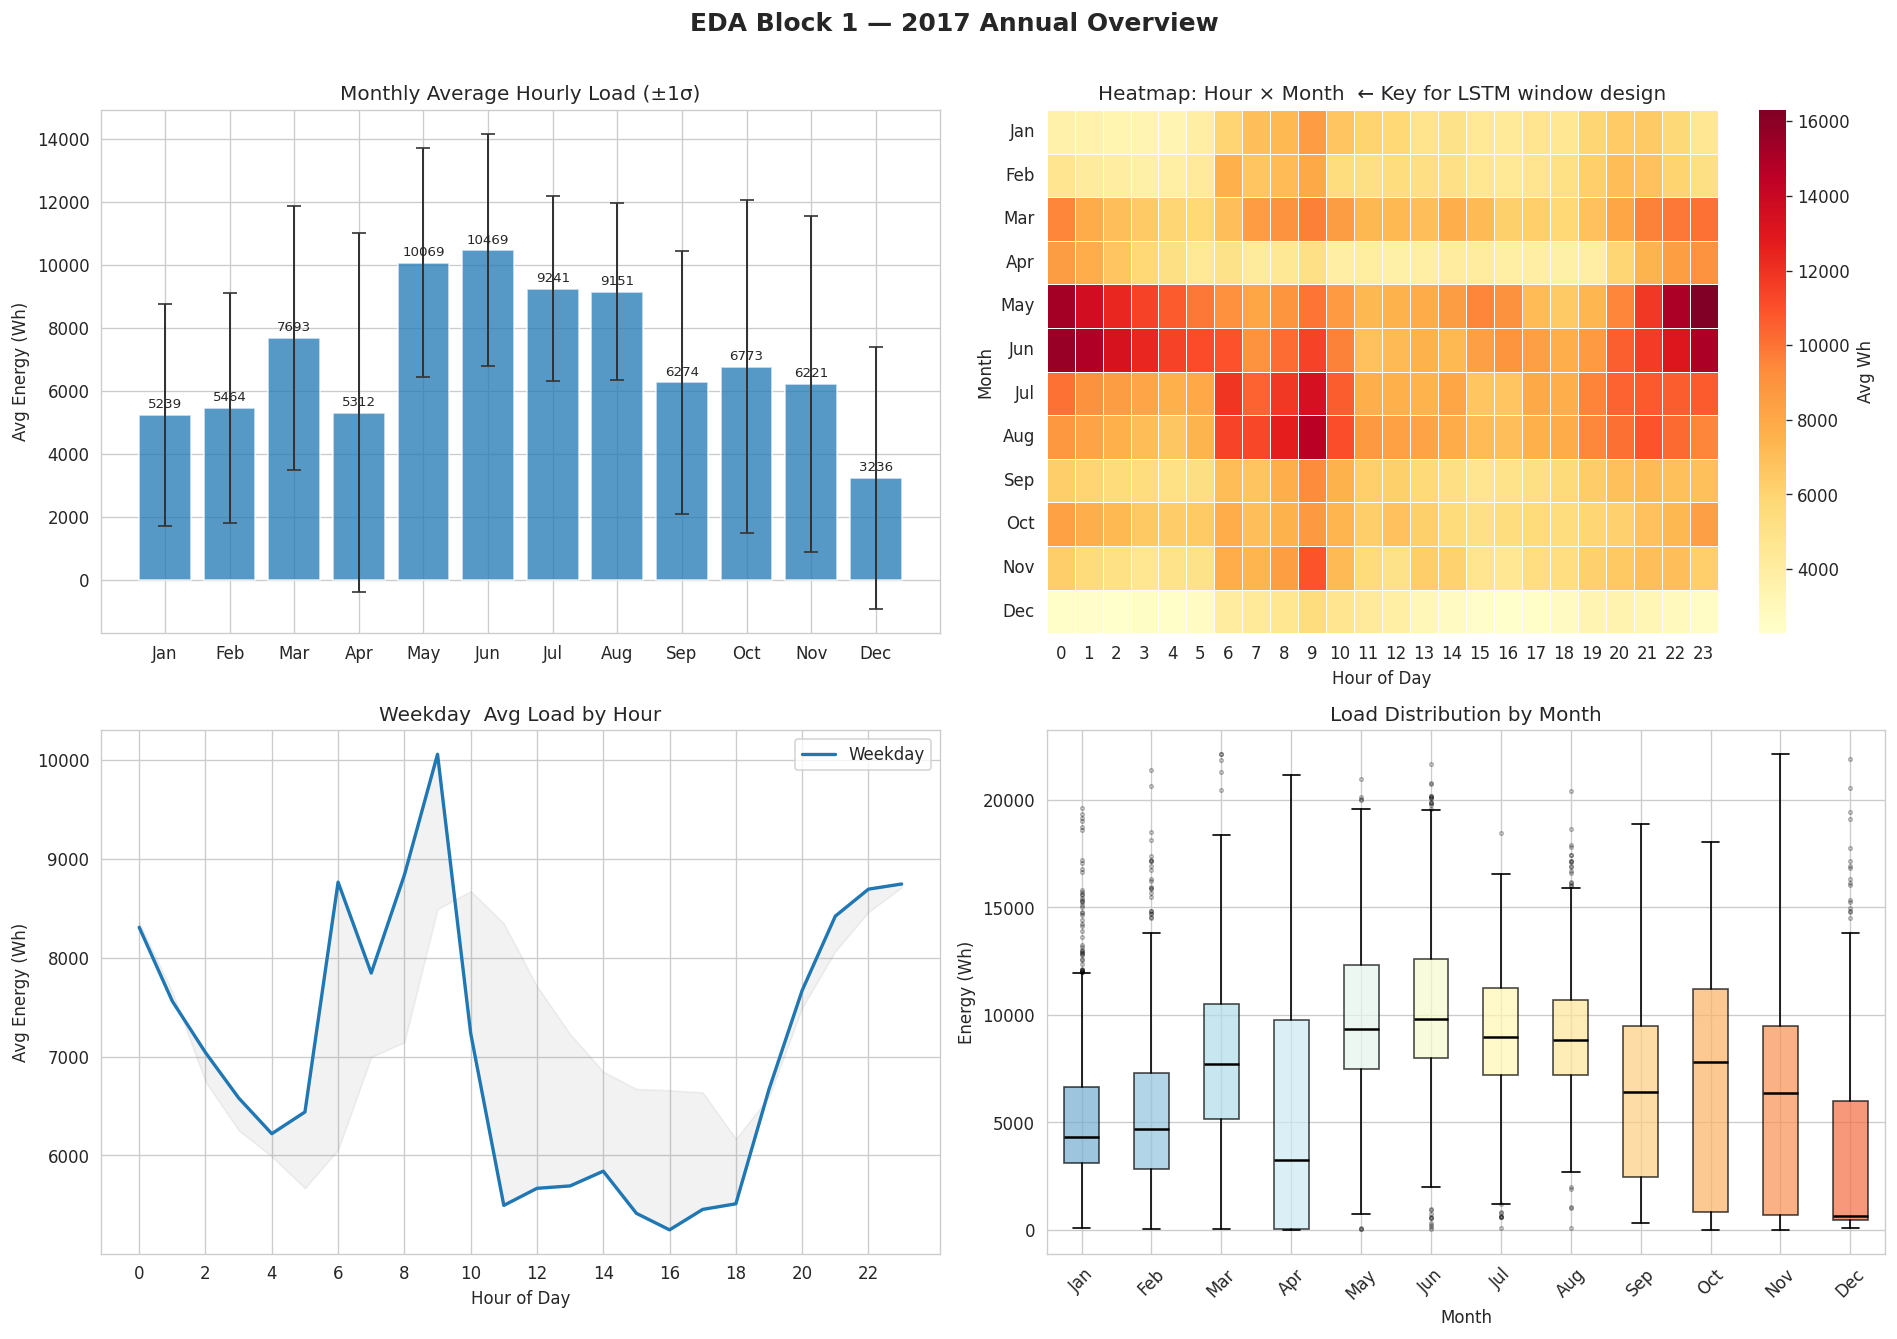

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 120

# ═══════════════════════════════════════════════════════
# EDA BLOCK 1 — Overview: monthly trend + distribution
# ═══════════════════════════════════════════════════════

month_names  = ['Jan','Feb','Mar','Apr','May','Jun',
                'Jul','Aug','Sep','Oct','Nov','Dec']
monthly_avg  = df_2017.groupby('month')['W'].mean()
monthly_std  = df_2017.groupby('month')['W'].std()

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("EDA Block 1 — 2017 Annual Overview", fontsize=15, fontweight='bold', y=1.01)

# ── Plot 1: Monthly average with error band ──────────────────────────────
ax = axes[0, 0]
x  = np.arange(1, 13)
ax.bar(x, monthly_avg.values, color='#1f77b4', alpha=0.75, zorder=2)
ax.errorbar(x, monthly_avg.values, yerr=monthly_std.values,
            fmt='none', color='#333', capsize=4, linewidth=1.2, zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(month_names)
ax.set_title("Monthly Average Hourly Load (±1σ)")
ax.set_ylabel("Avg Energy (Wh)")
for xi, val in zip(x, monthly_avg.values):
    ax.text(xi, val + 120, f'{val:.0f}', ha='center', va='bottom', fontsize=8)

# ── Plot 2: Heatmap — Hour × Month (THE most important EDA chart) ────────
ax       = axes[0, 1]
pivot_hm = df_2017.groupby(['month', 'hour'])['W'].mean().unstack()
sns.heatmap(pivot_hm, cmap='YlOrRd', ax=ax,
            cbar_kws={'label': 'Avg Wh'},
            linewidths=0.3, linecolor='white')
ax.set_title("Heatmap: Hour × Month  ← Key for LSTM window design")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Month")
ax.set_yticklabels(month_names, rotation=0)

# ── Plot 3: Weekday vs Weekend by hour ───────────────────────────────────
ax      = axes[1, 0]
wd_we   = df_2017.groupby(['hour', 'is_weekend'])['W'].mean().unstack()
ax.plot(wd_we.index, wd_we[0], label='Weekday', color='#1f77b4', linewidth=2)
ax.fill_between(wd_we.index, wd_we[0], wd_we[1], alpha=0.1, color='gray')
ax.set_title("Weekday  Avg Load by Hour")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Avg Energy (Wh)")
ax.set_xticks(range(0, 24, 2))
ax.legend()

# ── Plot 4: Boxplot by month ─────────────────────────────────────────────
ax = axes[1, 1]
data_by_month = [df_2017[df_2017['month'] == m]['W'].values for m in range(1, 13)]
bp = ax.boxplot(data_by_month, patch_artist=True,
                flierprops=dict(marker='o', markersize=2, alpha=0.3, color='gray'),
                medianprops=dict(color='black', linewidth=1.5))
colors = plt.cm.RdYlBu_r(np.linspace(0.2, 0.8, 12))
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_xticklabels(month_names, rotation=45)
ax.set_title("Load Distribution by Month")
ax.set_ylabel("Energy (Wh)")
ax.set_xlabel("Month")

plt.tight_layout()
plt.show()

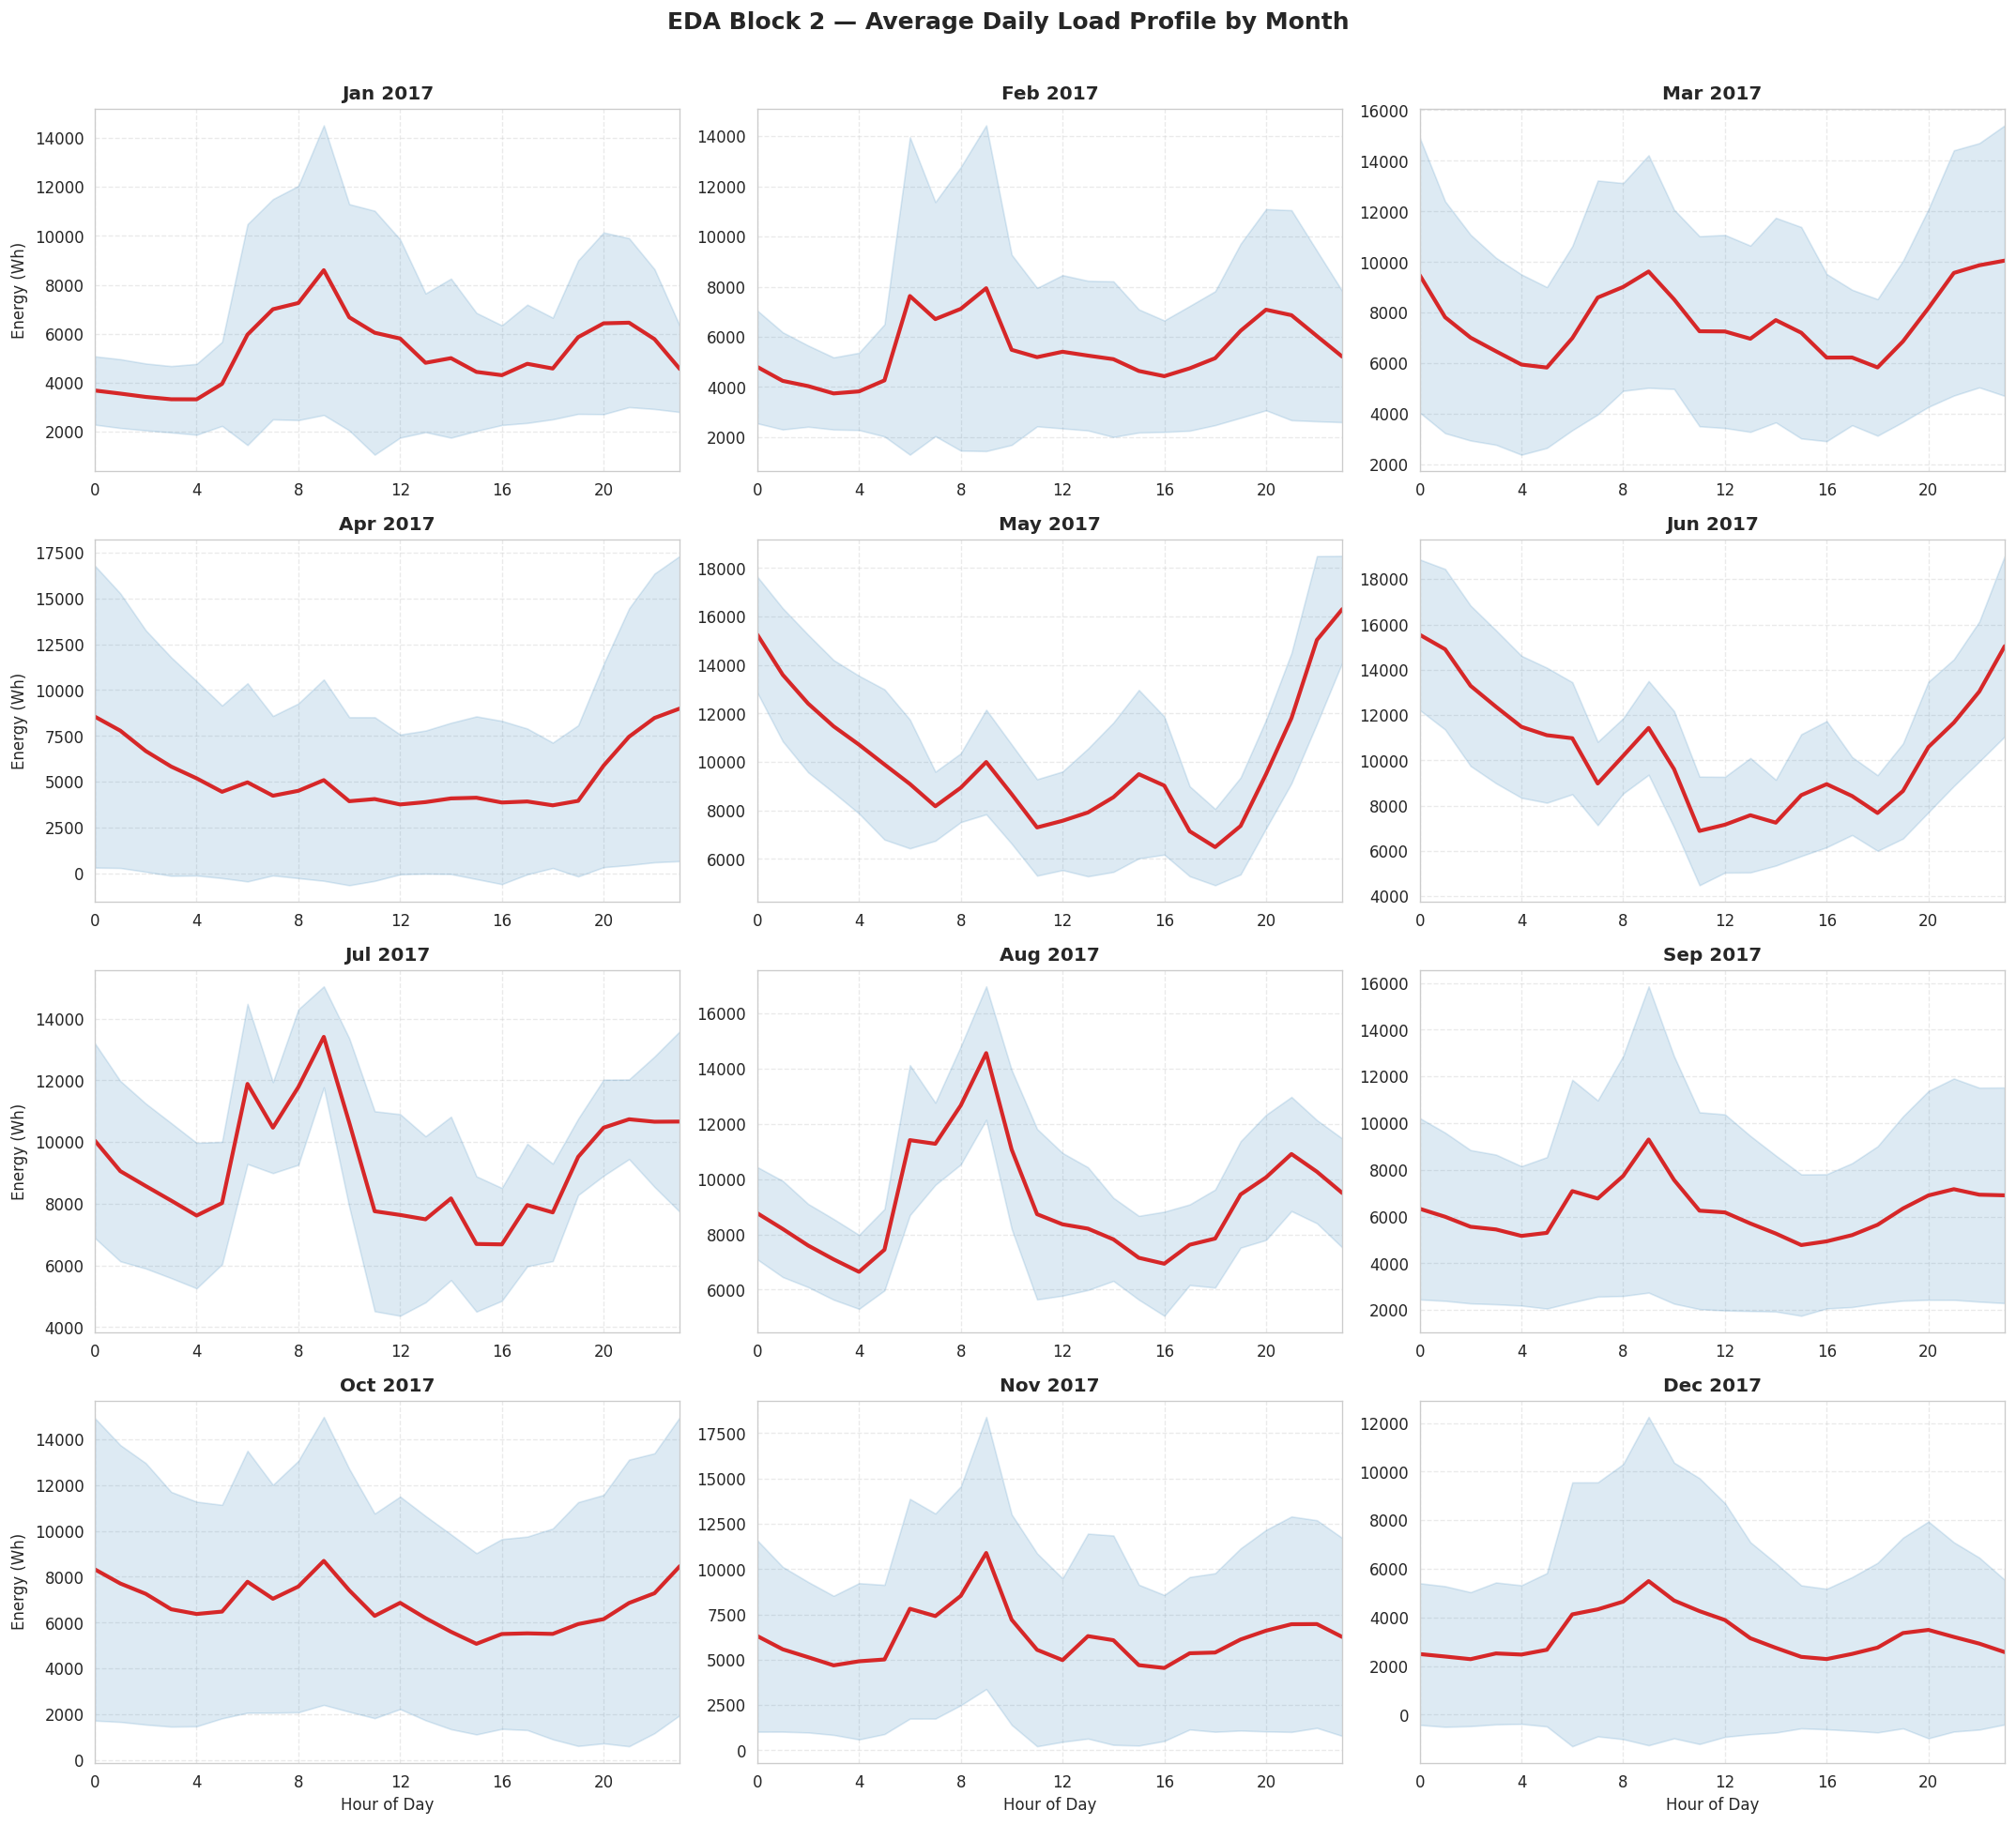

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(18, 16))
fig.suptitle("EDA Block 2 — Average Daily Load Profile by Month",
             fontsize=15, fontweight='bold', y=1.01)
axes = axes.flatten()

for i, m in enumerate(range(1, 13)):
    ax        = axes[i]
    month_df  = df_2017[df_2017['month'] == m]
    hourly_avg = month_df.groupby('hour')['W'].mean()
    hourly_std = month_df.groupby('hour')['W'].std()

    ax.plot(hourly_avg.index, hourly_avg.values,
            color='#d62728', linewidth=2.5, label='Mean')
    ax.fill_between(hourly_avg.index,
                    hourly_avg - hourly_std,
                    hourly_avg + hourly_std,
                    alpha=0.15, color='#1f77b4', label='±1σ')
    ax.set_title(f"{month_names[m-1]} 2017", fontsize=12, fontweight='bold')
    ax.set_xticks(range(0, 24, 4))
    ax.set_xlim(0, 23)
    ax.grid(True, alpha=0.4, linestyle='--')
    if i % 3 == 0:
        ax.set_ylabel("Energy (Wh)")
    if i >= 9:
        ax.set_xlabel("Hour of Day")

plt.tight_layout()
plt.show()


In [ ]:
# ═══════════════════════════════════════════════════════
# EDA BLOCK 3 — Print summary table
# ═══════════════════════════════════════════════════════

print("\n" + "="*60)
print("  EDA SUMMARY — 2017 (use this to guide LSTM decisions)")
print("="*60)

peak_m    = monthly_avg.idxmax()
low_m     = monthly_avg.idxmin()
peak_h    = df_2017.groupby('hour')['W'].mean().idxmax()
low_h     = df_2017.groupby('hour')['W'].mean().idxmin()
wd_avg    = df_2017[df_2017['is_weekend'] == 0]['W'].mean()
we_avg    = df_2017[df_2017['is_weekend'] == 1]['W'].mean()

print(f"  Peak month    : {month_names[peak_m-1]}  ({monthly_avg[peak_m]:.0f} Wh avg/hr)")
print(f"  Lowest month  : {month_names[low_m-1]}  ({monthly_avg[low_m]:.0f} Wh avg/hr)")
print(f"  Peak hour     : {peak_h}:00")
print(f"  Lowest hour   : {low_h}:00")
print(f"  Weekday avg   : {wd_avg:.0f} Wh")
print(f"  Weekend avg   : {we_avg:.0f} Wh")
print(f"  WD/WE diff    : {abs(wd_avg - we_avg):.0f} Wh  "
      f"({'weekday higher' if wd_avg > we_avg else 'weekend higher'})")
print(f"  W min / max   : {df_2017['W'].min():.1f} / {df_2017['W'].max():.1f} Wh")
print("="*60)
print("\n  LSTM DESIGN DECISIONS FROM THIS EDA:")
print(f"  → Two models: H1 (Jan–Jun) and H2 (Jul–Dec)")
print(f"  → Window = 24h (one full daily cycle as lookback)")
print(f"  → Features: W + hour_sin/cos + month_sin/cos + is_weekend")
print(f"  → Mask W < 100 Wh before computing MAPE/sMAPE")
print("="*60)



  EDA SUMMARY — 2017 (use this to guide LSTM decisions)
  Peak month    : Jun  (10469 Wh avg/hr)
  Lowest month  : Dec  (3236 Wh avg/hr)
  Peak hour     : 9:00
  Lowest hour   : 16:00
  Weekday avg   : 7058 Wh
  Weekend avg   : 7234 Wh
  WD/WE diff    : 176 Wh  (weekend higher)
  W min / max   : 0.3 / 22128.2 Wh

  LSTM DESIGN DECISIONS FROM THIS EDA:
  → Two models: H1 (Jan–Jun) and H2 (Jul–Dec)
  → Window = 24h (one full daily cycle as lookback)
  → Features: W + hour_sin/cos + month_sin/cos + is_weekend
  → Mask W < 100 Wh before computing MAPE/sMAPE


Train (H1): 4344 hours  (2017-01-01 → 2017-06-30)
Test  (H2): 4416  hours  (2017-07-01 → 2017-12-31)

X_train shape: (4320, 24, 6)
X_test  shape: (4416, 24, 6)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - loss: 0.0332 - val_loss: 0.0147 - learning_rate: 0.0010
Epoch 2/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 0.0220 - val_loss: 0.0127 - learning_rate: 0.0010
Epoch 3/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - loss: 0.0188 - val_loss: 0.0114 - learning_rate: 0.0010
Epoch 4/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0172 - val_loss: 0.0120 - learning_rate: 0.0010
Epoch 5/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0156 - val_loss: 0.0126 - learning_rate: 0.0010
Epoch 6/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0144 - val_loss: 0.0119 - learning_rate: 0.0010
Epoch 7/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 0.0137 - val_loss: 0.0098 - learning_rate: 0.0010
Epoch 8/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.0131 - val_loss: 0.0111 - learning_rate: 0.0010
Epoch 9/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - loss: 0.0121 - val_loss: 0.0097 - learning_rate: 0.0010
E

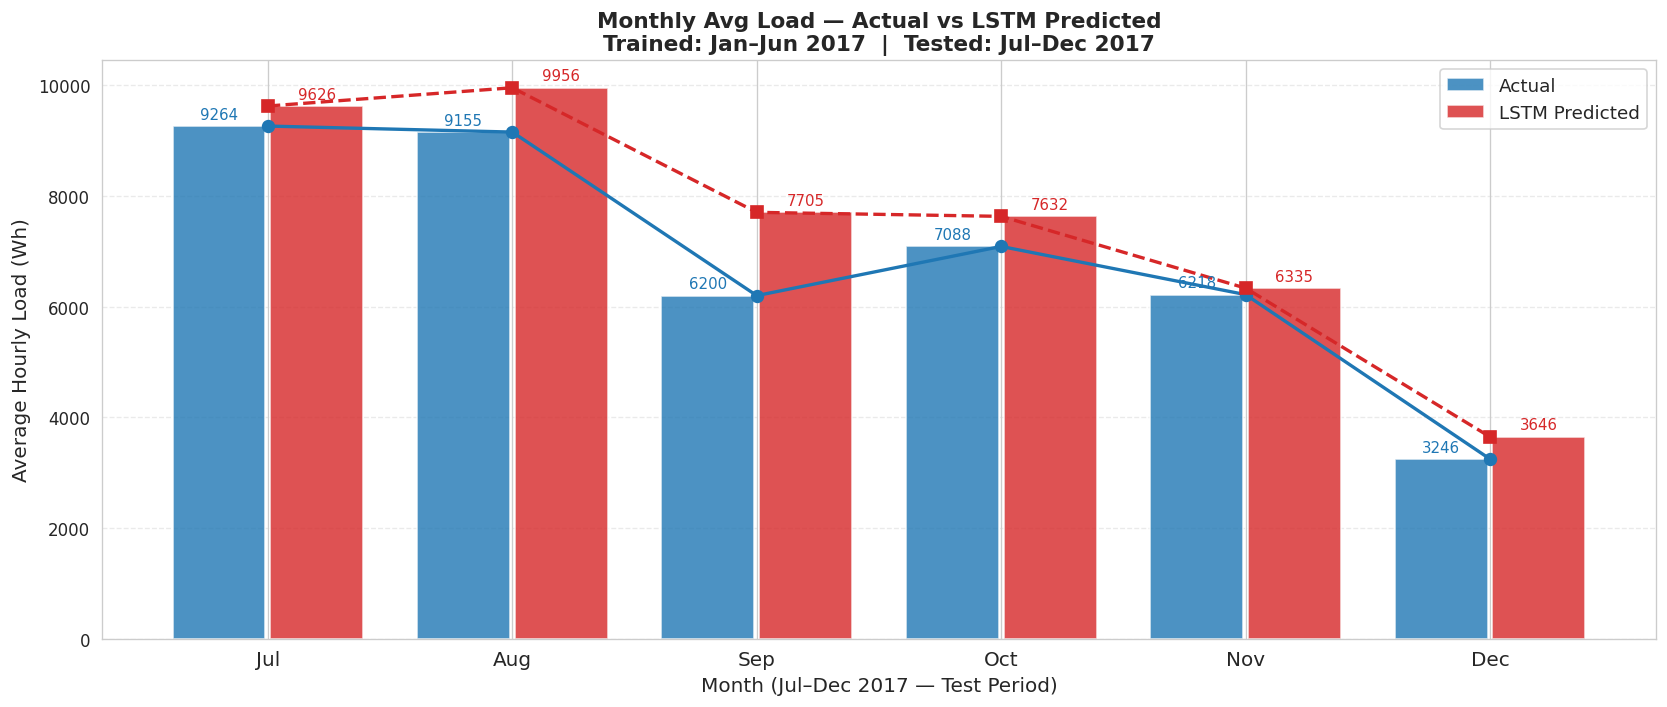

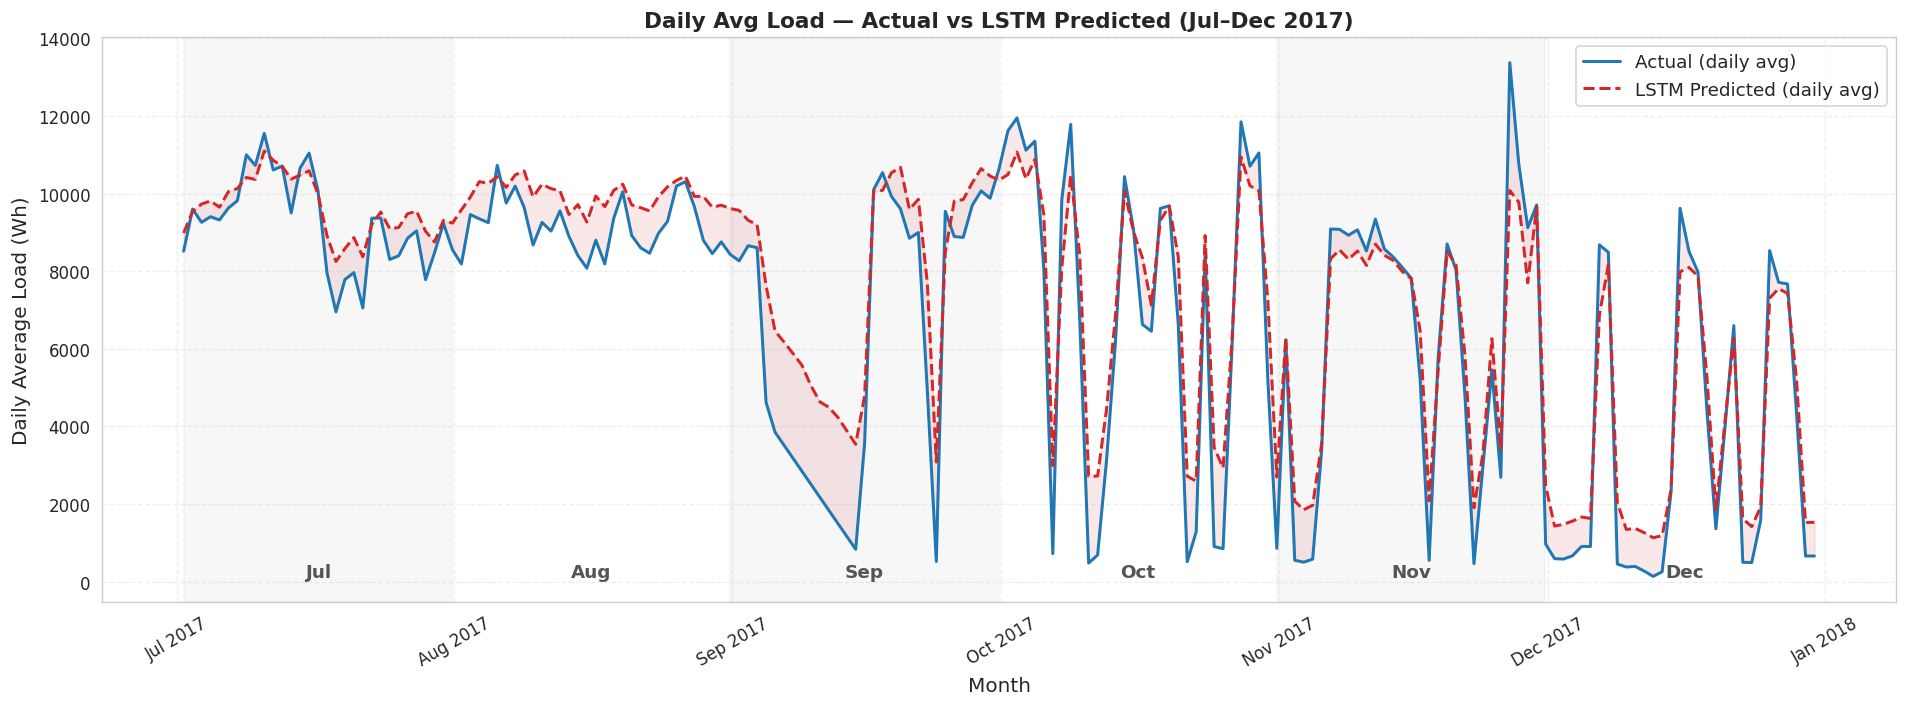

/tmp/ipykernel_1910/1675002713.py:220: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  monthly_mae  = df_result.groupby('month').apply(
/tmp/ipykernel_1910/1675002713.py:222: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  monthly_rmse = df_result.groupby('month').apply(


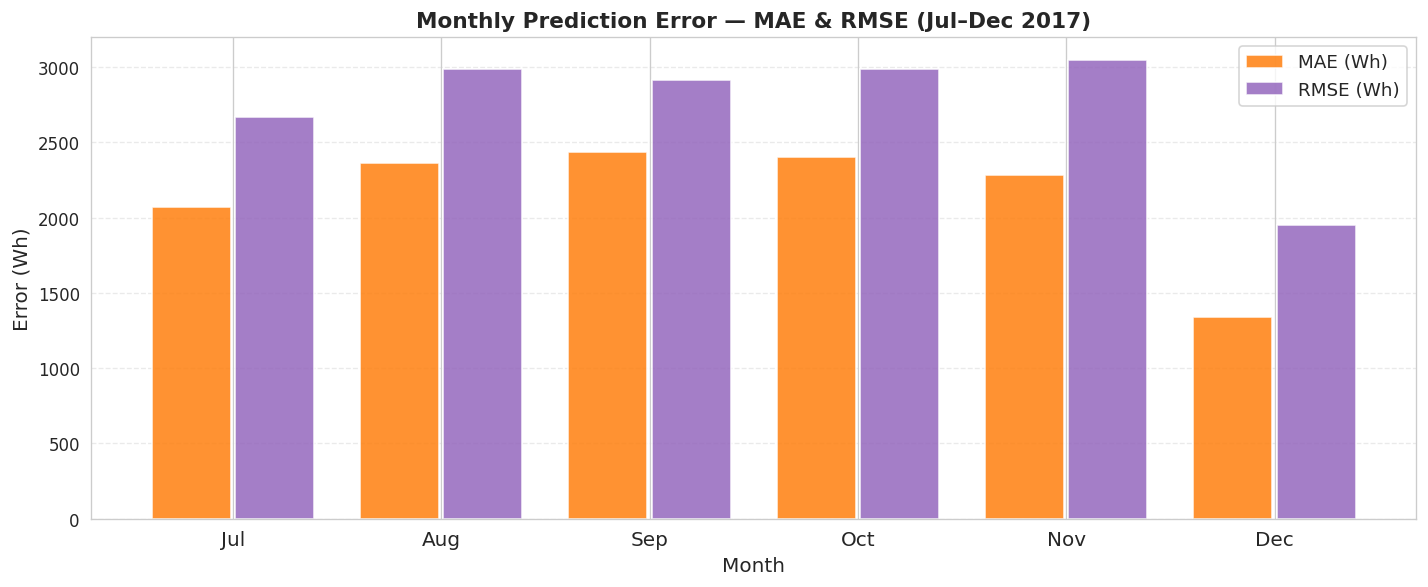


═════════════════════════════════════════════════════════════════
  MONTHLY BREAKDOWN  (Trained: Jan–Jun | Tested: Jul–Dec)
═════════════════════════════════════════════════════════════════
  Month      Actual   Predicted       MAE      RMSE   Error%
  ------------------------------------------------------------
  Jul         9264W       9626W     2068W     2666W    +3.9%↑
  Aug         9155W       9956W     2366W     2985W    +8.7%↑
  Sep         6200W       7705W     2434W     2913W   +24.3%↑
  Oct         7088W       7632W     2405W     2991W    +7.7%↑
  Nov         6218W       6335W     2284W     3048W    +1.9%↑
  Dec         3246W       3646W     1342W     1949W   +12.3%↑
═════════════════════════════════════════════════════════════════


In [ ]:
# ════════════════════════════════════════════════════════════════
# FIXED SPLIT: Train on Jan–Jun, Predict Jul–Dec
# → All 12 months appear in visualization
# ════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 120

FEATURES = ['W', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'is_weekend']
WINDOW   = 24
month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

# ── Step 1: Scale using H1 (training data only) ───────────────────────────
df_train = df_2017.loc['2017-01-01':'2017-06-30', FEATURES].copy()
df_test  = df_2017.loc['2017-07-01':'2017-12-31', FEATURES].copy()

# Fit scaler ONLY on training data — never leak test data into scaler
feature_scaler = MinMaxScaler()
train_scaled   = feature_scaler.fit_transform(df_train)

w_scaler = MinMaxScaler()
w_scaler.fit(df_train[['W']])

# Scale test using SAME scaler (fit on train)
test_scaled = feature_scaler.transform(df_test)

print(f"Train (H1): {len(df_train)} hours  ({df_train.index[0].date()} → {df_train.index[-1].date()})")
print(f"Test  (H2): {len(df_test)}  hours  ({df_test.index[0].date()} → {df_test.index[-1].date()})")

# ── Step 2: Build sequences ───────────────────────────────────────────────
def make_sequences(scaled_data, window):
    X, y = [], []
    for i in range(len(scaled_data) - window):
        X.append(scaled_data[i : i + window])
        y.append(scaled_data[i + window, 0])
    return np.array(X), np.array(y)

X_train, y_train = make_sequences(train_scaled, WINDOW)

# For test: seed the first window from end of training data
# This ensures continuity at the H1→H2 boundary
combined_scaled  = np.vstack([train_scaled[-WINDOW:], test_scaled])
X_test,  y_test  = make_sequences(combined_scaled, WINDOW)

print(f"\nX_train shape: {X_train.shape}")
print(f"X_test  shape: {X_test.shape}")

# ── Step 3: Build & train model ───────────────────────────────────────────
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(WINDOW, X_train.shape[2])),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                     patience=4, min_lr=1e-5, verbose=1)
]

history = model.fit(
    X_train, y_train,
    epochs=80,
    batch_size=32,
    validation_split=0.1,       # 10% of train for validation during training
    callbacks=callbacks,
    verbose=1
)
stopped_at = len(history.history['loss'])
print(f"\nStopped at epoch {stopped_at}/80")

# ── Step 4: Predict full H2 ───────────────────────────────────────────────
preds_scaled = model.predict(X_test, verbose=0)
y_actual     = w_scaler.inverse_transform(y_test.reshape(-1, 1))
y_preds      = w_scaler.inverse_transform(preds_scaled)

# Attach real timestamps — test sequences start from Jul 1
test_index = df_test.index[WINDOW:]    # first WINDOW rows used as seed
# Edge case: if lengths differ, trim to shorter
min_len    = min(len(test_index), len(y_actual))
test_index = test_index[:min_len]
y_actual   = y_actual[:min_len]
y_preds    = y_preds[:min_len]

df_result = pd.DataFrame({
    'actual'   : y_actual.flatten(),
    'predicted': y_preds.flatten()
}, index=test_index)
df_result['month'] = df_result.index.month

print(f"\nResult coverage: {df_result.index[0].date()} → {df_result.index[-1].date()}")
print(f"Months in result: {[month_names[m-1] for m in sorted(df_result['month'].unique())]}")

# ── Step 5: Metrics ───────────────────────────────────────────────────────
def safe_smape(a, p):
    denom = (np.abs(a) + np.abs(p)) / 2
    denom = np.where(denom < 1e-8, 1e-8, denom)
    return np.mean(np.abs(a - p) / denom) * 100

mask   = df_result['actual'] > 100
actual = df_result['actual'][mask].values
preds  = df_result['predicted'][mask].values

r2    = r2_score(actual, preds)
rmse  = np.sqrt(mean_squared_error(actual, preds))
mae   = mean_absolute_error(actual, preds)
smape = safe_smape(actual, preds)

print(f"\n{'═'*40}")
print(f"  OVERALL TEST METRICS (Jul–Dec)")
print(f"{'═'*40}")
print(f"  R²     : {r2:.4f}  {'✓' if r2 > 0.85 else '← retrain with LSTM_U1=128'}")
print(f"  RMSE   : {rmse:.2f} Wh")
print(f"  MAE    : {mae:.2f} Wh")
print(f"  sMAPE  : {smape:.2f}%  {'✓' if smape < 20 else '← check window size'}")
print(f"{'═'*40}")

# ════════════════════════════════════════════════════════════════
# PLOT 1 — Monthly avg bar chart (NOW ALL 6 TEST MONTHS VISIBLE)
# ════════════════════════════════════════════════════════════════

monthly_actual = df_result.groupby('month')['actual'].mean()
monthly_pred   = df_result.groupby('month')['predicted'].mean()
months_present = sorted(df_result['month'].unique())
labels         = [month_names[m-1] for m in months_present]
x              = np.arange(len(months_present))

fig, ax = plt.subplots(figsize=(14, 6))
bars_a = ax.bar(x - 0.2, monthly_actual.values, width=0.38,
                label='Actual', color='#1f77b4', alpha=0.8, zorder=2)
bars_p = ax.bar(x + 0.2, monthly_pred.values,   width=0.38,
                label='LSTM Predicted', color='#d62728', alpha=0.8, zorder=2)
ax.plot(x, monthly_actual.values, color='#1f77b4',
        marker='o', linewidth=2, markersize=7, zorder=3)
ax.plot(x, monthly_pred.values,   color='#d62728',
        marker='s', linewidth=2, markersize=7, linestyle='--', zorder=3)

for bar in bars_a:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80,
            f'{bar.get_height():.0f}', ha='center', va='bottom',
            fontsize=9, color='#1f77b4')
for bar in bars_p:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 80,
            f'{bar.get_height():.0f}', ha='center', va='bottom',
            fontsize=9, color='#d62728')

ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel("Average Hourly Load (Wh)", fontsize=12)
ax.set_xlabel("Month (Jul–Dec 2017 — Test Period)", fontsize=12)
ax.set_title("Monthly Avg Load — Actual vs LSTM Predicted\n"
             "Trained: Jan–Jun 2017  |  Tested: Jul–Dec 2017",
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, axis='y', alpha=0.4, linestyle='--')
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# PLOT 2 — Daily avg time series with month shading
# ════════════════════════════════════════════════════════════════

daily_actual = df_result['actual'].resample('D').mean()
daily_pred   = df_result['predicted'].resample('D').mean()

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(daily_actual.index, daily_actual.values,
        color='#1f77b4', linewidth=1.8, label='Actual (daily avg)')
ax.plot(daily_pred.index,   daily_pred.values,
        color='#d62728', linewidth=1.8, linestyle='--',
        label='LSTM Predicted (daily avg)')
ax.fill_between(daily_actual.index, daily_actual.values,
                daily_pred.values, alpha=0.10, color='#d62728')

for k, m in enumerate(months_present):
    m_data = df_result[df_result['month'] == m]
    start  = m_data.index[0]
    end    = m_data.index[-1]
    if k % 2 == 0:
        ax.axvspan(start, end, alpha=0.06, color='gray')
    mid = start + (end - start) / 2
    ax.text(mid, daily_actual.min() * 0.85,
            month_names[m-1], ha='center', fontsize=11,
            color='#555', fontweight='bold')

ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=30, fontsize=10)
ax.set_ylabel("Daily Average Load (Wh)", fontsize=12)
ax.set_xlabel("Month", fontsize=12)
ax.set_title("Daily Avg Load — Actual vs LSTM Predicted (Jul–Dec 2017)",
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.35, linestyle='--')
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# PLOT 3 — Monthly error bars
# ════════════════════════════════════════════════════════════════

monthly_mae  = df_result.groupby('month').apply(
    lambda g: mean_absolute_error(g['actual'], g['predicted']))
monthly_rmse = df_result.groupby('month').apply(
    lambda g: np.sqrt(mean_squared_error(g['actual'], g['predicted'])))

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - 0.2, monthly_mae.values,  width=0.38,
       label='MAE (Wh)',  color='#ff7f0e', alpha=0.85)
ax.bar(x + 0.2, monthly_rmse.values, width=0.38,
       label='RMSE (Wh)', color='#9467bd', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel("Error (Wh)", fontsize=12)
ax.set_xlabel("Month", fontsize=12)
ax.set_title("Monthly Prediction Error — MAE & RMSE (Jul–Dec 2017)",
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, axis='y', alpha=0.4, linestyle='--')
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# MONTHLY SUMMARY TABLE
# ════════════════════════════════════════════════════════════════

print("\n" + "═"*65)
print("  MONTHLY BREAKDOWN  (Trained: Jan–Jun | Tested: Jul–Dec)")
print("═"*65)
print(f"  {'Month':<6} {'Actual':>10} {'Predicted':>11} "
      f"{'MAE':>9} {'RMSE':>9} {'Error%':>8}")
print(f"  {'-'*60}")
for m in months_present:
    a    = monthly_actual[m]
    p    = monthly_pred[m]
    mae  = monthly_mae[m]
    rmse = monthly_rmse[m]
    err  = ((p - a) / a) * 100
    flag = "↑" if err > 0 else "↓"
    print(f"  {month_names[m-1]:<6} {a:>9.0f}W  {p:>9.0f}W  "
          f"{mae:>7.0f}W  {rmse:>7.0f}W  {err:>+6.1f}%{flag}")
print("═"*65)

Train hours : 4344
Test  hours : 4416

Train sequences (days): 173
Test  sequences (days): 183
X_train shape: (173, 168, 6)  → (days, 168h, 6 features)
y_train shape: (173, 24)  → (days, 24h)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 128)            │        69,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 24, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 24, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 24, 1)          │            65 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,593 (463.25 KB)

 Trainable params: 118,593 (463.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/80
10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 208ms/step - loss: 0.0662 - val_loss: 0.0604 - learning_rate: 0.0010
Epoch 2/80
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0413 - val_loss: 0.0402 - learning_rate: 0.0010
Epoch 3/80
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - loss: 0.0392 - val_loss: 0.0367 - learning_rate: 0.0010
Epoch 4/80
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0357 - val_loss: 0.0342 - learning_rate: 0.0010
Epoch 5/80
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - loss: 0.0334 - val_loss: 0.0314 - learning_rate: 0.0010
Epoch 6/80
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - loss: 0.0334 - val_loss: 0.0317 - learning_rate: 0.0010
Epoch 7/80
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 111ms/step - loss: 0.0334 - val_loss: 0.0260 - learning_rate: 0.0010
Epoch 8/80
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - loss: 0.0310 - val_loss: 0.0251 - learning_rate: 0.0010
Epoch 9/80
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 186ms/step - loss: 0.0302 - val_loss: 0.0215 - learning_rate: 0.0010
Epoch 10/8

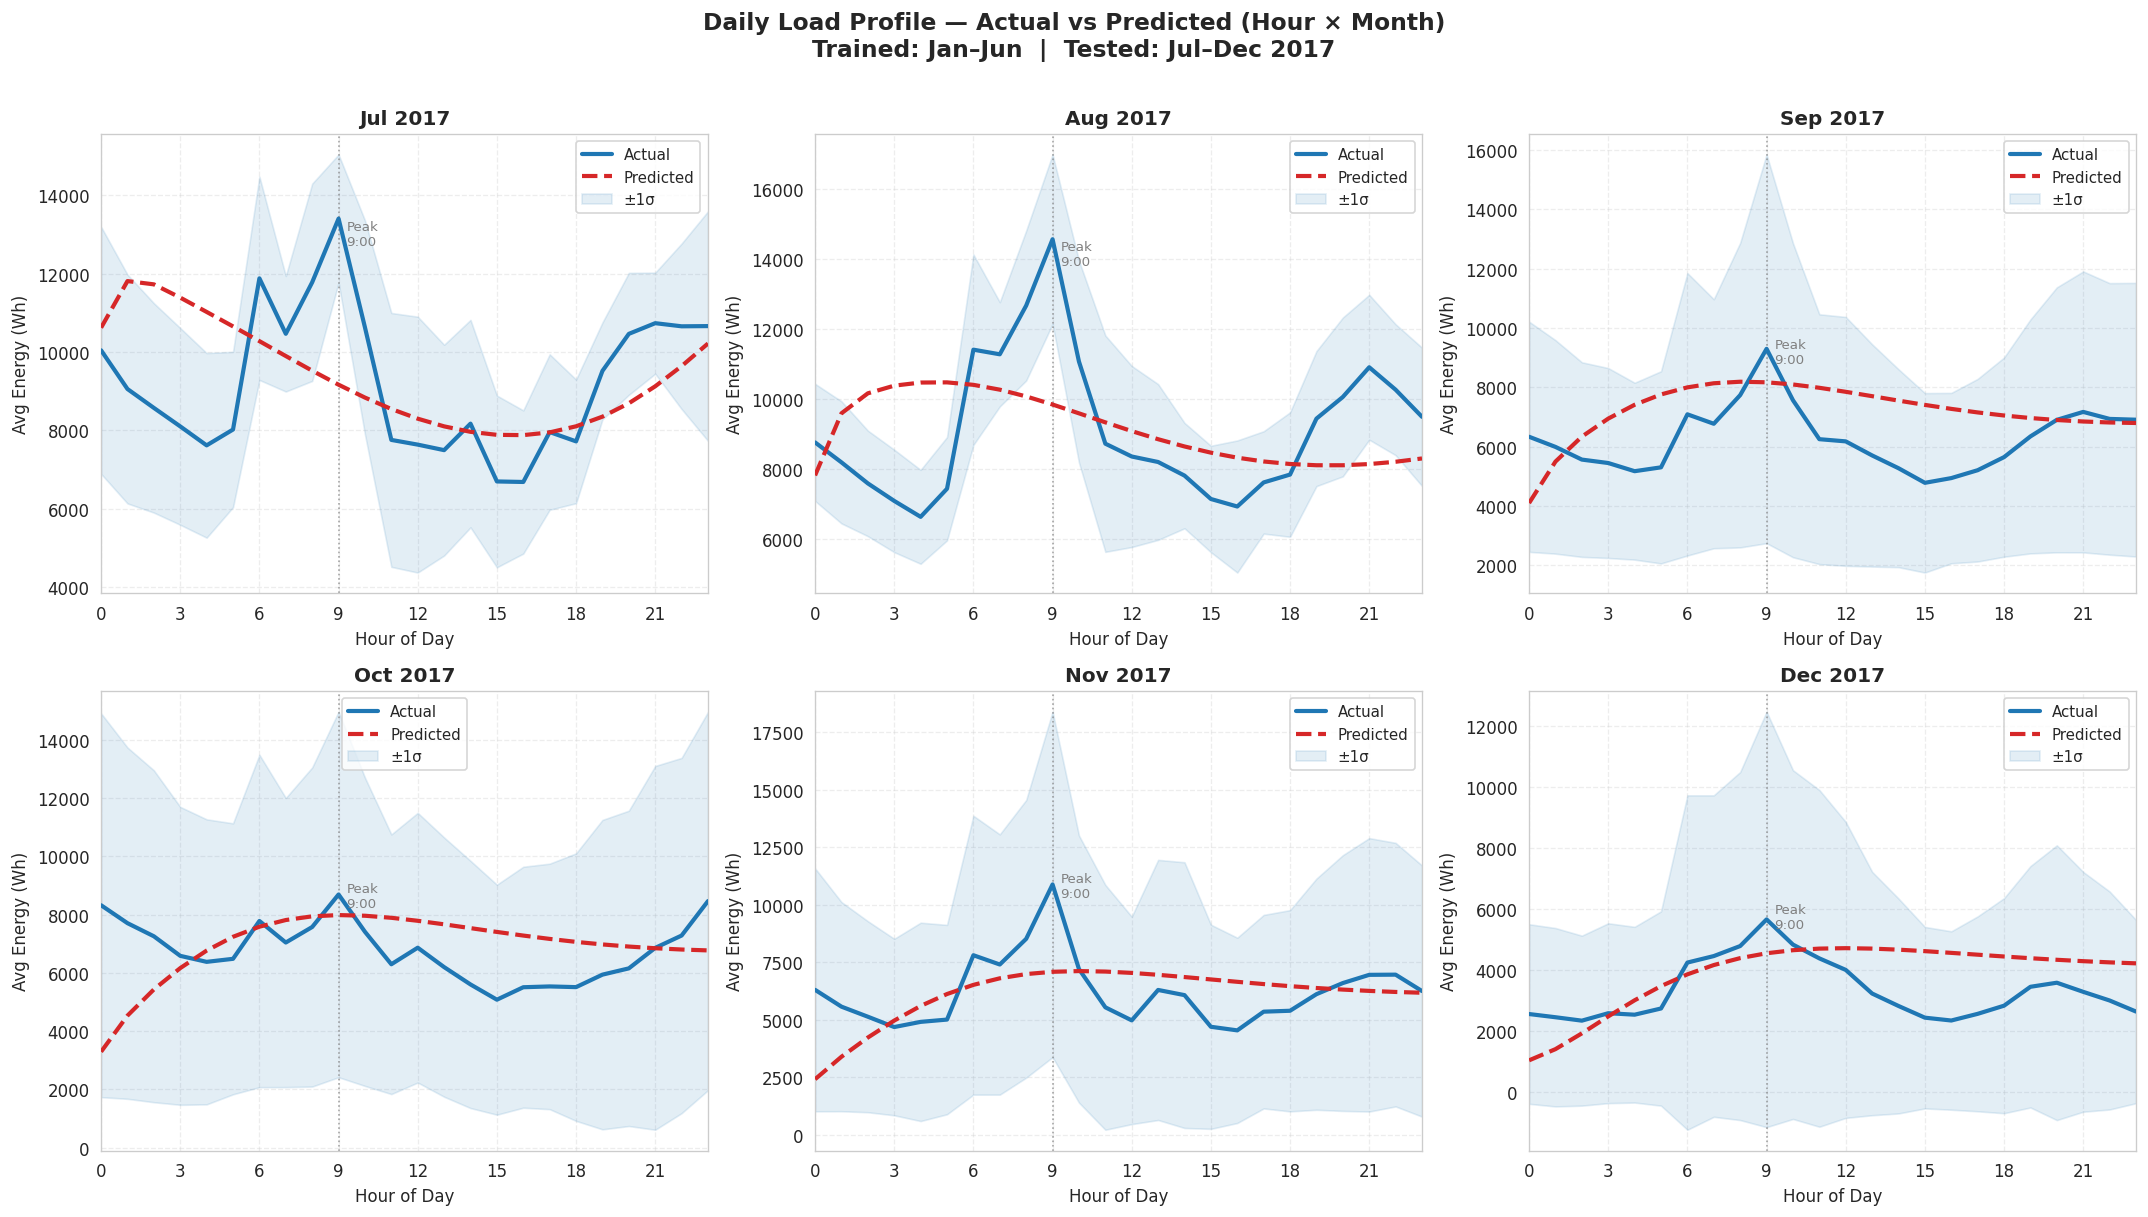

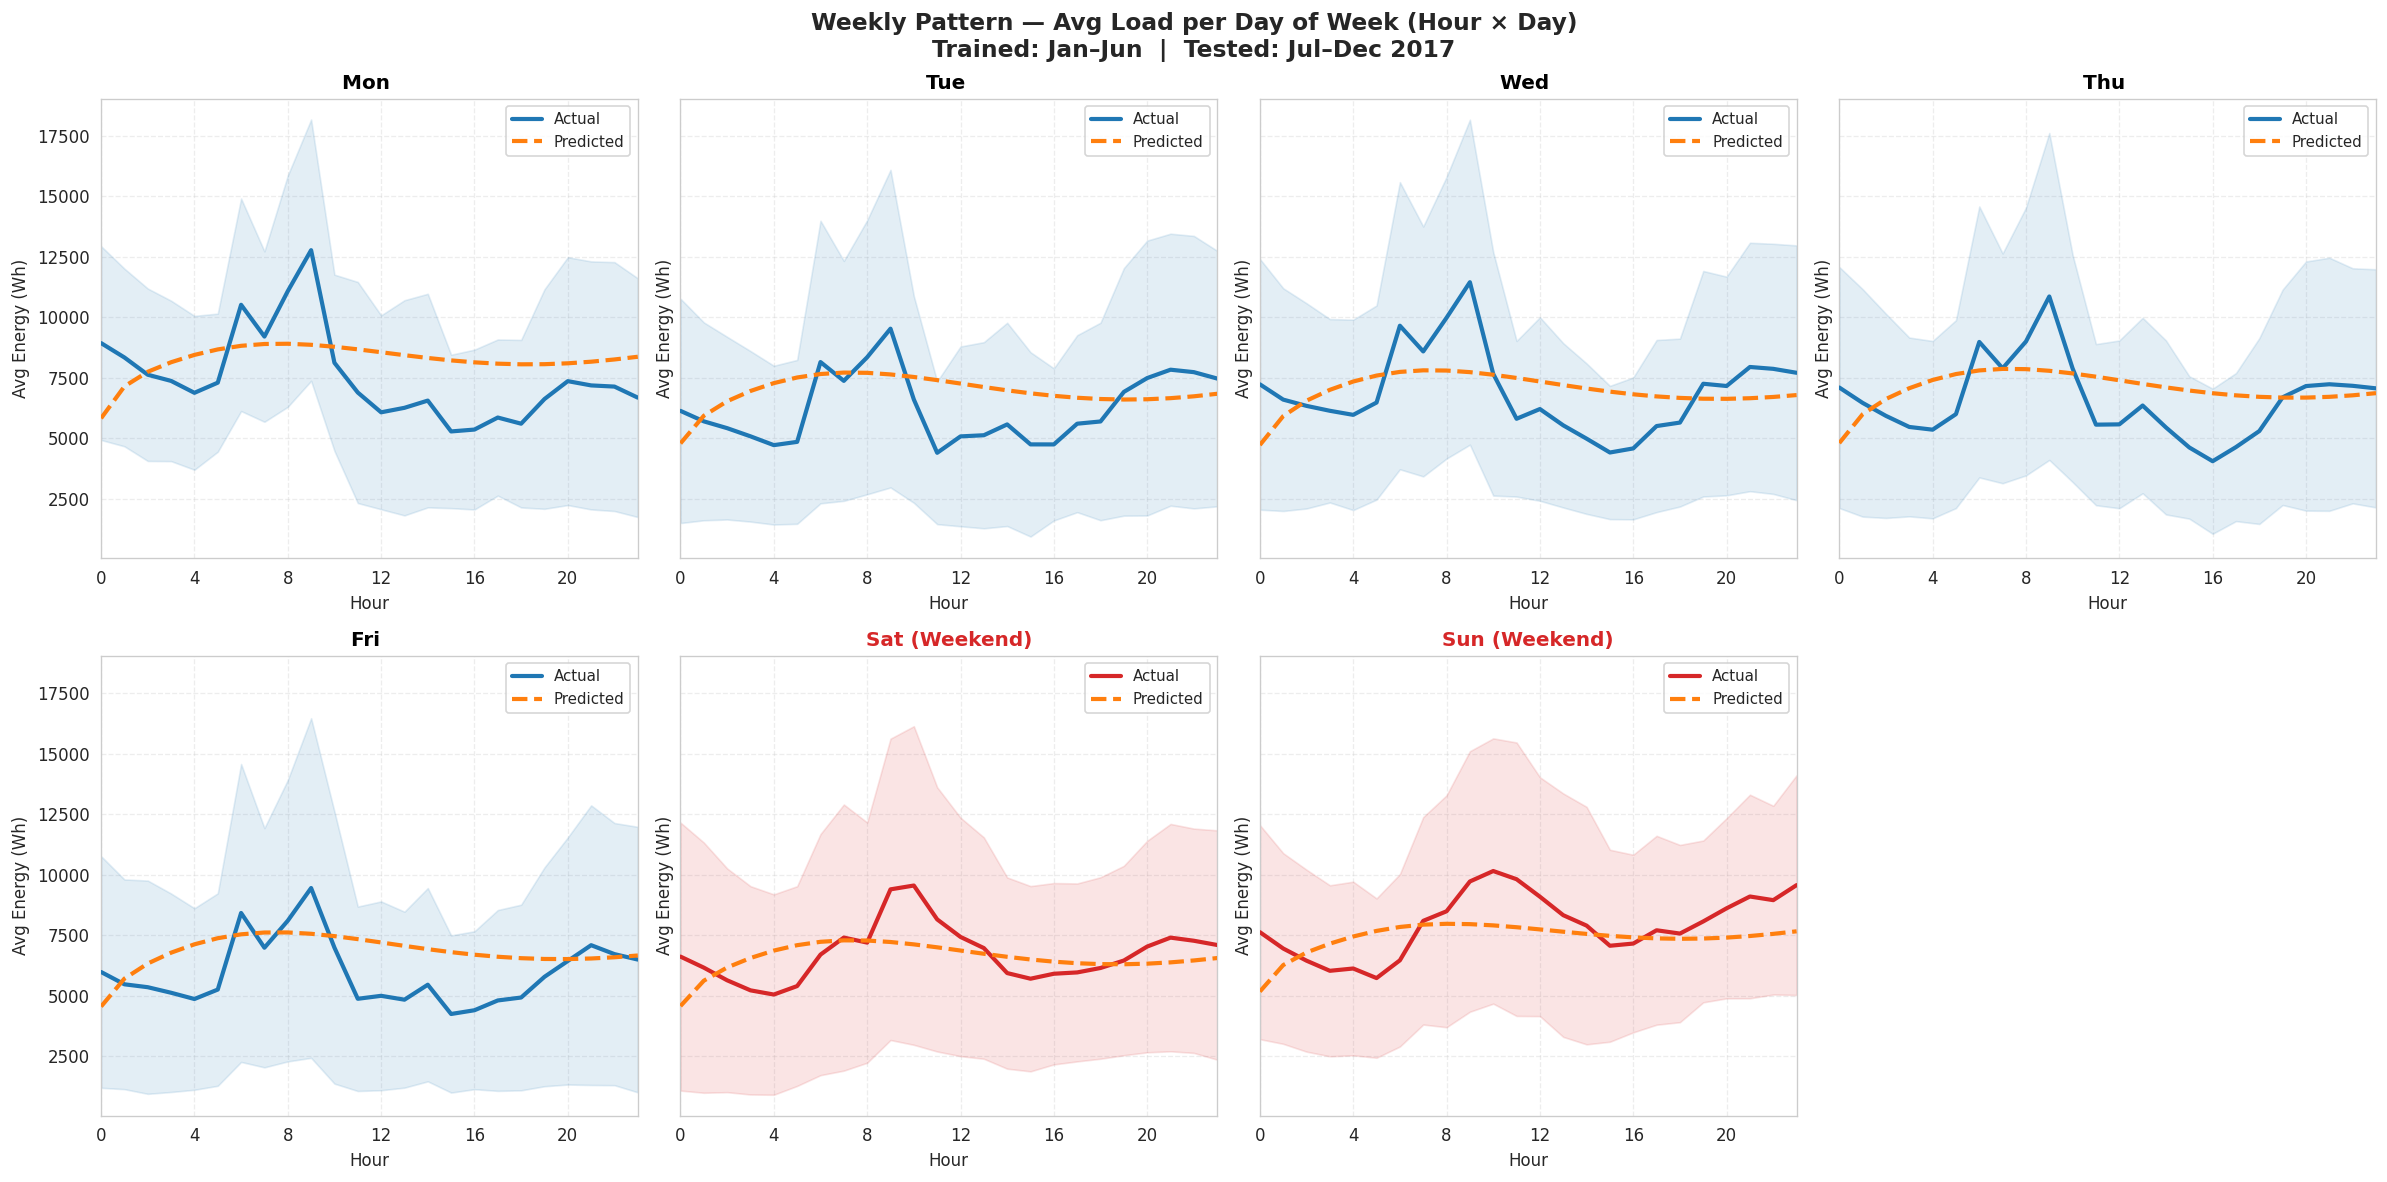

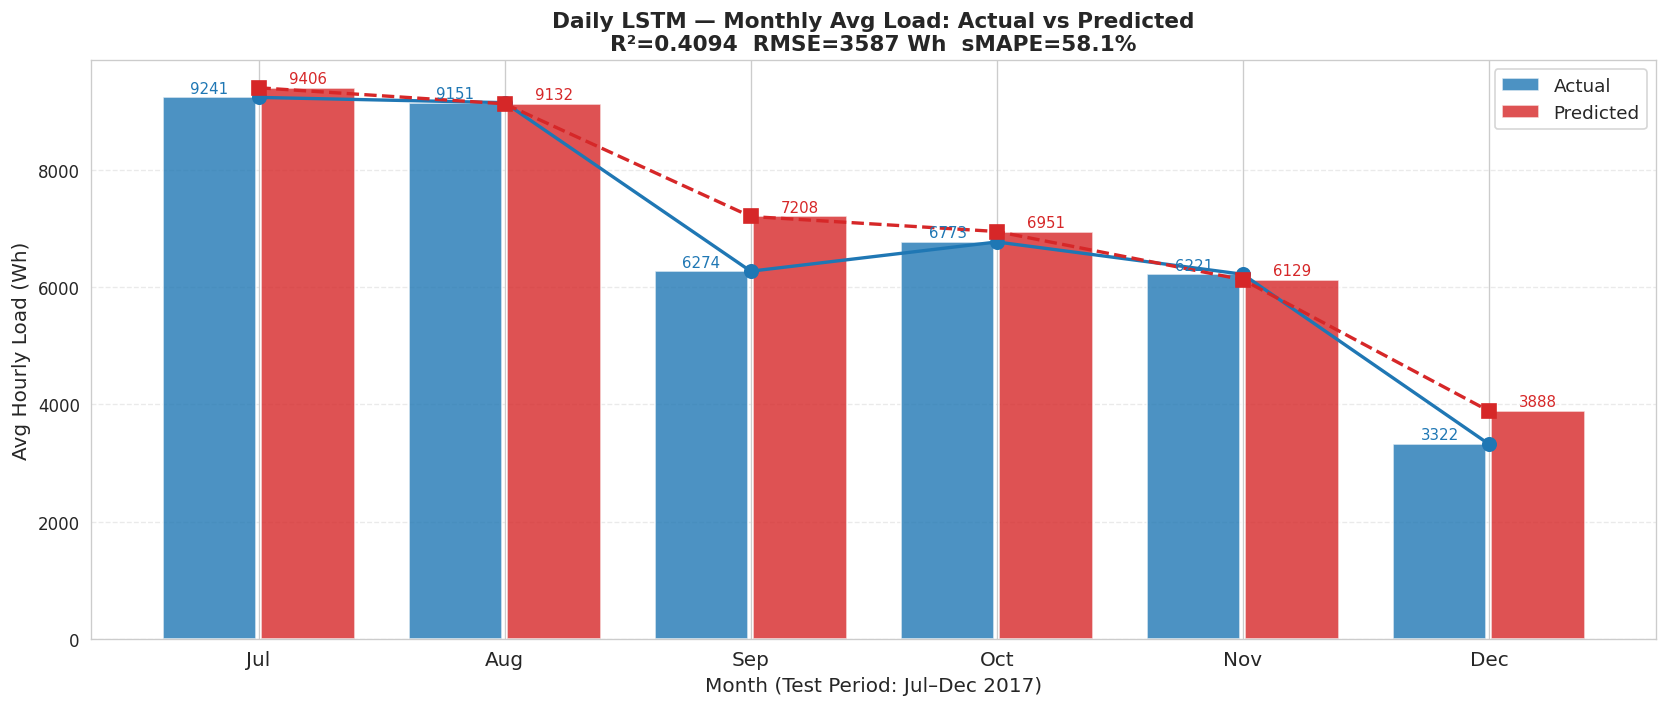


═════════════════════════════════════════════════════════════════
  DAILY MODEL — Monthly Breakdown
═════════════════════════════════════════════════════════════════
  Month      Actual   Predicted       MAE      RMSE   Diff%
  ------------------------------------------------------------
  Jul         9241Wh      9406Wh     2324Wh     2917Wh    +1.8%
  Aug         9151Wh      9132Wh     2292Wh     2855Wh    -0.2%
  Sep         6274Wh      7208Wh     2790Wh     3296Wh   +14.9%
  Oct         6773Wh      6951Wh     3460Wh     4362Wh    +2.6%
  Nov         6221Wh      6129Wh     3392Wh     4424Wh    -1.5%
  Dec         3322Wh      3888Wh     2484Wh     3329Wh   +17.0%
═════════════════════════════════════════════════════════════════


/tmp/ipykernel_1910/3337049951.py:327: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  monthly_mae  = df_daily_result.groupby('month').apply(
/tmp/ipykernel_1910/3337049951.py:329: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  monthly_rmse = df_daily_result.groupby('month').apply(


In [ ]:
# ════════════════════════════════════════════════════════════════
# DAILY LSTM — Train Jan–Jun, Predict Jul–Dec
# Predicts full next-day 24-hour load profile
# ════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, RepeatVector, TimeDistributed
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 120

FEATURES    = ['W', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'is_weekend']
WINDOW      = 168     # 7 days lookback
PRED_HOURS  = 24      # predict full next day
month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']
day_names   = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']

# ── Step 1: Prepare data ──────────────────────────────────────────────────
df_train = df_2017.loc['2017-01-01':'2017-06-30', FEATURES].copy()
df_test  = df_2017.loc['2017-07-01':'2017-12-31', FEATURES].copy()

feat_scaler = MinMaxScaler()
train_sc    = feat_scaler.fit_transform(df_train)

w_scaler = MinMaxScaler()
w_scaler.fit(df_train[['W']])

# Seed test with last WINDOW hours of train for continuity
test_sc = feat_scaler.transform(df_test)
combined_sc = np.vstack([train_sc[-WINDOW:], test_sc])

print(f"Train hours : {len(df_train)}")
print(f"Test  hours : {len(df_test)}")

# ── Step 2: Build daily sequences ─────────────────────────────────────────
# X = 7 days of history (168 hours, all 6 features)
# y = next 24 hours of W only

def make_daily_sequences(data, window, pred_hours):
    X, y = [], []
    # Step by 24 so each sequence predicts one full day
    for i in range(0, len(data) - window - pred_hours, pred_hours):
        X.append(data[i : i + window])                        # (168, 6)
        y.append(data[i + window : i + window + pred_hours, 0])  # (24,)
    return np.array(X), np.array(y)

# Train sequences from training data only
X_train, y_train = make_daily_sequences(train_sc, WINDOW, PRED_HOURS)

# Test sequences from combined (seeded) data
X_test_raw, y_test_raw = make_daily_sequences(combined_sc, WINDOW, PRED_HOURS)

# Map test sequences to real dates
# Each sequence predicts one full day — find those days in df_test
test_day_starts = []
for i in range(0, len(test_sc) - PRED_HOURS, PRED_HOURS):
    test_day_starts.append(df_test.index[i])

n_test = min(len(X_test_raw), len(test_day_starts))
X_test = X_test_raw[:n_test]
y_test = y_test_raw[:n_test]
test_dates = test_day_starts[:n_test]

print(f"\nTrain sequences (days): {len(X_train)}")
print(f"Test  sequences (days): {len(X_test)}")
print(f"X_train shape: {X_train.shape}  → (days, 168h, 6 features)")
print(f"y_train shape: {y_train.shape}  → (days, 24h)")

# ── Step 3: Build model ───────────────────────────────────────────────────
# Encoder–Decoder LSTM — best for multi-step output
# Encoder reads 168h history, Decoder outputs 24h forecast

model = Sequential([
    # Encoder — compress 168h of history
    LSTM(128, return_sequences=False,
         input_shape=(WINDOW, X_train.shape[2])),
    Dropout(0.2),

    # Bridge — repeat encoded vector 24 times (once per output hour)
    RepeatVector(PRED_HOURS),

    # Decoder — generate 24 hourly predictions
    LSTM(64, return_sequences=True),
    Dropout(0.2),

    # Output — one W value per hour
    TimeDistributed(Dense(1))
])
model.compile(optimizer='adam', loss='mse')
model.summary()

# ── Step 4: Train ─────────────────────────────────────────────────────────
callbacks = [
    EarlyStopping(monitor='val_loss', patience=10,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                     patience=4, min_lr=1e-5, verbose=1)
]

history = model.fit(
    X_train, y_train,
    epochs=80,
    batch_size=16,          # smaller batch — sequences are bigger (168 steps)
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)
stopped = len(history.history['loss'])
print(f"\nStopped at epoch {stopped}/80")

# ── Step 5: Predict ───────────────────────────────────────────────────────
preds_sc = model.predict(X_test, verbose=0)       # shape (n_days, 24, 1)
preds_sc = preds_sc.squeeze(-1)                    # shape (n_days, 24)

# Invert scaling day by day
y_actual_all = []
y_preds_all  = []

for d in range(len(y_test)):
    actual_day = w_scaler.inverse_transform(
        y_test[d].reshape(-1, 1)).flatten()        # (24,)
    pred_day   = w_scaler.inverse_transform(
        preds_sc[d].reshape(-1, 1)).flatten()      # (24,)
    y_actual_all.append(actual_day)
    y_preds_all.append(pred_day)

y_actual_all = np.array(y_actual_all)              # (n_days, 24)
y_preds_all  = np.array(y_preds_all)               # (n_days, 24)

# Build hourly result DataFrame with real timestamps
rows = []
for d, date in enumerate(test_dates):
    for h in range(PRED_HOURS):
        ts = date + pd.Timedelta(hours=h)
        rows.append({
            'datetime' : ts,
            'actual'   : y_actual_all[d, h],
            'predicted': y_preds_all[d, h],
            'month'    : ts.month,
            'day_name' : day_names[ts.dayofweek],
            'hour'     : h
        })

df_daily_result = pd.DataFrame(rows).set_index('datetime')
print(f"\nResult shape : {df_daily_result.shape}")
print(f"Coverage     : {df_daily_result.index[0].date()} → "
      f"{df_daily_result.index[-1].date()}")

# ── Step 6: Metrics ───────────────────────────────────────────────────────
def safe_smape(a, p):
    d = (np.abs(a) + np.abs(p)) / 2
    d = np.where(d < 1e-8, 1e-8, d)
    return np.mean(np.abs(a - p) / d) * 100

mask  = df_daily_result['actual'] > 100
a     = df_daily_result['actual'][mask].values
p     = df_daily_result['predicted'][mask].values

r2    = r2_score(a, p)
rmse  = np.sqrt(mean_squared_error(a, p))
mae   = mean_absolute_error(a, p)
smape = safe_smape(a, p)

print(f"\n{'═'*42}")
print(f"  DAILY MODEL — Overall Metrics")
print(f"{'═'*42}")
print(f"  R²    : {r2:.4f}")
print(f"  RMSE  : {rmse:.2f} Wh")
print(f"  MAE   : {mae:.2f} Wh")
print(f"  sMAPE : {smape:.2f}%")
print(f"{'═'*42}")

# ════════════════════════════════════════════════════════════════
# PLOT 1 — Average day profile per month
# (24-hour curve, actual vs predicted, one subplot per month)
# ════════════════════════════════════════════════════════════════

test_months  = sorted(df_daily_result['month'].unique())
n_months     = len(test_months)
ncols, nrows = 3, int(np.ceil(n_months / 3))

fig, axes = plt.subplots(nrows, ncols,
                          figsize=(18, nrows * 5), sharey=False)
axes = axes.flatten()
fig.suptitle("Daily Load Profile — Actual vs Predicted (Hour × Month)\n"
             "Trained: Jan–Jun  |  Tested: Jul–Dec 2017",
             fontsize=14, fontweight='bold', y=1.01)

for i, m in enumerate(test_months):
    ax     = axes[i]
    m_data = df_daily_result[df_daily_result['month'] == m]

    hourly_a   = m_data.groupby('hour')['actual'].mean()
    hourly_p   = m_data.groupby('hour')['predicted'].mean()
    hourly_std = m_data.groupby('hour')['actual'].std()

    ax.plot(hourly_a.index, hourly_a.values,
            color='#1f77b4', linewidth=2.5, label='Actual', zorder=3)
    ax.plot(hourly_p.index, hourly_p.values,
            color='#d62728', linewidth=2.5, linestyle='--',
            label='Predicted', zorder=3)
    ax.fill_between(hourly_a.index,
                    hourly_a - hourly_std,
                    hourly_a + hourly_std,
                    alpha=0.12, color='#1f77b4', label='±1σ')

    # Mark peak hour
    peak_h = hourly_a.idxmax()
    ax.axvline(x=peak_h, color='gray', linewidth=1,
               linestyle=':', alpha=0.7)
    ax.text(peak_h + 0.3, hourly_a.max() * 0.95,
            f'Peak\n{peak_h}:00', fontsize=8, color='gray')

    ax.set_title(f"{month_names[m-1]} 2017", fontsize=12, fontweight='bold')
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlim(0, 23)
    ax.set_xlabel("Hour of Day", fontsize=10)
    ax.set_ylabel("Avg Energy (Wh)", fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.35, linestyle='--')

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# PLOT 2 — Average day profile by day of week
# Mon–Sun pattern, actual vs predicted
# ════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(2, 4, figsize=(20, 10), sharey=True)
axes      = axes.flatten()
fig.suptitle("Weekly Pattern — Avg Load per Day of Week (Hour × Day)\n"
             "Trained: Jan–Jun  |  Tested: Jul–Dec 2017",
             fontsize=14, fontweight='bold')

for i, day in enumerate(day_names):
    ax     = axes[i]
    d_data = df_daily_result[df_daily_result['day_name'] == day]

    if len(d_data) == 0:
        axes[i].set_visible(False)
        continue

    ha  = d_data.groupby('hour')['actual'].mean()
    hp  = d_data.groupby('hour')['predicted'].mean()
    hsd = d_data.groupby('hour')['actual'].std()

    clr = '#d62728' if day in ['Sat','Sun'] else '#1f77b4'

    ax.plot(ha.index, ha.values, color=clr, linewidth=2.5,
            label='Actual', zorder=3)
    ax.plot(hp.index, hp.values, color='#ff7f0e', linewidth=2.5,
            linestyle='--', label='Predicted', zorder=3)
    ax.fill_between(ha.index, ha - hsd, ha + hsd,
                    alpha=0.12, color=clr)

    ax.set_title(f"{day} {'(Weekend)' if day in ['Sat','Sun'] else ''}",
                 fontsize=12, fontweight='bold',
                 color='#d62728' if day in ['Sat','Sun'] else 'black')
    ax.set_xticks(range(0, 24, 4))
    ax.set_xlim(0, 23)
    ax.set_xlabel("Hour", fontsize=10)
    ax.set_ylabel("Avg Energy (Wh)", fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.35, linestyle='--')

axes[-1].set_visible(False)   # hide 8th subplot (only 7 days)
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# PLOT 3 — Monthly avg bar (same as monthly model, for comparison)
# ════════════════════════════════════════════════════════════════

monthly_a = df_daily_result.groupby('month')['actual'].mean()
monthly_p = df_daily_result.groupby('month')['predicted'].mean()
labels    = [month_names[m-1] for m in test_months]
x         = np.arange(len(test_months))

fig, ax = plt.subplots(figsize=(14, 6))
b1 = ax.bar(x - 0.2, monthly_a.values, width=0.38,
            label='Actual', color='#1f77b4', alpha=0.8)
b2 = ax.bar(x + 0.2, monthly_p.values, width=0.38,
            label='Predicted', color='#d62728', alpha=0.8)
ax.plot(x, monthly_a.values, color='#1f77b4',
        marker='o', linewidth=2, markersize=8)
ax.plot(x, monthly_p.values, color='#d62728',
        marker='s', linewidth=2, markersize=8, linestyle='--')
for bar in b1:
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 80,
            f'{bar.get_height():.0f}',
            ha='center', fontsize=9, color='#1f77b4')
for bar in b2:
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 80,
            f'{bar.get_height():.0f}',
            ha='center', fontsize=9, color='#d62728')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylabel("Avg Hourly Load (Wh)", fontsize=12)
ax.set_xlabel("Month (Test Period: Jul–Dec 2017)", fontsize=12)
ax.set_title(f"Daily LSTM — Monthly Avg Load: Actual vs Predicted\n"
             f"R²={r2:.4f}  RMSE={rmse:.0f} Wh  sMAPE={smape:.1f}%",
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, axis='y', alpha=0.4, linestyle='--')
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# MONTHLY TABLE
# ════════════════════════════════════════════════════════════════

monthly_mae  = df_daily_result.groupby('month').apply(
    lambda g: mean_absolute_error(g['actual'], g['predicted']))
monthly_rmse = df_daily_result.groupby('month').apply(
    lambda g: np.sqrt(mean_squared_error(g['actual'], g['predicted'])))

print(f"\n{'═'*65}")
print(f"  DAILY MODEL — Monthly Breakdown")
print(f"{'═'*65}")
print(f"  {'Month':<6} {'Actual':>10} {'Predicted':>11}"
      f" {'MAE':>9} {'RMSE':>9} {'Diff%':>7}")
print(f"  {'-'*60}")
for m in test_months:
    a    = monthly_a[m]
    p    = monthly_p[m]
    err  = ((p - a) / a) * 100
    print(f"  {month_names[m-1]:<6} {a:>9.0f}Wh {p:>9.0f}Wh"
          f" {monthly_mae[m]:>8.0f}Wh {monthly_rmse[m]:>8.0f}Wh"
          f"  {err:>+6.1f}%")
print(f"{'═'*65}")

In [ ]:
# ════════════════════════════════════════════════════════════════
# BLOCK 1 — SETUP & DATA PREP (run this first, always)
# ════════════════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, RepeatVector, TimeDistributed
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 120

month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']
day_names   = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
FEATURES    = ['W','hour_sin','hour_cos','month_sin','month_cos','is_weekend']

train_raw = df_2017.loc['2017-01-01':'2017-06-30']
test_raw  = df_2017.loc['2017-07-01':'2017-12-31']
train_W   = train_raw['W']
test_W    = test_raw['W']

def calc_metrics(actual, predicted, label=""):
    mask  = np.array(actual) > 100
    a, p  = np.array(actual)[mask], np.array(predicted)[mask]
    r2    = r2_score(a, p)
    rmse  = np.sqrt(mean_squared_error(a, p))
    mae   = mean_absolute_error(a, p)
    denom = (np.abs(a) + np.abs(p)) / 2
    denom = np.where(denom < 1e-8, 1e-8, denom)
    smape = np.mean(np.abs(a - p) / denom) * 100
    if label:
        print(f"\n  ── {label}")
        print(f"     R²    : {r2:.4f}")
        print(f"     RMSE  : {rmse:.2f} Wh")
        print(f"     MAE   : {mae:.2f} Wh")
        print(f"     sMAPE : {smape:.2f}%")
    return {'R2':r2,'RMSE':rmse,'MAE':mae,'sMAPE':smape}

cbs = [
    EarlyStopping(monitor='val_loss', patience=10,
                  restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                     patience=4, min_lr=1e-5, verbose=0)
]

print("✓ Block 1 complete — data ready")
print(f"  Train: {len(train_W)} hours  |  Test: {len(test_W)} hours")

✓ Block 1 complete — data ready
  Train: 4344 hours  |  Test: 4416 hours


███████████████████████████████████████████████████████
  BLOCK 2 — SARIMA MONTHLY
███████████████████████████████████████████████████████

ADF p-value: 0.0001 → stationary ✓

Fitting SARIMA(1,1,1)(1,1,1,24) — takes 2–4 min...
AIC: 77740.72  BIC: 77772.54

  ── SARIMA Monthly
     R²    : -1.1179
     RMSE  : 6807.62 Wh
     MAE   : 5188.85 Wh
     sMAPE : 149.36%


AttributeError: 'Axes' object has no attribute 'set_xt'

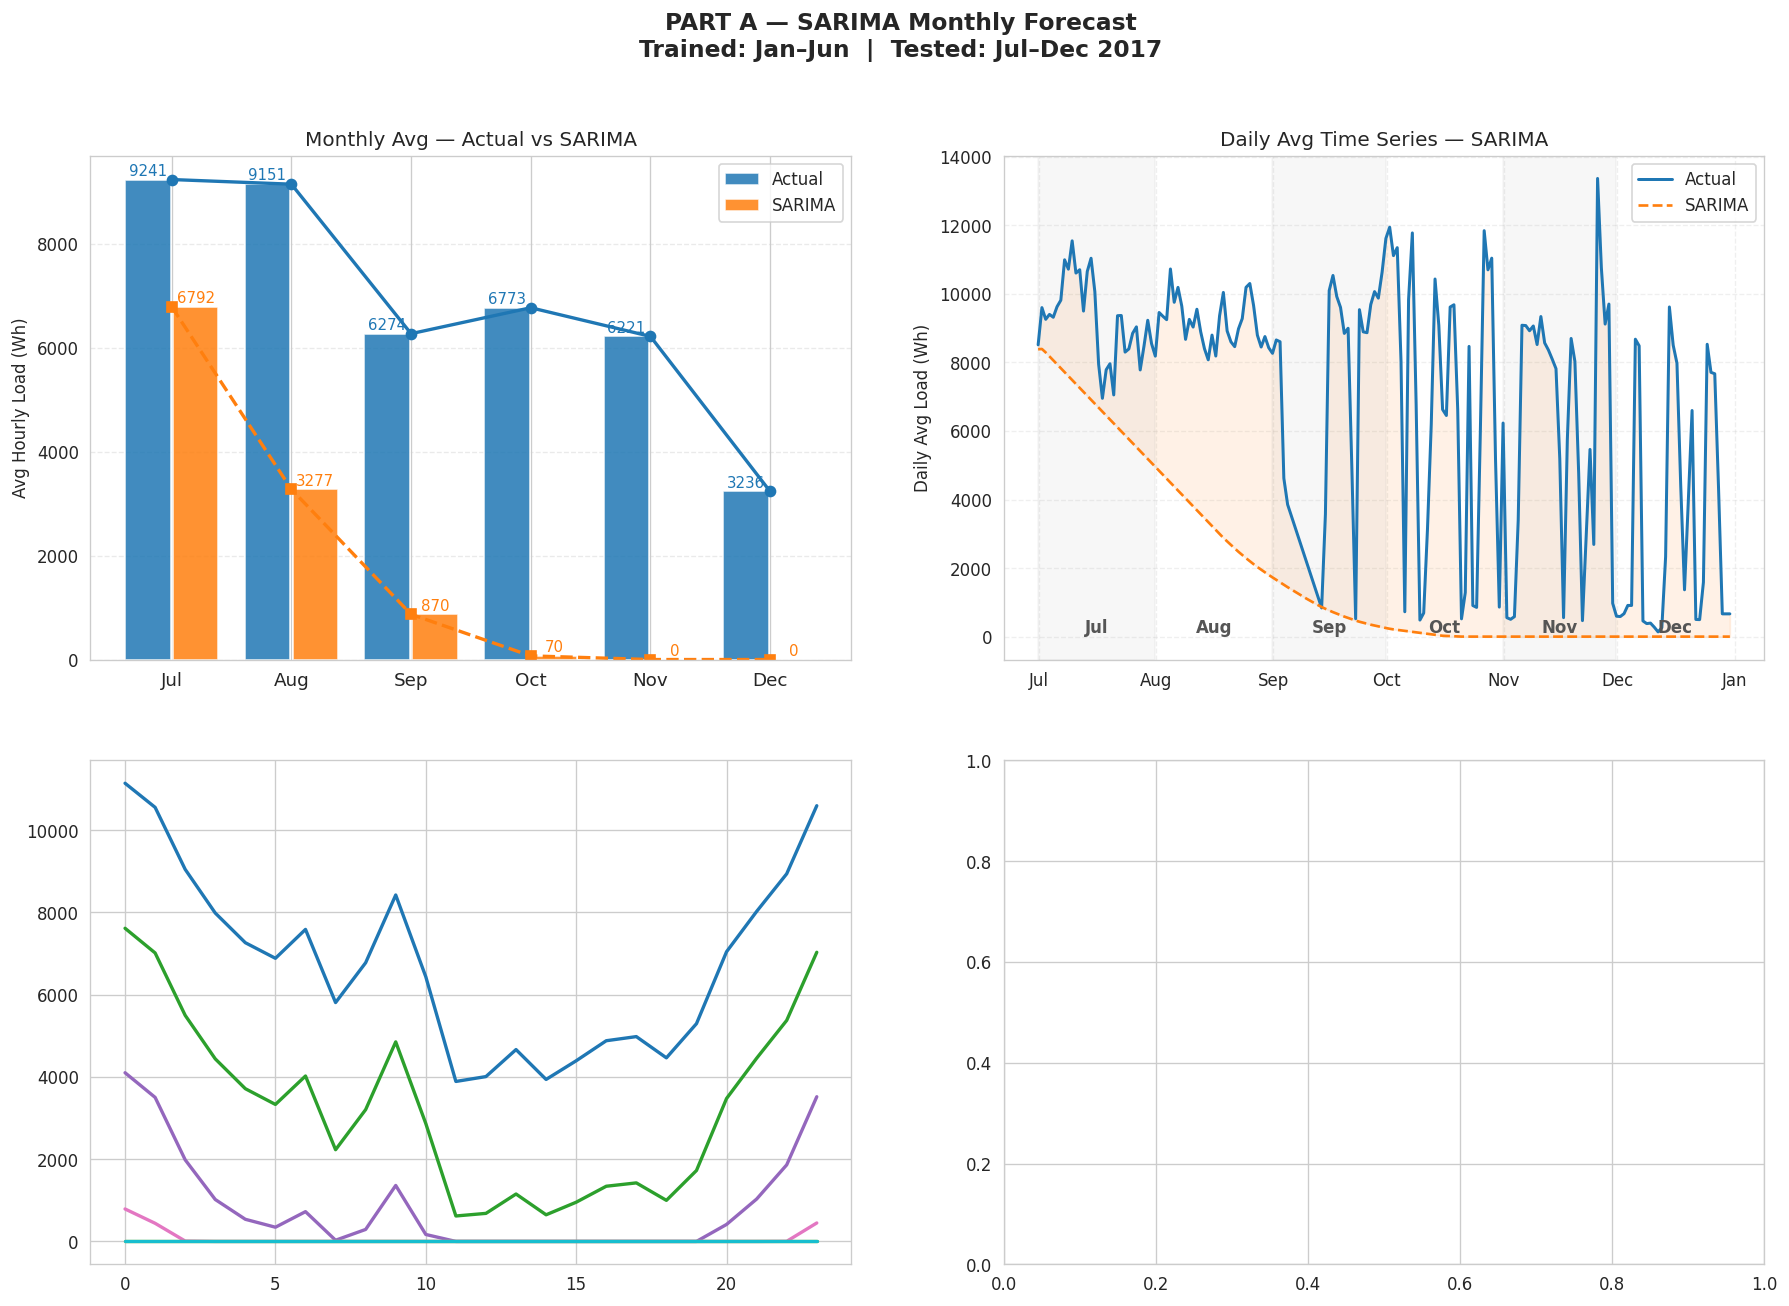

In [ ]:
# ════════════════════════════════════════════════════════════════
# BLOCK 2 — PART A: SARIMA MONTHLY
# ════════════════════════════════════════════════════════════════

print("█"*55)
print("  BLOCK 2 — SARIMA MONTHLY")
print("█"*55)

# ── ADF stationarity test ──────────────────────────────────────
adf = adfuller(train_W.dropna())
print(f"\nADF p-value: {adf[1]:.4f} →",
      "stationary ✓" if adf[1] < 0.05 else "non-stationary → d=1")

# ── Fit SARIMA(1,1,1)(1,1,1,24) ───────────────────────────────
print("\nFitting SARIMA(1,1,1)(1,1,1,24) — takes 2–4 min...")
sarima_m = SARIMAX(train_W,
                   order=(1,1,1),
                   seasonal_order=(1,1,1,24),
                   enforce_stationarity=False,
                   enforce_invertibility=False).fit(disp=False, maxiter=200)

print(f"AIC: {sarima_m.aic:.2f}  BIC: {sarima_m.bic:.2f}")

sarima_m_fc  = np.maximum(sarima_m.forecast(steps=len(test_W)).values, 0)
m_sarima_mon = calc_metrics(test_W.values, sarima_m_fc,
                             "SARIMA Monthly")

df_sarima_mon = pd.DataFrame({
    'actual'   : test_W.values,
    'predicted': sarima_m_fc,
    'month'    : test_W.index.month
}, index=test_W.index)

# ════════════════════════════════════════════════════════════════
# SARIMA MONTHLY PLOTS
# ════════════════════════════════════════════════════════════════

months_sm  = sorted(df_sarima_mon['month'].unique())
labels_sm  = [month_names[m-1] for m in months_sm]
x_sm       = np.arange(len(months_sm))
act_sm_avg = df_sarima_mon.groupby('month')['actual'].mean()
sar_sm_avg = df_sarima_mon.groupby('month')['predicted'].mean()

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle("PART A — SARIMA Monthly Forecast\n"
             "Trained: Jan–Jun  |  Tested: Jul–Dec 2017",
             fontsize=14, fontweight='bold')

# ── Plot 1: Monthly avg bar ────────────────────────────────────
ax = axes[0, 0]
b1 = ax.bar(x_sm - 0.2, act_sm_avg.values, width=0.38,
            label='Actual', color='#1f77b4', alpha=0.85)
b2 = ax.bar(x_sm + 0.2, sar_sm_avg.values, width=0.38,
            label='SARIMA', color='#ff7f0e', alpha=0.85)
ax.plot(x_sm, act_sm_avg.values, color='#1f77b4',
        marker='o', linewidth=2)
ax.plot(x_sm, sar_sm_avg.values, color='#ff7f0e',
        marker='s', linewidth=2, linestyle='--')
for bar in b1:
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+80, f'{bar.get_height():.0f}',
            ha='center', fontsize=9, color='#1f77b4')
for bar in b2:
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+80, f'{bar.get_height():.0f}',
            ha='center', fontsize=9, color='#ff7f0e')
ax.set_xticks(x_sm)
ax.set_xticklabels(labels_sm, fontsize=11)
ax.set_ylabel("Avg Hourly Load (Wh)")
ax.set_title("Monthly Avg — Actual vs SARIMA")
ax.legend(); ax.grid(True, axis='y', alpha=0.4, linestyle='--')

# ── Plot 2: Daily time series ─────────────────────────────────
ax  = axes[0, 1]
da  = df_sarima_mon['actual'].resample('D').mean()
dsa = df_sarima_mon['predicted'].resample('D').mean()
ax.plot(da.index,  da.values,  color='#1f77b4',
        linewidth=1.8, label='Actual')
ax.plot(dsa.index, dsa.values, color='#ff7f0e',
        linewidth=1.6, linestyle='--', label='SARIMA')
ax.fill_between(da.index, da.values, dsa.values,
                alpha=0.10, color='#ff7f0e')
for k, m in enumerate(months_sm):
    m_data = df_sarima_mon[df_sarima_mon['month']==m]
    start, end = m_data.index[0], m_data.index[-1]
    if k % 2 == 0:
        ax.axvspan(start, end, alpha=0.06, color='gray')
    mid = start + (end - start) / 2
    ax.text(mid, da.min()*0.88, month_names[m-1],
            ha='center', fontsize=10, color='#555', fontweight='bold')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylabel("Daily Avg Load (Wh)")
ax.set_title("Daily Avg Time Series — SARIMA")
ax.legend(); ax.grid(True, alpha=0.3, linestyle='--')

# ── Plot 3: Monthly avg daily profile per month ───────────────
ax = axes[1, 0]
colors_m = plt.cm.tab10(np.linspace(0, 1, len(months_sm)))
for m, clr in zip(months_sm, colors_m):
    m_data = df_sarima_mon[df_sarima_mon['month']==m]
    hp     = m_data.groupby(m_data.index.hour)['predicted'].mean()
    ax.plot(hp.index, hp.values, color=clr,
            linewidth=2, label=month_names[m-1])
ax.set_xt

███████████████████████████████████████████████████████
  BLOCK 3 — LSTM MONTHLY
███████████████████████████████████████████████████████
Epoch 1/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - loss: 0.0308 - val_loss: 0.0133 - learning_rate: 0.0010
Epoch 2/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - loss: 0.0224 - val_loss: 0.0119 - learning_rate: 0.0010
Epoch 3/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - loss: 0.0186 - val_loss: 0.0125 - learning_rate: 0.0010
Epoch 4/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0170 - val_loss: 0.0130 - learning_rate: 0.0010
Epoch 5/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0151 - val_loss: 0.0114 - learning_rate: 0.0010
Epoch 6/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0142 - val_loss: 0.0114 - learning_rate: 0.0010
Epoch 7/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0131 - val_loss: 0.0099 - learning_rate: 0.0010
Epoch 8/80
122/122 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - loss: 0.0122 - val_loss: 0.009

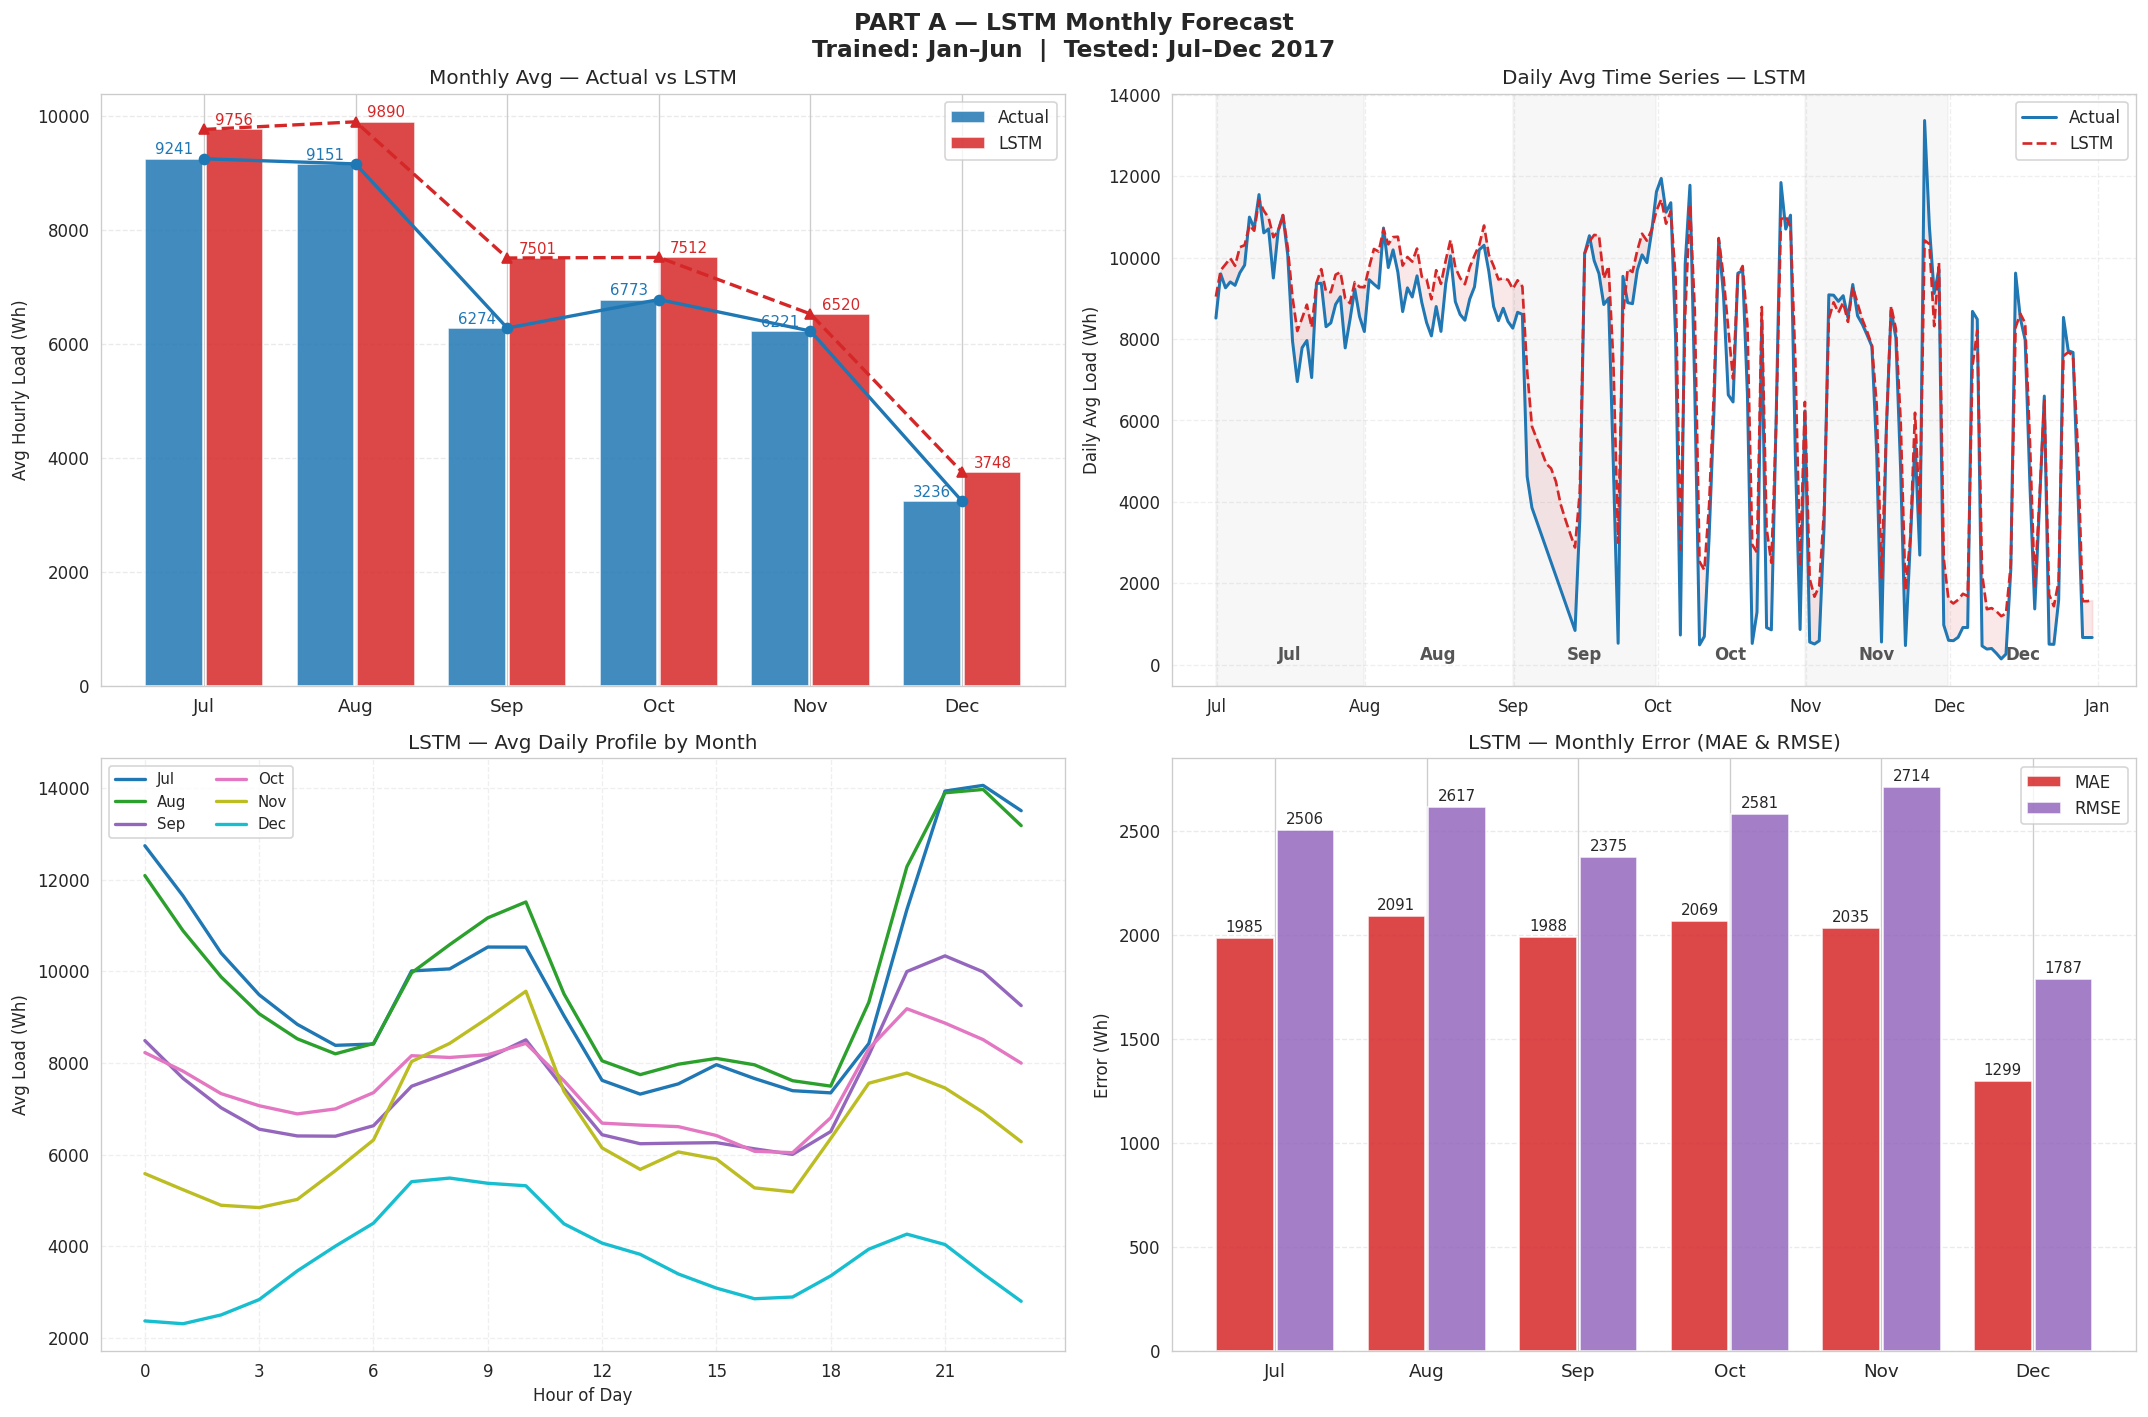


✓ Block 3 complete — LSTM Monthly done


In [ ]:
# ════════════════════════════════════════════════════════════════
# BLOCK 3 — PART A: LSTM MONTHLY
# ════════════════════════════════════════════════════════════════

print("█"*55)
print("  BLOCK 3 — LSTM MONTHLY")
print("█"*55)

WINDOW_M   = 24
feat_sc_m  = MinMaxScaler()
train_sc_m = feat_sc_m.fit_transform(train_raw[FEATURES])
test_sc_m  = feat_sc_m.transform(test_raw[FEATURES])
w_sc_m     = MinMaxScaler()
w_sc_m.fit(train_raw[['W']])

combined_m = np.vstack([train_sc_m[-WINDOW_M:], test_sc_m])

def make_seq_1step(data, window):
    X, y = [], []
    for i in range(len(data) - window):
        X.append(data[i : i + window])
        y.append(data[i + window, 0])
    return np.array(X), np.array(y)

X_tr_m, y_tr_m = make_seq_1step(train_sc_m, WINDOW_M)
X_te_m, y_te_m = make_seq_1step(combined_m,  WINDOW_M)

lstm_m = Sequential([
    LSTM(64, return_sequences=True,
         input_shape=(WINDOW_M, X_tr_m.shape[2])),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])
lstm_m.compile(optimizer='adam', loss='mse')
lstm_m.fit(X_tr_m, y_tr_m, epochs=80, batch_size=32,
           validation_split=0.1, callbacks=cbs, verbose=1)

lstm_m_fc = np.maximum(
    w_sc_m.inverse_transform(
        lstm_m.predict(X_te_m, verbose=0)).flatten(), 0)

n_m          = min(len(test_W), len(lstm_m_fc))
test_W_m     = test_W.values[:n_m]
test_idx_m   = test_W.index[:n_m]
lstm_m_fc    = lstm_m_fc[:n_m]
m_lstm_mon   = calc_metrics(test_W_m, lstm_m_fc, "LSTM Monthly")

df_lstm_mon  = pd.DataFrame({
    'actual'   : test_W_m,
    'predicted': lstm_m_fc,
    'month'    : test_idx_m.month
}, index=test_idx_m)

# ════════════════════════════════════════════════════════════════
# LSTM MONTHLY PLOTS
# ════════════════════════════════════════════════════════════════

months_lm  = sorted(df_lstm_mon['month'].unique())
labels_lm  = [month_names[m-1] for m in months_lm]
x_lm       = np.arange(len(months_lm))
act_lm_avg = df_lstm_mon.groupby('month')['actual'].mean()
lst_lm_avg = df_lstm_mon.groupby('month')['predicted'].mean()

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle("PART A — LSTM Monthly Forecast\n"
             "Trained: Jan–Jun  |  Tested: Jul–Dec 2017",
             fontsize=14, fontweight='bold')

# ── Plot 1: Monthly avg bar ────────────────────────────────────
ax = axes[0, 0]
b1 = ax.bar(x_lm - 0.2, act_lm_avg.values, width=0.38,
            label='Actual', color='#1f77b4', alpha=0.85)
b2 = ax.bar(x_lm + 0.2, lst_lm_avg.values, width=0.38,
            label='LSTM',   color='#d62728', alpha=0.85)
ax.plot(x_lm, act_lm_avg.values, color='#1f77b4',
        marker='o', linewidth=2)
ax.plot(x_lm, lst_lm_avg.values, color='#d62728',
        marker='^', linewidth=2, linestyle='--')
for bar in b1:
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+80, f'{bar.get_height():.0f}',
            ha='center', fontsize=9, color='#1f77b4')
for bar in b2:
    ax.text(bar.get_x()+bar.get_width()/2,
            bar.get_height()+80, f'{bar.get_height():.0f}',
            ha='center', fontsize=9, color='#d62728')
ax.set_xticks(x_lm)
ax.set_xticklabels(labels_lm, fontsize=11)
ax.set_ylabel("Avg Hourly Load (Wh)")
ax.set_title("Monthly Avg — Actual vs LSTM")
ax.legend(); ax.grid(True, axis='y', alpha=0.4, linestyle='--')

# ── Plot 2: Daily time series ─────────────────────────────────
ax  = axes[0, 1]
da  = df_lstm_mon['actual'].resample('D').mean()
dl  = df_lstm_mon['predicted'].resample('D').mean()
ax.plot(da.index, da.values, color='#1f77b4',
        linewidth=1.8, label='Actual')
ax.plot(dl.index, dl.values, color='#d62728',
        linewidth=1.6, linestyle='--', label='LSTM')
ax.fill_between(da.index, da.values, dl.values,
                alpha=0.10, color='#d62728')
for k, m in enumerate(months_lm):
    m_data = df_lstm_mon[df_lstm_mon['month']==m]
    start, end = m_data.index[0], m_data.index[-1]
    if k % 2 == 0:
        ax.axvspan(start, end, alpha=0.06, color='gray')
    mid = start + (end - start) / 2
    ax.text(mid, da.min()*0.88, month_names[m-1],
            ha='center', fontsize=10, color='#555', fontweight='bold')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylabel("Daily Avg Load (Wh)")
ax.set_title("Daily Avg Time Series — LSTM")
ax.legend(); ax.grid(True, alpha=0.3, linestyle='--')

# ── Plot 3: Avg daily profile by month ────────────────────────
ax = axes[1, 0]
for m, clr in zip(months_lm, plt.cm.tab10(np.linspace(0,1,len(months_lm)))):
    m_data = df_lstm_mon[df_lstm_mon['month']==m]
    hp     = m_data.groupby(m_data.index.hour)['predicted'].mean()
    ax.plot(hp.index, hp.values, color=clr,
            linewidth=2, label=month_names[m-1])
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Avg Load (Wh)")
ax.set_title("LSTM — Avg Daily Profile by Month")
ax.legend(fontsize=9, ncol=2)
ax.grid(True, alpha=0.3, linestyle='--')

# ── Plot 4: Monthly MAE + RMSE ────────────────────────────────
ax         = axes[1, 1]
lst_m_mae  = df_lstm_mon.groupby('month').apply(
    lambda g: mean_absolute_error(g['actual'], g['predicted']))
lst_m_rmse = df_lstm_mon.groupby('month').apply(
    lambda g: np.sqrt(mean_squared_error(g['actual'], g['predicted'])))
ax.bar(x_lm - 0.2, lst_m_mae.values,  width=0.38,
       label='MAE',  color='#d62728', alpha=0.85)
ax.bar(x_lm + 0.2, lst_m_rmse.values, width=0.38,
       label='RMSE', color='#9467bd', alpha=0.85)
for i,(mv,rv) in enumerate(zip(lst_m_mae.values, lst_m_rmse.values)):
    ax.text(i-0.2, mv+30, f'{mv:.0f}', ha='center', fontsize=9)
    ax.text(i+0.2, rv+30, f'{rv:.0f}', ha='center', fontsize=9)
ax.set_xticks(x_lm)
ax.set_xticklabels(labels_lm, fontsize=11)
ax.set_ylabel("Error (Wh)")
ax.set_title("LSTM — Monthly Error (MAE & RMSE)")
ax.legend(); ax.grid(True, axis='y', alpha=0.4, linestyle='--')

plt.tight_layout()
plt.show()

print("\n✓ Block 3 complete — LSTM Monthly done")

In [ ]:
# ════════════════════════════════════════════════════════════════
# BLOCK A — XGBoost: Feature Engineering
# Builds lag + rolling features from df_2017
# Run AFTER your existing data prep (df_2017 must exist)
# ════════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import xgboost as xgb
import shap
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 120
month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

# ── Build lag + rolling features ──────────────────────────────
def build_xgb_features(df):
    d = df[['W']].copy()

    # Lag features (past hours)
    for lag in [1, 2, 3, 6, 12, 24, 48, 168]:
        d[f'lag_{lag}h'] = d['W'].shift(lag)

    # Rolling stats
    for w in [6, 12, 24, 168]:
        d[f'roll_mean_{w}h'] = d['W'].shift(1).rolling(w).mean()
        d[f'roll_std_{w}h']  = d['W'].shift(1).rolling(w).std()
        d[f'roll_max_{w}h']  = d['W'].shift(1).rolling(w).max()

    # Cyclical time features
    d['hour']        = df.index.hour
    d['day_of_week'] = df.index.dayofweek
    d['month']       = df.index.month
    d['is_weekend']  = (df.index.dayofweek >= 5).astype(int)
    d['hour_sin']    = np.sin(2 * np.pi * df.index.hour  / 24)
    d['hour_cos']    = np.cos(2 * np.pi * df.index.hour  / 24)
    d['month_sin']   = np.sin(2 * np.pi * df.index.month / 12)
    d['month_cos']   = np.cos(2 * np.pi * df.index.month / 12)
    d['dow_sin']     = np.sin(2 * np.pi * df.index.dayofweek / 7)
    d['dow_cos']     = np.cos(2 * np.pi * df.index.dayofweek / 7)

    return d.dropna()

df_xgb_full = build_xgb_features(df_2017)

# Same train/test split: Jan–Jun → Jul–Dec
xgb_train = df_xgb_full.loc['2017-01-01':'2017-06-30']
xgb_test  = df_xgb_full.loc['2017-07-01':'2017-12-31']

FEATURE_COLS = [c for c in df_xgb_full.columns if c != 'W']
X_train_xgb  = xgb_train[FEATURE_COLS]
y_train_xgb  = xgb_train['W']
X_test_xgb   = xgb_test[FEATURE_COLS]
y_test_xgb   = xgb_test['W']

print(f"XGBoost Train : {len(X_train_xgb)} samples  "
      f"({xgb_train.index[0].date()} → {xgb_train.index[-1].date()})")
print(f"XGBoost Test  : {len(X_test_xgb)} samples  "
      f"({xgb_test.index[0].date()} → {xgb_test.index[-1].date()})")
print(f"Features      : {len(FEATURE_COLS)}")
print(f"\nFeature list  : {FEATURE_COLS}")

XGBoost Train : 4176 samples  (2017-01-08 → 2017-06-30)
XGBoost Test  : 4416 samples  (2017-07-01 → 2017-12-31)
Features      : 30

Feature list  : ['lag_1h', 'lag_2h', 'lag_3h', 'lag_6h', 'lag_12h', 'lag_24h', 'lag_48h', 'lag_168h', 'roll_mean_6h', 'roll_std_6h', 'roll_max_6h', 'roll_mean_12h', 'roll_std_12h', 'roll_max_12h', 'roll_mean_24h', 'roll_std_24h', 'roll_max_24h', 'roll_mean_168h', 'roll_std_168h', 'roll_max_168h', 'hour', 'day_of_week', 'month', 'is_weekend', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos']


In [ ]:
# ════════════════════════════════════════════════════════════════
# BLOCK B — Train XGBoost (Fixed for newer XGBoost versions)
# ════════════════════════════════════════════════════════════════
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators          = 1000,
    learning_rate         = 0.05,
    max_depth             = 6,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    min_child_weight      = 5,
    reg_alpha             = 0.1,
    reg_lambda            = 1.0,
    objective             = 'reg:squarederror',
    random_state          = 42,
    n_jobs                = -1,
    early_stopping_rounds = 50,   # ← moved here from .fit()
    eval_metric           = 'rmse'
)

val_cut      = int(len(X_train_xgb) * 0.9)
X_tr, X_val  = X_train_xgb.iloc[:val_cut], X_train_xgb.iloc[val_cut:]
y_tr, y_val  = y_train_xgb.iloc[:val_cut], y_train_xgb.iloc[val_cut:]

xgb_model.fit(
    X_tr, y_tr,
    eval_set = [(X_val, y_val)],
    verbose  = 100
)

# Predict
xgb_preds = np.maximum(xgb_model.predict(X_test_xgb), 0)

# ── Metrics ───────────────────────────────────────────────────
def calc_metrics(actual, predicted):
    mask  = np.array(actual) > 100
    a, p  = np.array(actual)[mask], np.array(predicted)[mask]
    r2    = r2_score(a, p)
    rmse  = np.sqrt(mean_squared_error(a, p))
    mae   = mean_absolute_error(a, p)
    denom = (np.abs(a) + np.abs(p)) / 2
    denom = np.where(denom < 1e-8, 1e-8, denom)
    smape = np.mean(np.abs(a - p) / denom) * 100
    return {'R2': r2, 'RMSE': rmse, 'MAE': mae, 'sMAPE': smape}

m_xgb = calc_metrics(y_test_xgb.values, xgb_preds)

print(f"\n{'═'*42}")
print(f"  XGBoost — Test Metrics (Jul–Dec)")
print(f"{'═'*42}")
print(f"  R²    : {m_xgb['R2']:.4f}")
print(f"  RMSE  : {m_xgb['RMSE']:.2f} Wh")
print(f"  MAE   : {m_xgb['MAE']:.2f} Wh")
print(f"  sMAPE : {m_xgb['sMAPE']:.2f}%")
print(f"{'═'*42}")

df_xgb_result = pd.DataFrame({
    'actual'   : y_test_xgb.values,
    'predicted': xgb_preds,
    'month'    : xgb_test.index.month
}, index=xgb_test.index)

print(f"\nBest iteration : {xgb_model.best_iteration}")

[0]	validation_0-rmse:4314.28937
[100]	validation_0-rmse:1636.41245
[149]	validation_0-rmse:1645.66756

══════════════════════════════════════════
  XGBoost — Test Metrics (Jul–Dec)
══════════════════════════════════════════
  R²    : 0.8327
  RMSE  : 1913.23 Wh
  MAE   : 1407.67 Wh
  sMAPE : 37.93%
══════════════════════════════════════════

Best iteration : 99


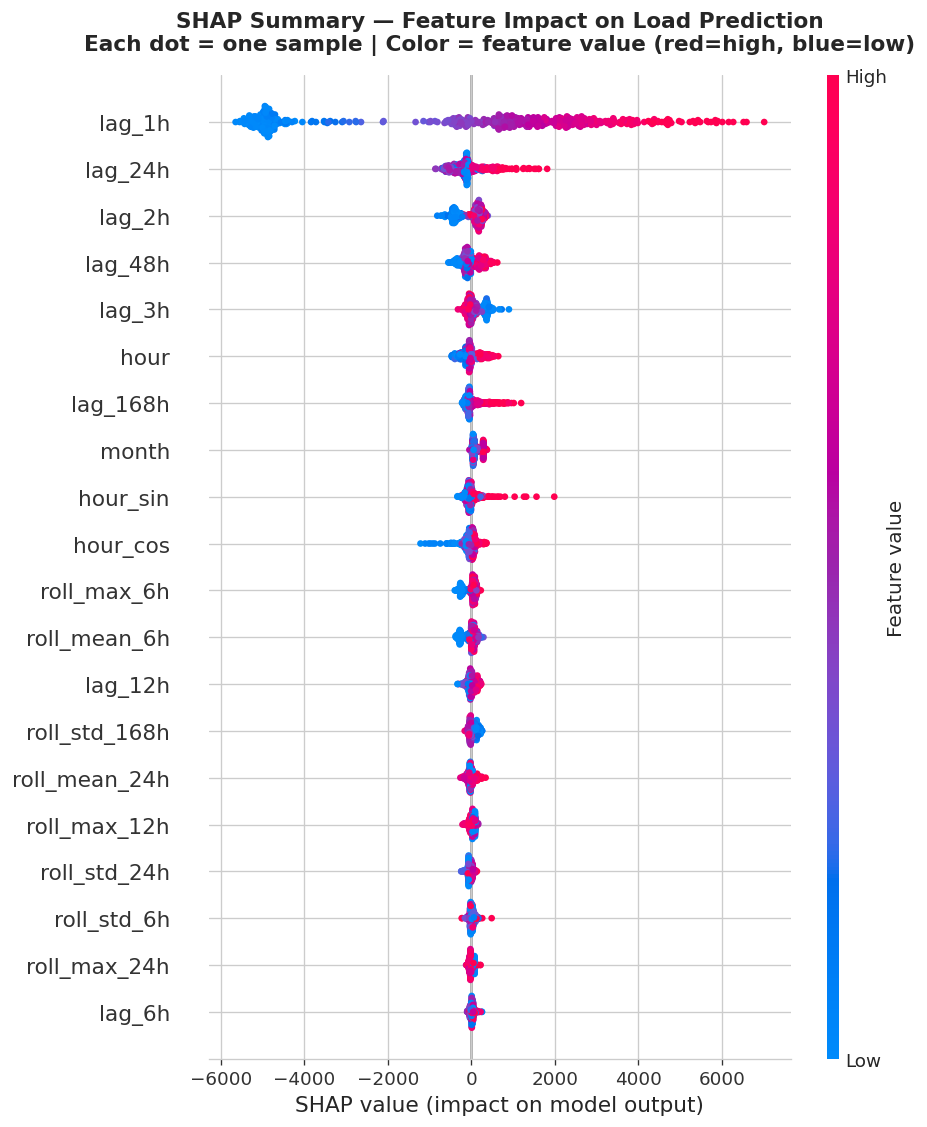

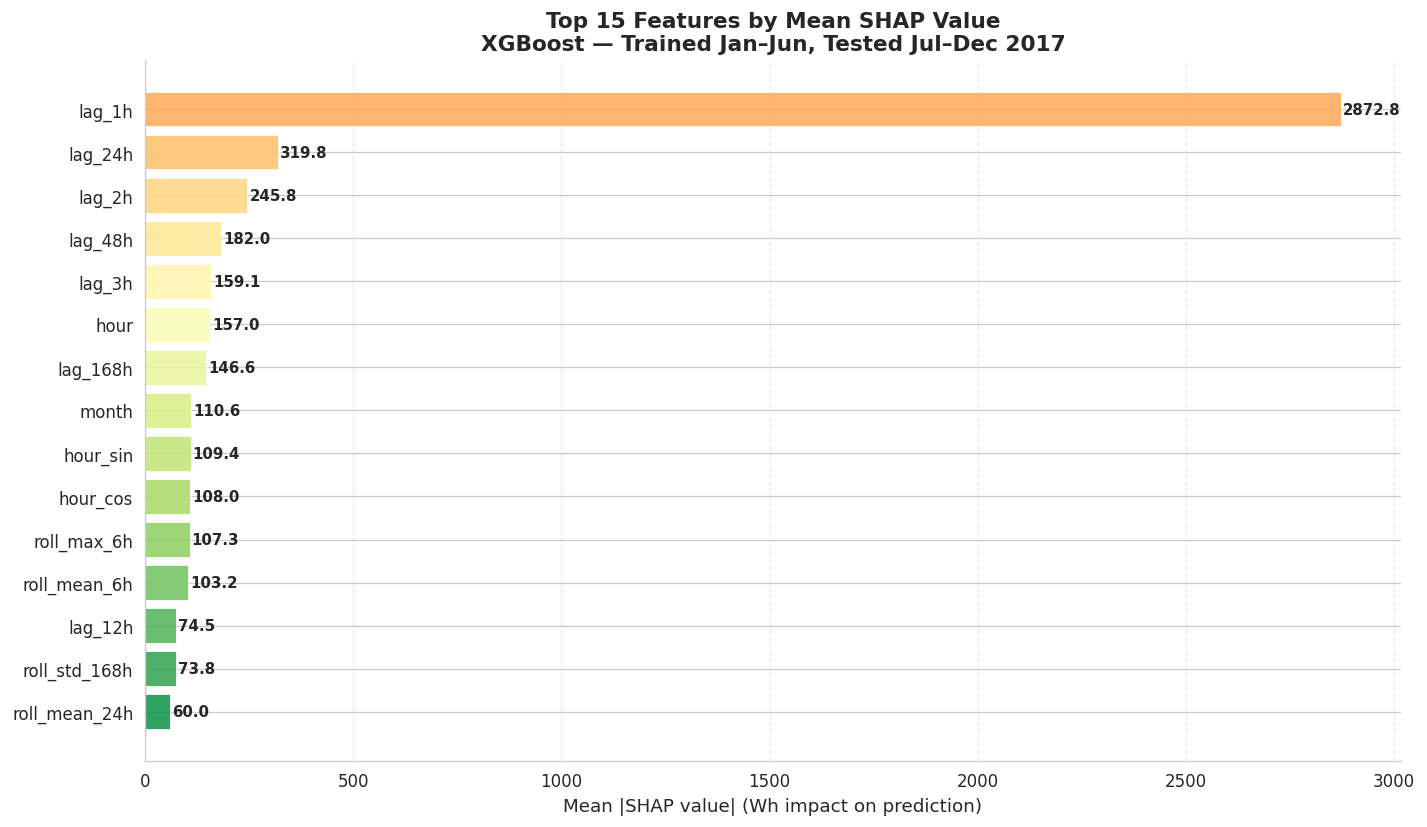

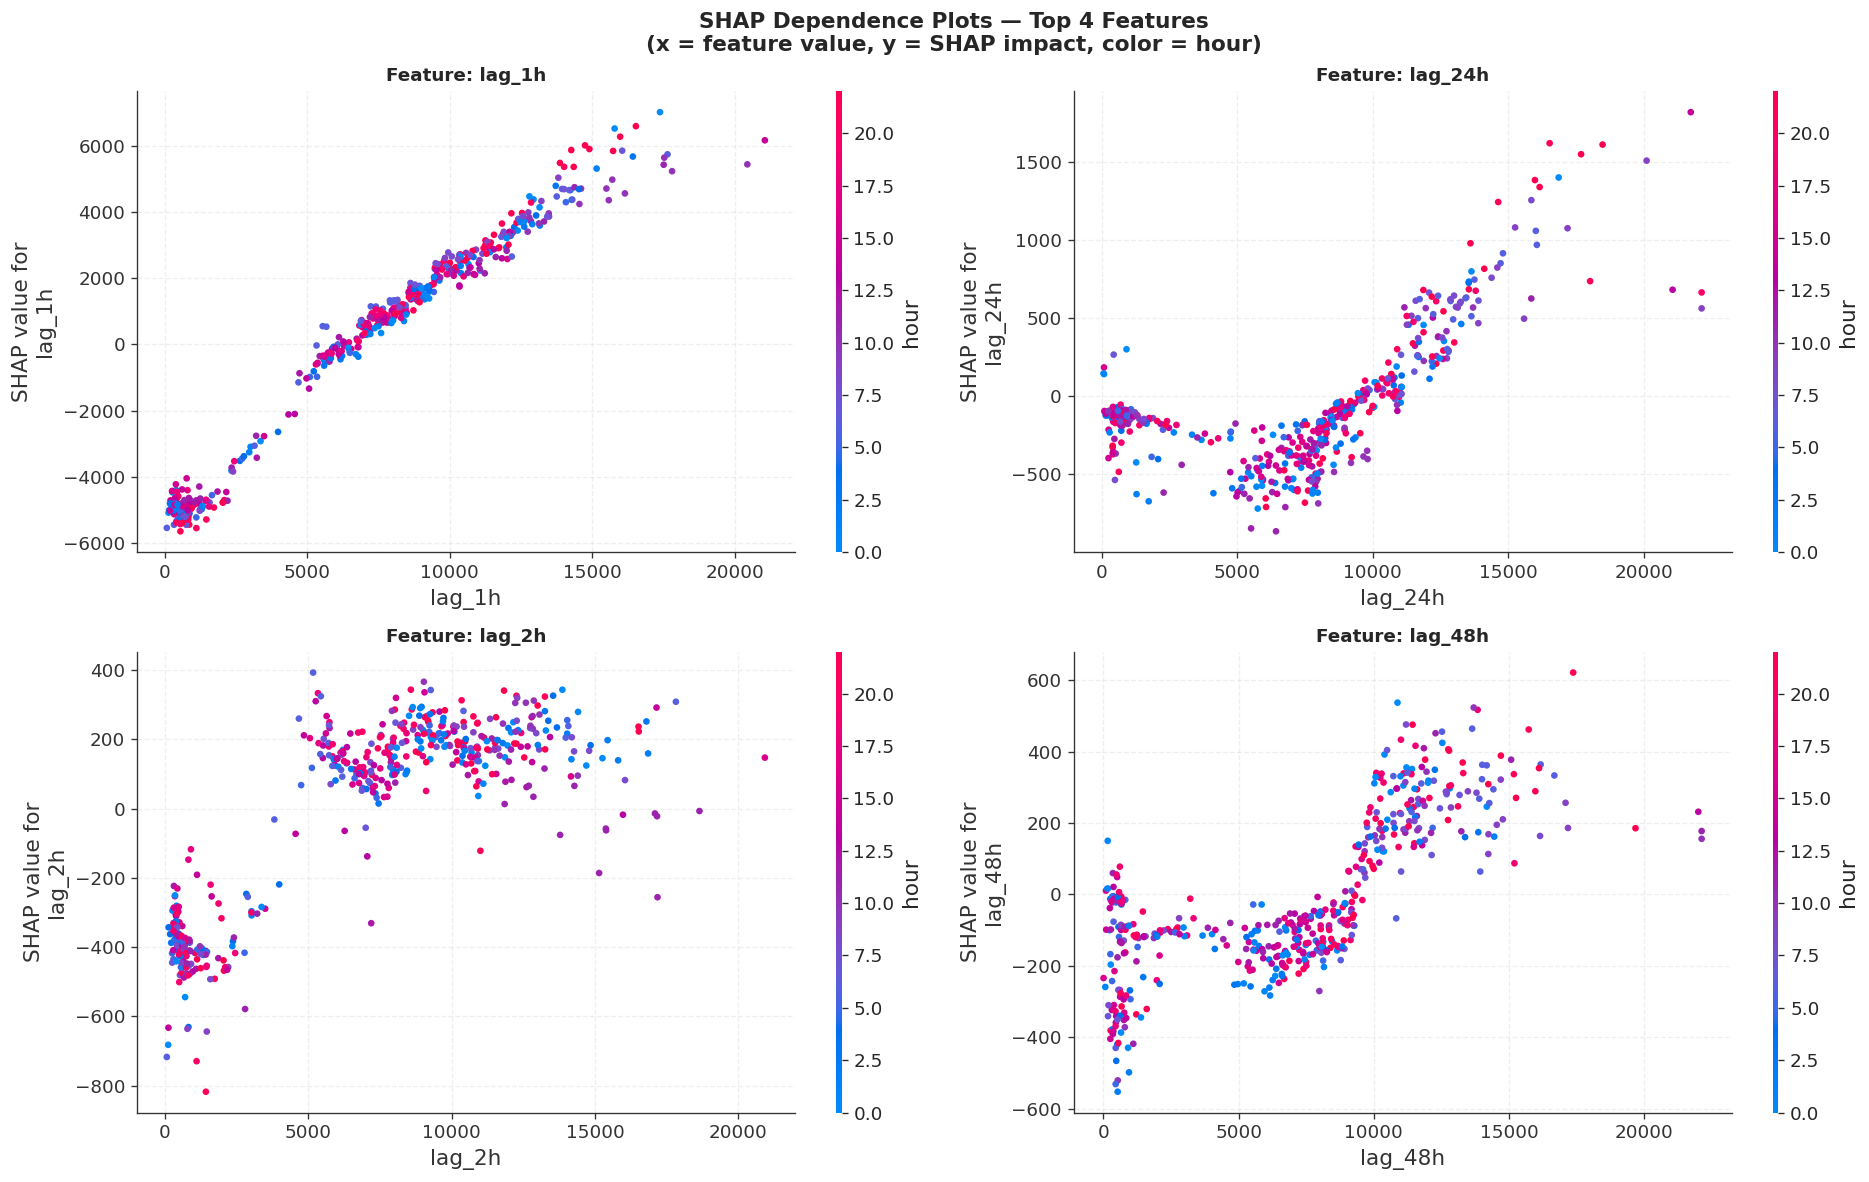

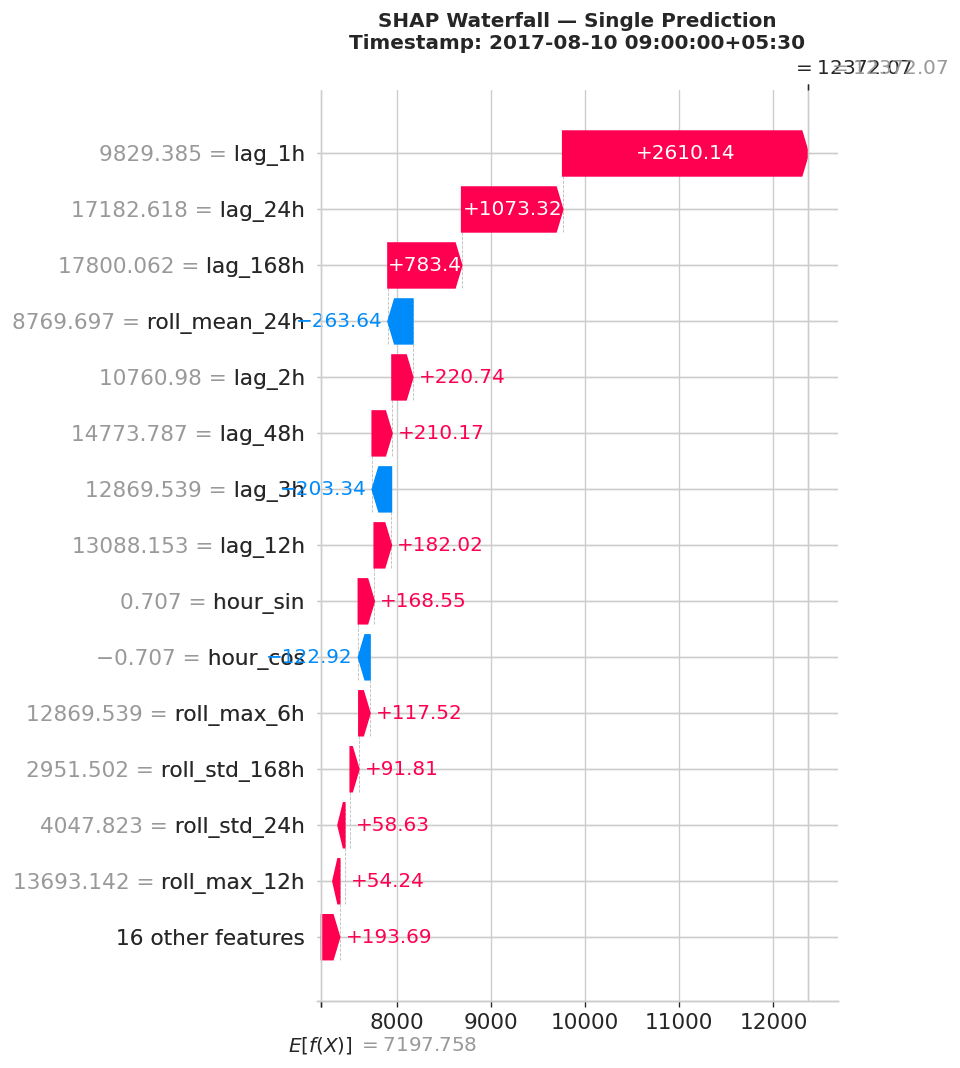


── Top 10 Feature Importances (SHAP) ──────────────────
 feature   mean_shap
  lag_1h 2872.794678
 lag_24h  319.833832
  lag_2h  245.831253
 lag_48h  181.996262
  lag_3h  159.121201
    hour  157.000153
lag_168h  146.578384
   month  110.643303
hour_sin  109.383209
hour_cos  108.035606


In [ ]:
# ════════════════════════════════════════════════════════════════
# BLOCK C — SHAP Analysis (Feature Importance + Plots)
# ════════════════════════════════════════════════════════════════

# Use a sample for speed (SHAP on full test set is slow)
shap_sample = X_test_xgb.sample(n=min(500, len(X_test_xgb)),
                                  random_state=42).sort_index()

explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(shap_sample)

# ── PLOT 1: SHAP Summary (Beeswarm) ───────────────────────────
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values, shap_sample,
    plot_type = 'dot',
    max_display = 20,
    show = False
)
plt.title("SHAP Summary — Feature Impact on Load Prediction\n"
          "Each dot = one sample | Color = feature value (red=high, blue=low)",
          fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# ── PLOT 2: SHAP Bar — Mean Absolute Importance ───────────────
shap_importance = pd.DataFrame({
    'feature'    : FEATURE_COLS,
    'mean_shap'  : np.abs(shap_values).mean(axis=0)
}).sort_values('mean_shap', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(12, 7))
colors  = plt.cm.RdYlGn(
    np.linspace(0.3, 0.9, len(shap_importance)))[::-1]
bars = ax.barh(
    shap_importance['feature'][::-1],
    shap_importance['mean_shap'][::-1],
    color=colors, alpha=0.9, edgecolor='white', linewidth=0.5
)
for bar, val in zip(bars,
                    shap_importance['mean_shap'][::-1].values):
    ax.text(val + 5, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}', va='center', fontsize=9, fontweight='bold')

ax.set_xlabel("Mean |SHAP value| (Wh impact on prediction)",
              fontsize=11)
ax.set_title("Top 15 Features by Mean SHAP Value\n"
             "XGBoost — Trained Jan–Jun, Tested Jul–Dec 2017",
             fontsize=13, fontweight='bold')
ax.grid(True, axis='x', alpha=0.4, linestyle='--')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# ── PLOT 3: SHAP Dependence — top 4 features ─────────────────
top4 = shap_importance['feature'].values[:4]
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()
fig.suptitle("SHAP Dependence Plots — Top 4 Features\n"
             "(x = feature value, y = SHAP impact, color = hour)",
             fontsize=13, fontweight='bold')
for i, feat in enumerate(top4):
    shap.dependence_plot(
        feat, shap_values, shap_sample,
        interaction_index='hour',
        ax=axes[i], show=False
    )
    axes[i].set_title(f"Feature: {feat}", fontsize=11,
                      fontweight='bold')
    axes[i].grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

# ── PLOT 4: SHAP Waterfall for a single prediction ────────────
# Pick one typical hour (e.g. a peak-load hour in August)
sample_idx = shap_sample[
    (shap_sample.index.month == 8) &
    (shap_sample.index.hour  == 9)
].index
if len(sample_idx) > 0:
    idx    = sample_idx[0]
    loc    = shap_sample.index.get_loc(idx)
    exp    = shap.Explanation(
        values        = shap_values[loc],
        base_values   = explainer.expected_value,
        data          = shap_sample.iloc[loc].values,
        feature_names = FEATURE_COLS
    )
    plt.figure(figsize=(12, 7))
    shap.waterfall_plot(exp, max_display=15, show=False)
    plt.title(f"SHAP Waterfall — Single Prediction\n"
              f"Timestamp: {idx}",
              fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

print("\n── Top 10 Feature Importances (SHAP) ──────────────────")
print(shap_importance.head(10).to_string(index=False))


═════════════════════════════════════════════════════════════════
  3-MODEL COMPARISON — Jul–Dec 2017 (Test Period)
═════════════════════════════════════════════════════════════════
  Model                    R²    RMSE (Wh)    MAE (Wh)    sMAPE
  -------------------------------------------------------------
  SARIMA             -1.1179       6807.6      5188.9   149.36%
  LSTM Monthly        0.7265       2446.4      1910.2    45.33%
  XGBoost             0.8327★      1913.2★     1407.7    37.93%
═════════════════════════════════════════════════════════════════
  ★ = best in that metric


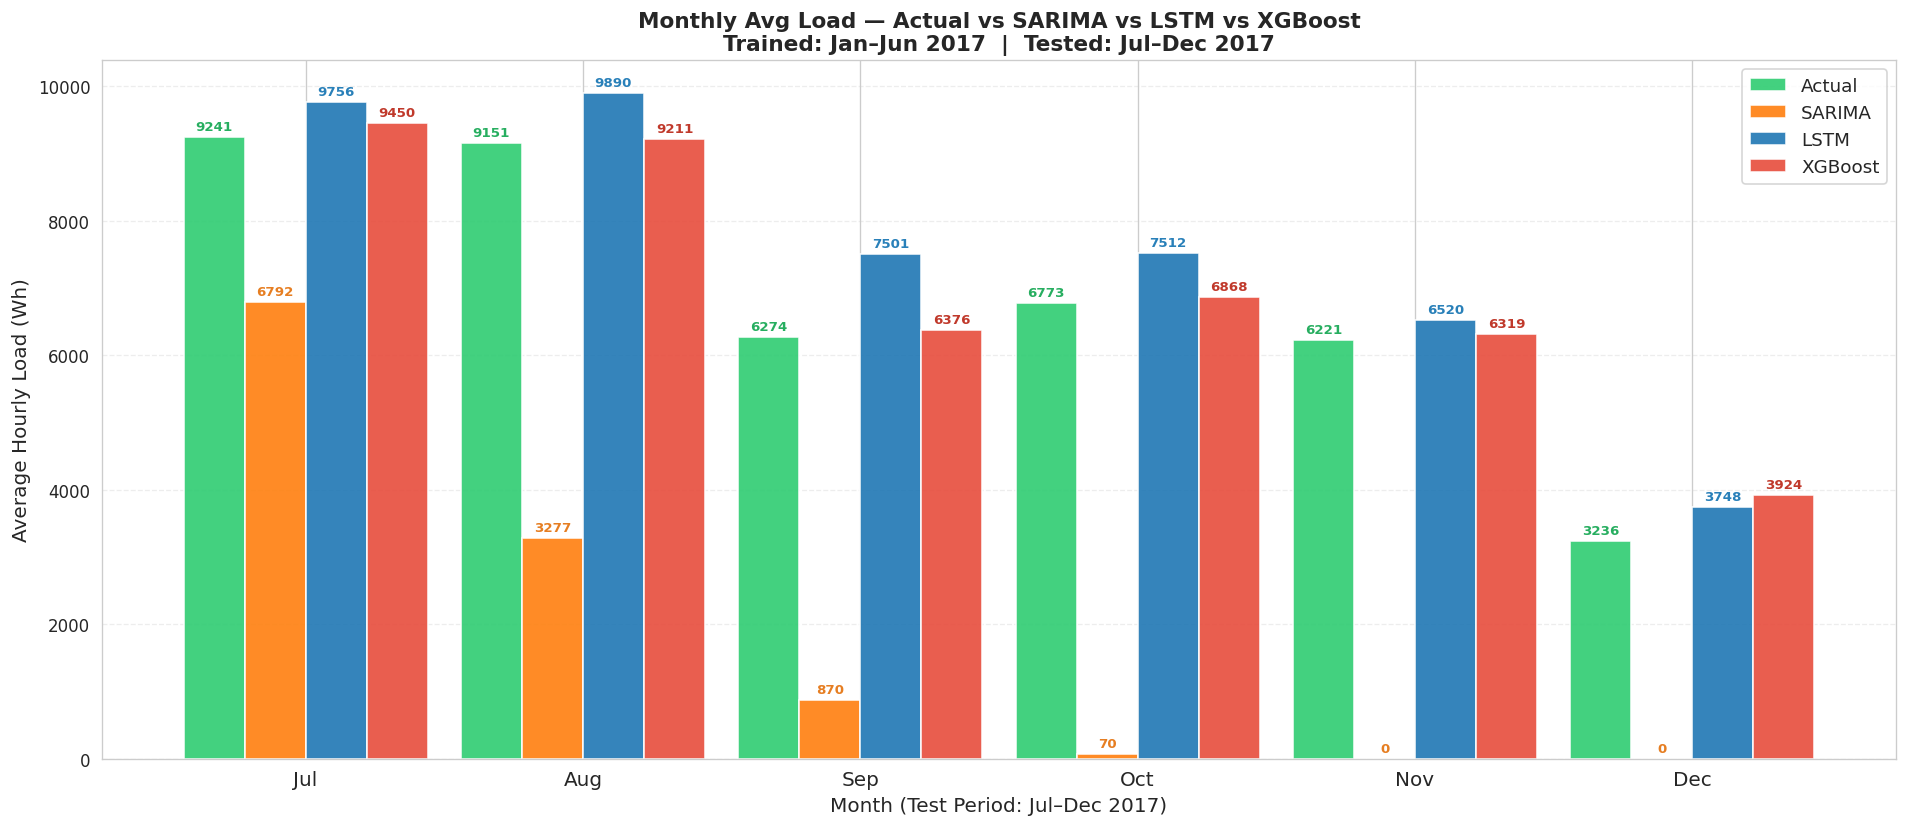

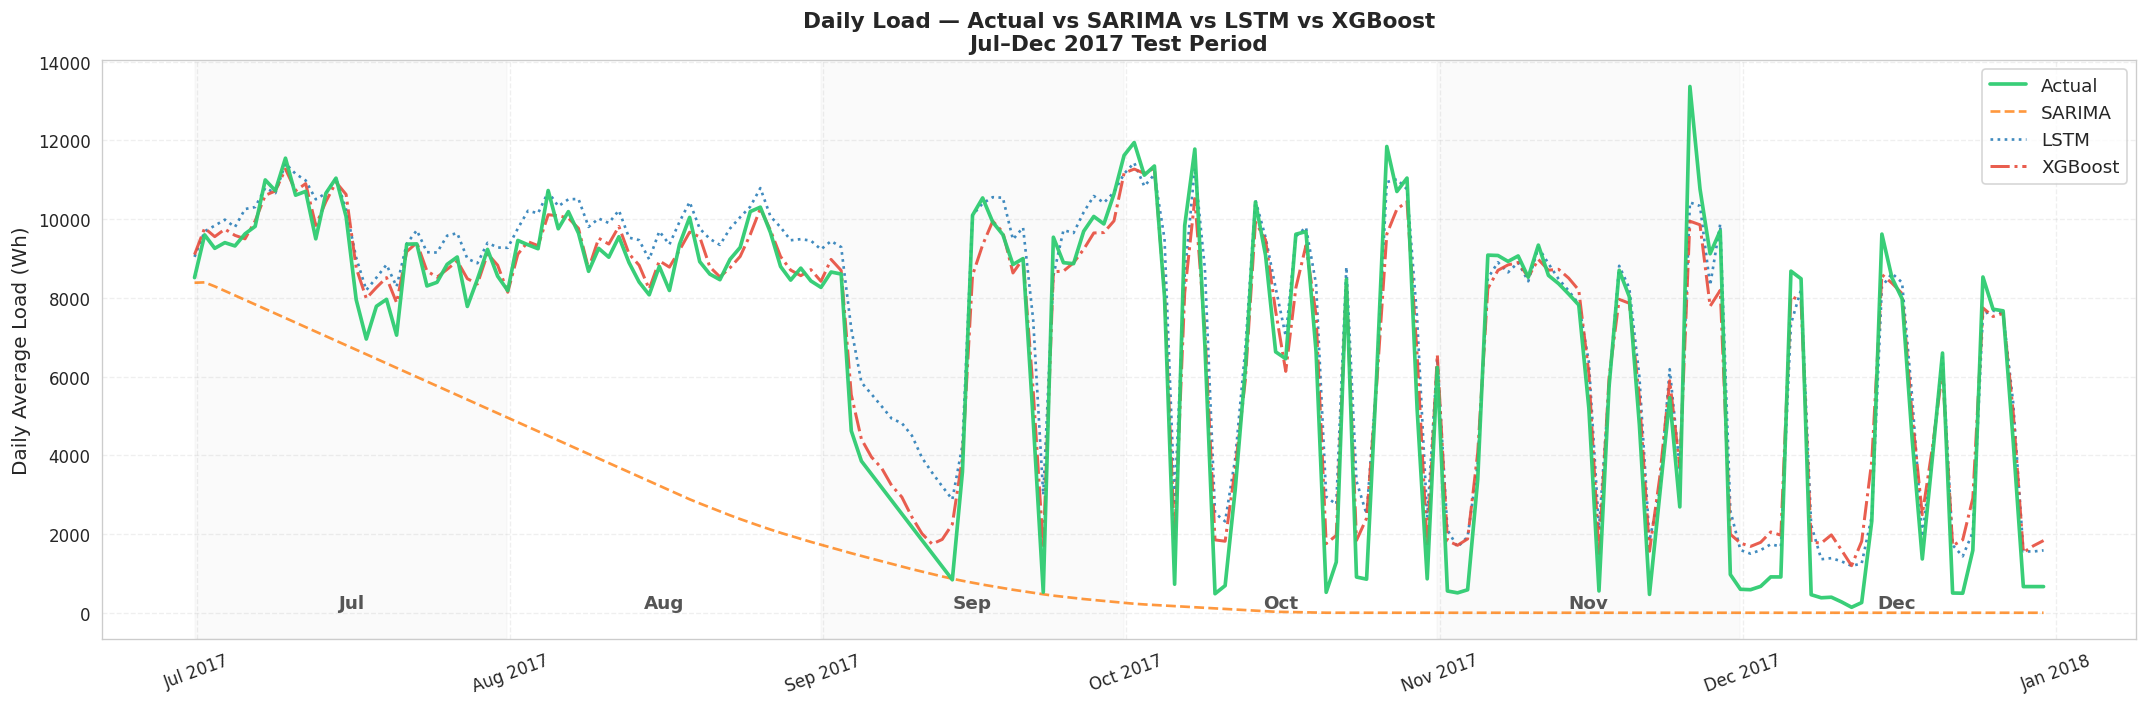

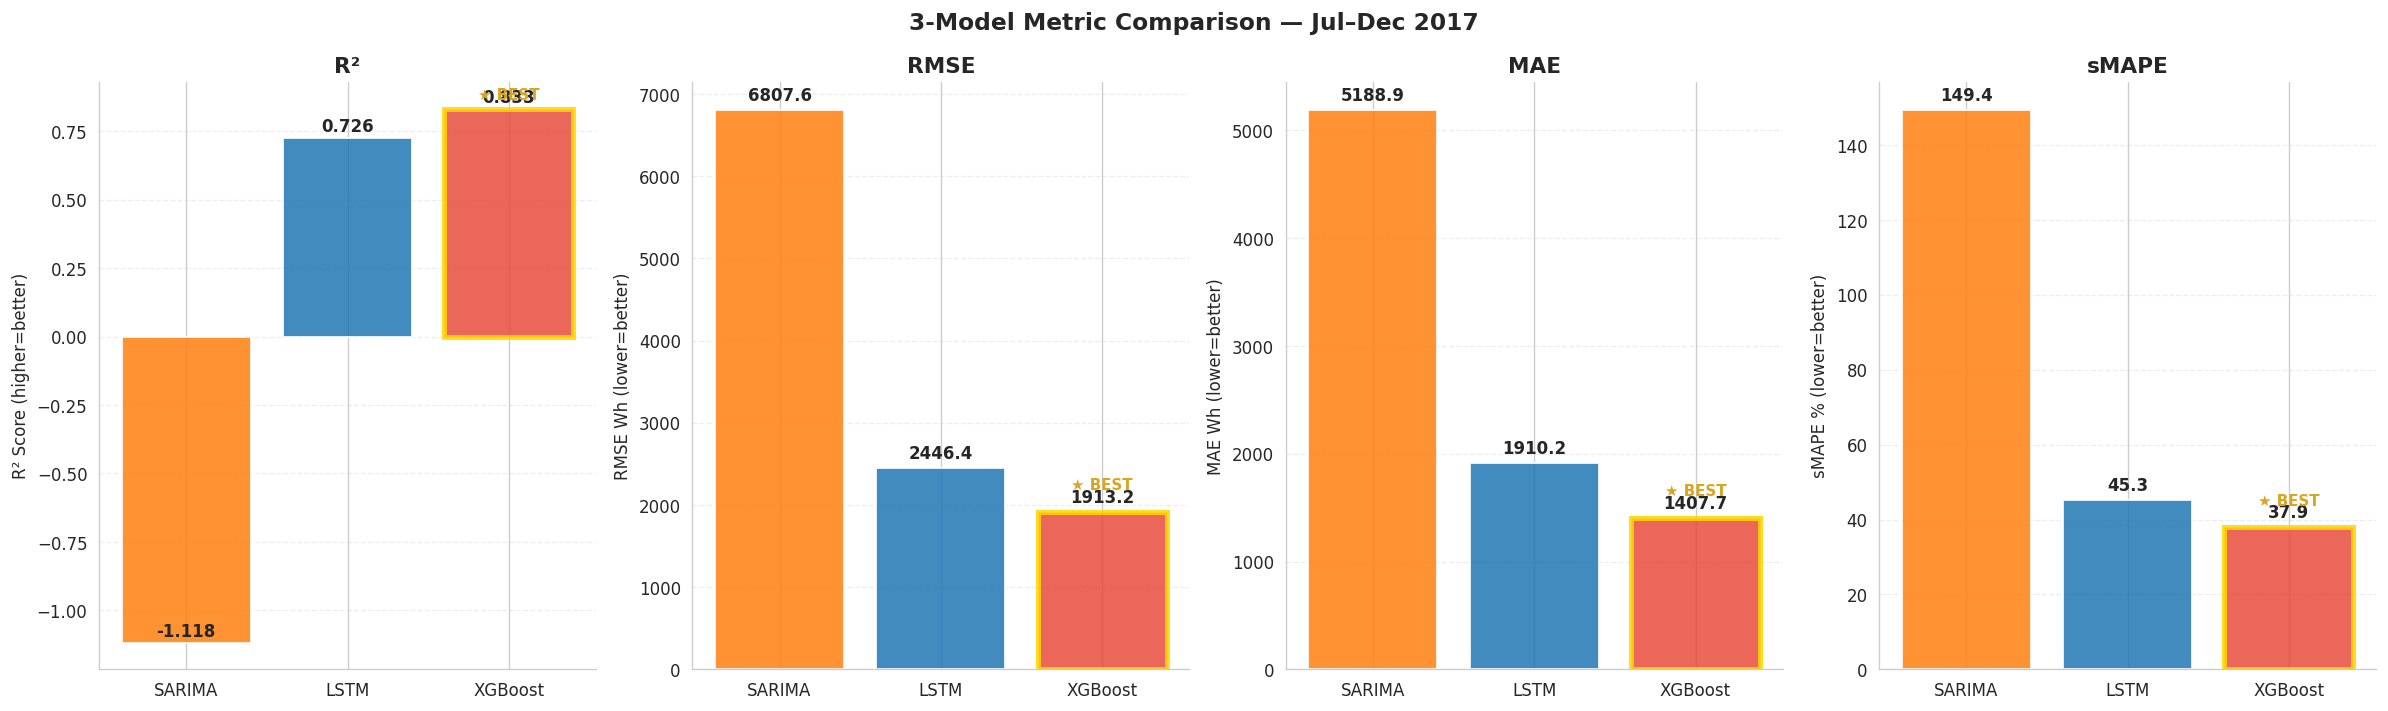

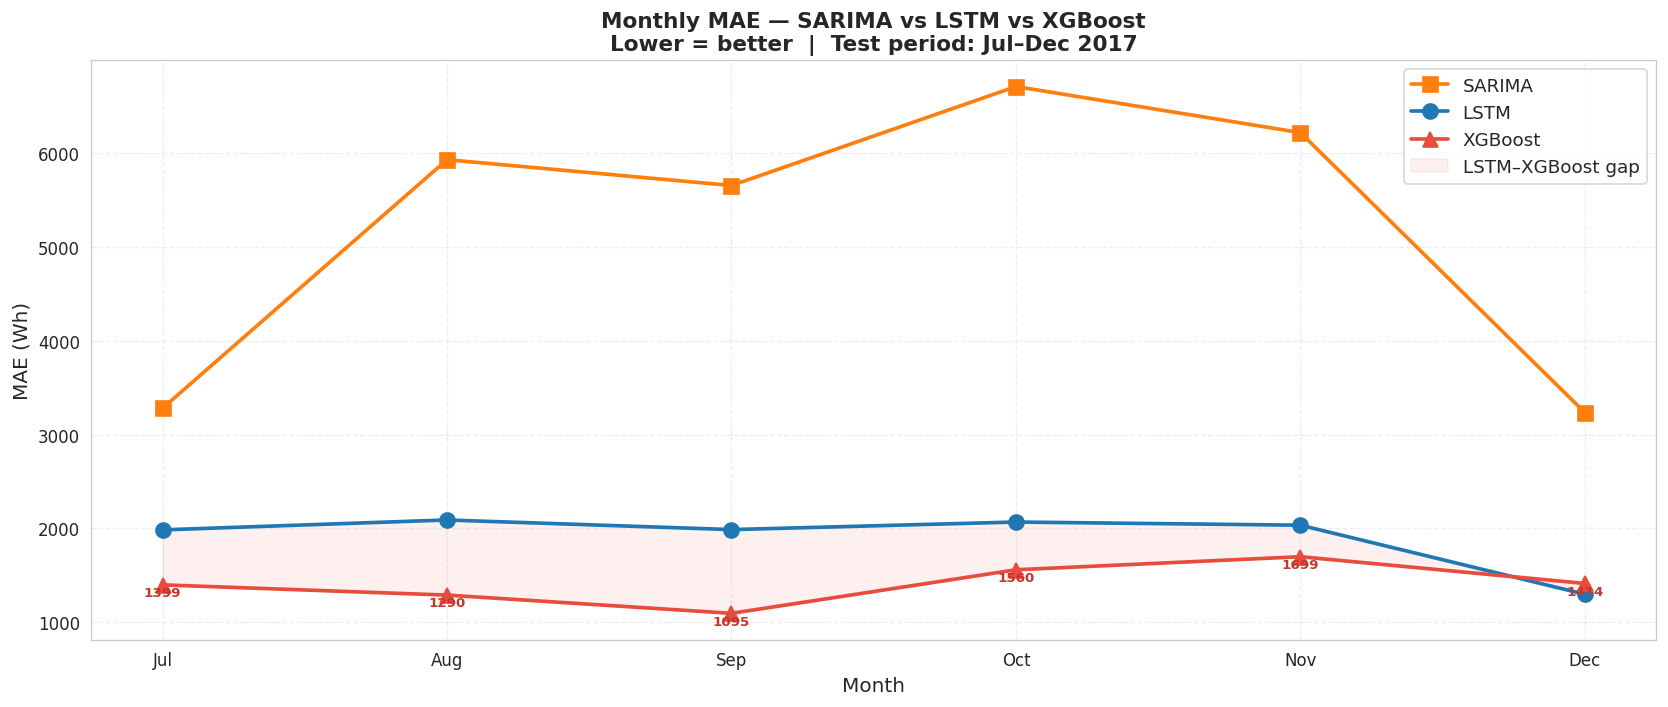

In [ ]:
# ════════════════════════════════════════════════════════════════
# BLOCK D — Full 3-Model Comparison
# Requires: df_sarima_mon, df_lstm_mon, df_xgb_result
# ════════════════════════════════════════════════════════════════

# ── Align on common index ─────────────────────────────────────
common_idx  = df_sarima_mon.index.intersection(
                  df_lstm_mon.index).intersection(df_xgb_result.index)
act_all     = df_sarima_mon.loc[common_idx, 'actual'].values
sar_all     = df_sarima_mon.loc[common_idx, 'predicted'].values
lstm_all    = df_lstm_mon.loc[common_idx, 'predicted'].values
xgb_all     = df_xgb_result.loc[common_idx, 'predicted'].values

m_sar  = calc_metrics(act_all, sar_all)
m_lstm = calc_metrics(act_all, lstm_all)
m_xgb2 = calc_metrics(act_all, xgb_all)

# ── Print summary table ───────────────────────────────────────
print(f"\n{'═'*65}")
print("  3-MODEL COMPARISON — Jul–Dec 2017 (Test Period)")
print(f"{'═'*65}")
print(f"  {'Model':<18} {'R²':>8} {'RMSE (Wh)':>12} "
      f"{'MAE (Wh)':>11} {'sMAPE':>8}")
print(f"  {'-'*61}")
for name, m in [('SARIMA', m_sar),
                ('LSTM Monthly', m_lstm),
                ('XGBoost', m_xgb2)]:
    best_r2   = "★" if m['R2']    == max(m_sar['R2'],
                                          m_lstm['R2'],
                                          m_xgb2['R2']) else " "
    best_rmse = "★" if m['RMSE']  == min(m_sar['RMSE'],
                                          m_lstm['RMSE'],
                                          m_xgb2['RMSE']) else " "
    print(f"  {name:<18} {m['R2']:>7.4f}{best_r2} "
          f"{m['RMSE']:>11.1f}{best_rmse} "
          f"{m['MAE']:>10.1f}   {m['sMAPE']:>6.2f}%")
print(f"{'═'*65}")
print("  ★ = best in that metric")

# ── Monthly avg comparison per model ─────────────────────────
months_all = sorted(set(df_xgb_result['month'].unique()))
labels_all = [month_names[m-1] for m in months_all]
x_all      = np.arange(len(months_all))
w          = 0.22

act_avg  = [df_xgb_result[df_xgb_result['month']==m]['actual'].mean()
            for m in months_all]
sar_avg  = [df_sarima_mon[df_sarima_mon['month']==m]['predicted'].mean()
            if m in df_sarima_mon['month'].values else np.nan
            for m in months_all]
lstm_avg = [df_lstm_mon[df_lstm_mon['month']==m]['predicted'].mean()
            if m in df_lstm_mon['month'].values else np.nan
            for m in months_all]
xgb_avg  = [df_xgb_result[df_xgb_result['month']==m]['predicted'].mean()
            for m in months_all]

# ══════════════════════════════════════════════════════
# COMPARISON PLOT 1 — Monthly avg bar (4-bar cluster)
# ══════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(16, 7))
b0 = ax.bar(x_all - 1.5*w, act_avg,  width=w,
            label='Actual',   color='#2ecc71', alpha=0.9)
b1 = ax.bar(x_all - 0.5*w, sar_avg,  width=w,
            label='SARIMA',   color='#ff7f0e', alpha=0.9)
b2 = ax.bar(x_all + 0.5*w, lstm_avg, width=w,
            label='LSTM',     color='#1f77b4', alpha=0.9)
b3 = ax.bar(x_all + 1.5*w, xgb_avg,  width=w,
            label='XGBoost',  color='#e74c3c', alpha=0.9)

for bars, clr in [(b0,'#27ae60'),(b1,'#e67e22'),
                  (b2,'#2980b9'),(b3,'#c0392b')]:
    for bar in bars:
        h = bar.get_height()
        if not np.isnan(h):
            ax.text(bar.get_x()+bar.get_width()/2,
                    h+60, f'{h:.0f}',
                    ha='center', va='bottom',
                    fontsize=8, color=clr, fontweight='bold')

ax.set_xticks(x_all)
ax.set_xticklabels(labels_all, fontsize=12)
ax.set_ylabel("Average Hourly Load (Wh)", fontsize=12)
ax.set_xlabel("Month (Test Period: Jul–Dec 2017)", fontsize=12)
ax.set_title("Monthly Avg Load — Actual vs SARIMA vs LSTM vs XGBoost\n"
             "Trained: Jan–Jun 2017  |  Tested: Jul–Dec 2017",
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, axis='y', alpha=0.35, linestyle='--')
plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════
# COMPARISON PLOT 2 — Daily time-series overlay
# ══════════════════════════════════════════════════════
common_df = pd.DataFrame({
    'actual' : df_sarima_mon.loc[common_idx, 'actual'],
    'sarima' : df_sarima_mon.loc[common_idx, 'predicted'],
    'lstm'   : df_lstm_mon.loc[common_idx, 'predicted'],
    'xgb'    : df_xgb_result.loc[common_idx, 'predicted']
})
da  = common_df['actual'].resample('D').mean()
ds  = common_df['sarima'].resample('D').mean()
dl  = common_df['lstm'].resample('D').mean()
dx  = common_df['xgb'].resample('D').mean()

fig, ax = plt.subplots(figsize=(18, 6))
ax.plot(da.index, da.values, color='#2ecc71',
        linewidth=2.2, label='Actual', alpha=0.95, zorder=4)
ax.plot(ds.index, ds.values, color='#ff7f0e',
        linewidth=1.6, linestyle='--', label='SARIMA', alpha=0.8)
ax.plot(dl.index, dl.values, color='#1f77b4',
        linewidth=1.6, linestyle=':', label='LSTM', alpha=0.85)
ax.plot(dx.index, dx.values, color='#e74c3c',
        linewidth=1.8, linestyle='-.', label='XGBoost', alpha=0.9)

for k, m in enumerate(months_all):
    m_data = common_df[common_df.index.month == m]
    if len(m_data) == 0: continue
    start, end = m_data.index[0], m_data.index[-1]
    if k % 2 == 0:
        ax.axvspan(start, end, alpha=0.04, color='gray')
    mid = start + (end - start) / 2
    ax.text(mid, da.min() * 0.82, month_names[m-1],
            ha='center', fontsize=11, color='#555',
            fontweight='bold')

ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=20, fontsize=10)
ax.set_ylabel("Daily Average Load (Wh)", fontsize=12)
ax.set_title("Daily Load — Actual vs SARIMA vs LSTM vs XGBoost\n"
             "Jul–Dec 2017 Test Period",
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11, loc='upper right')
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════
# COMPARISON PLOT 3 — Metric radar / grouped bar
# ══════════════════════════════════════════════════════
metrics_df = pd.DataFrame({
    'Model' : ['SARIMA', 'LSTM', 'XGBoost'],
    'R²'    : [m_sar['R2'],   m_lstm['R2'],  m_xgb2['R2']],
    'RMSE'  : [m_sar['RMSE'], m_lstm['RMSE'],m_xgb2['RMSE']],
    'MAE'   : [m_sar['MAE'],  m_lstm['MAE'], m_xgb2['MAE']],
    'sMAPE' : [m_sar['sMAPE'],m_lstm['sMAPE'],m_xgb2['sMAPE']]
})

fig, axes = plt.subplots(1, 4, figsize=(20, 6))
fig.suptitle("3-Model Metric Comparison — Jul–Dec 2017",
             fontsize=14, fontweight='bold')
model_colors = ['#ff7f0e', '#1f77b4', '#e74c3c']

for ax, (col, ylabel, higher_better) in zip(axes, [
        ('R²',    'R² Score (higher=better)',    True),
        ('RMSE',  'RMSE Wh (lower=better)',       False),
        ('MAE',   'MAE Wh (lower=better)',        False),
        ('sMAPE', 'sMAPE % (lower=better)',       False)]):

    vals  = metrics_df[col].values
    best  = np.argmax(vals) if higher_better else np.argmin(vals)
    bars  = ax.bar(metrics_df['Model'], vals,
                   color=model_colors, alpha=0.85,
                   edgecolor='white', linewidth=1.2)
    bars[best].set_edgecolor('gold')
    bars[best].set_linewidth(3)

    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + max(vals)*0.01,
                f'{val:.3f}' if col == 'R²' else f'{val:.1f}',
                ha='center', va='bottom',
                fontsize=10, fontweight='bold')

    ax.set_title(col, fontsize=13, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=10)
    ax.grid(True, axis='y', alpha=0.35, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # Gold star on best bar
    ax.text(best, vals[best] + max(vals)*0.04,
            '★ BEST', ha='center', fontsize=9,
            color='goldenrod', fontweight='bold')

plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════
# COMPARISON PLOT 4 — Monthly MAE: all 3 models
# ══════════════════════════════════════════════════════
xgb_mon_mae = []
for m in months_all:
    g = df_xgb_result[df_xgb_result['month'] == m]
    xgb_mon_mae.append(mean_absolute_error(g['actual'], g['predicted']))

sar_mon_mae2 = []
for m in months_all:
    if m in df_sarima_mon['month'].values:
        g = df_sarima_mon[df_sarima_mon['month'] == m]
        sar_mon_mae2.append(mean_absolute_error(g['actual'],g['predicted']))
    else:
        sar_mon_mae2.append(np.nan)

lstm_mon_mae2 = []
for m in months_all:
    if m in df_lstm_mon['month'].values:
        g = df_lstm_mon[df_lstm_mon['month'] == m]
        lstm_mon_mae2.append(mean_absolute_error(g['actual'],g['predicted']))
    else:
        lstm_mon_mae2.append(np.nan)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(labels_all, sar_mon_mae2,  marker='s', linewidth=2.2,
        markersize=9, label='SARIMA',  color='#ff7f0e')
ax.plot(labels_all, lstm_mon_mae2, marker='o', linewidth=2.2,
        markersize=9, label='LSTM',    color='#1f77b4')
ax.plot(labels_all, xgb_mon_mae,   marker='^', linewidth=2.2,
        markersize=9, label='XGBoost', color='#e74c3c')

ax.fill_between(labels_all, lstm_mon_mae2, xgb_mon_mae,
                alpha=0.08, color='#e74c3c',
                label='LSTM–XGBoost gap')

for i, (sv, lv, xv) in enumerate(
        zip(sar_mon_mae2, lstm_mon_mae2, xgb_mon_mae)):
    ax.text(i, xv - 120, f'{xv:.0f}', ha='center',
            fontsize=8, color='#c0392b', fontweight='bold')

ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("MAE (Wh)", fontsize=12)
ax.set_title("Monthly MAE — SARIMA vs LSTM vs XGBoost\n"
             "Lower = better  |  Test period: Jul–Dec 2017",
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.35, linestyle='--')
plt.tight_layout()
plt.show()

In [ ]:
# ════════════════════════════════════════════════════════════════
# BLOCK E — Final per-month breakdown table
# ════════════════════════════════════════════════════════════════
print(f"\n{'═'*85}")
print("  FINAL MONTHLY BREAKDOWN — SARIMA vs LSTM vs XGBoost")
print(f"{'═'*85}")
print(f"  {'Month':<6} | {'Actual':>8} | "
      f"{'SAR Pred':>9} {'SAR MAE':>9} | "
      f"{'LSTM Pred':>10} {'LSTM MAE':>9} | "
      f"{'XGB Pred':>9} {'XGB MAE':>8}")
print(f"  {'-'*81}")

for m in months_all:
    act  = df_xgb_result[df_xgb_result['month']==m]['actual'].mean()

    sp   = df_sarima_mon[df_sarima_mon['month']==m]['predicted'].mean() \
           if m in df_sarima_mon['month'].values else float('nan')
    sm   = mean_absolute_error(
           df_sarima_mon[df_sarima_mon['month']==m]['actual'],
           df_sarima_mon[df_sarima_mon['month']==m]['predicted']) \
           if m in df_sarima_mon['month'].values else float('nan')

    lp   = df_lstm_mon[df_lstm_mon['month']==m]['predicted'].mean() \
           if m in df_lstm_mon['month'].values else float('nan')
    lm   = mean_absolute_error(
           df_lstm_mon[df_lstm_mon['month']==m]['actual'],
           df_lstm_mon[df_lstm_mon['month']==m]['predicted']) \
           if m in df_lstm_mon['month'].values else float('nan')

    xp   = df_xgb_result[df_xgb_result['month']==m]['predicted'].mean()
    xm   = mean_absolute_error(
           df_xgb_result[df_xgb_result['month']==m]['actual'],
           df_xgb_result[df_xgb_result['month']==m]['predicted'])

    # Highlight best MAE per month
    maes      = [sm, lm, xm]
    best_mae  = np.nanargmin(maes)
    tags      = ['  ', '  ', '  ']
    tags[best_mae] = '★ '

    print(f"  {month_names[m-1]:<6} | {act:>7.0f}W | "
          f"{sp:>8.0f}W {sm:>7.0f}W{tags[0]}| "
          f"{lp:>9.0f}W {lm:>7.0f}W{tags[1]}| "
          f"{xp:>8.0f}W {xm:>6.0f}W{tags[2]}")

print(f"{'═'*85}")
print("  ★ = lowest MAE for that month\n")

# ── Overall winner summary ────────────────────────────────────
print("  OVERALL WINNER SUMMARY")
print(f"  {'Metric':<12} {'SARIMA':>12} {'LSTM':>12} {'XGBoost':>12}")
print(f"  {'-'*50}")
for metric in ['R2', 'RMSE', 'MAE', 'sMAPE']:
    sv, lv, xv = m_sar[metric], m_lstm[metric], m_xgb2[metric]
    if metric == 'R2':
        best = np.argmax([sv, lv, xv])
    else:
        best = np.argmin([sv, lv, xv])
    tags = ['', '', '']
    tags[best] = ' ★'
    print(f"  {metric:<12} {sv:>11.3f}{tags[0]} "
          f"{lv:>11.3f}{tags[1]} "
          f"{xv:>11.3f}{tags[2]}")
print(f"\n  R² closer to 1.0 = better  |  "
      f"RMSE / MAE / sMAPE lower = better")


═════════════════════════════════════════════════════════════════════════════════════
  FINAL MONTHLY BREAKDOWN — SARIMA vs LSTM vs XGBoost
═════════════════════════════════════════════════════════════════════════════════════
  Month  |   Actual |  SAR Pred   SAR MAE |  LSTM Pred  LSTM MAE |  XGB Pred  XGB MAE
  ---------------------------------------------------------------------------------
  Jul    |    9241W |     6792W    3282W  |      9756W    1985W  |     9450W   1399W★ 
  Aug    |    9151W |     3277W    5933W  |      9890W    2091W  |     9211W   1290W★ 
  Sep    |    6274W |      870W    5657W  |      7501W    1988W  |     6376W   1095W★ 
  Oct    |    6773W |       70W    6713W  |      7512W    2069W  |     6868W   1560W★ 
  Nov    |    6221W |        0W    6221W  |      6520W    2035W  |     6319W   1699W★ 
  Dec    |    3236W |        0W    3236W  |      3748W    1299W★ |     3924W   1414W  
═════════════════════════════════════════════════════════════════════════════════

███████████████████████████████████████████████████████
  BLOCK 4 — MONTHLY COMPARISON: SARIMA vs LSTM
███████████████████████████████████████████████████████


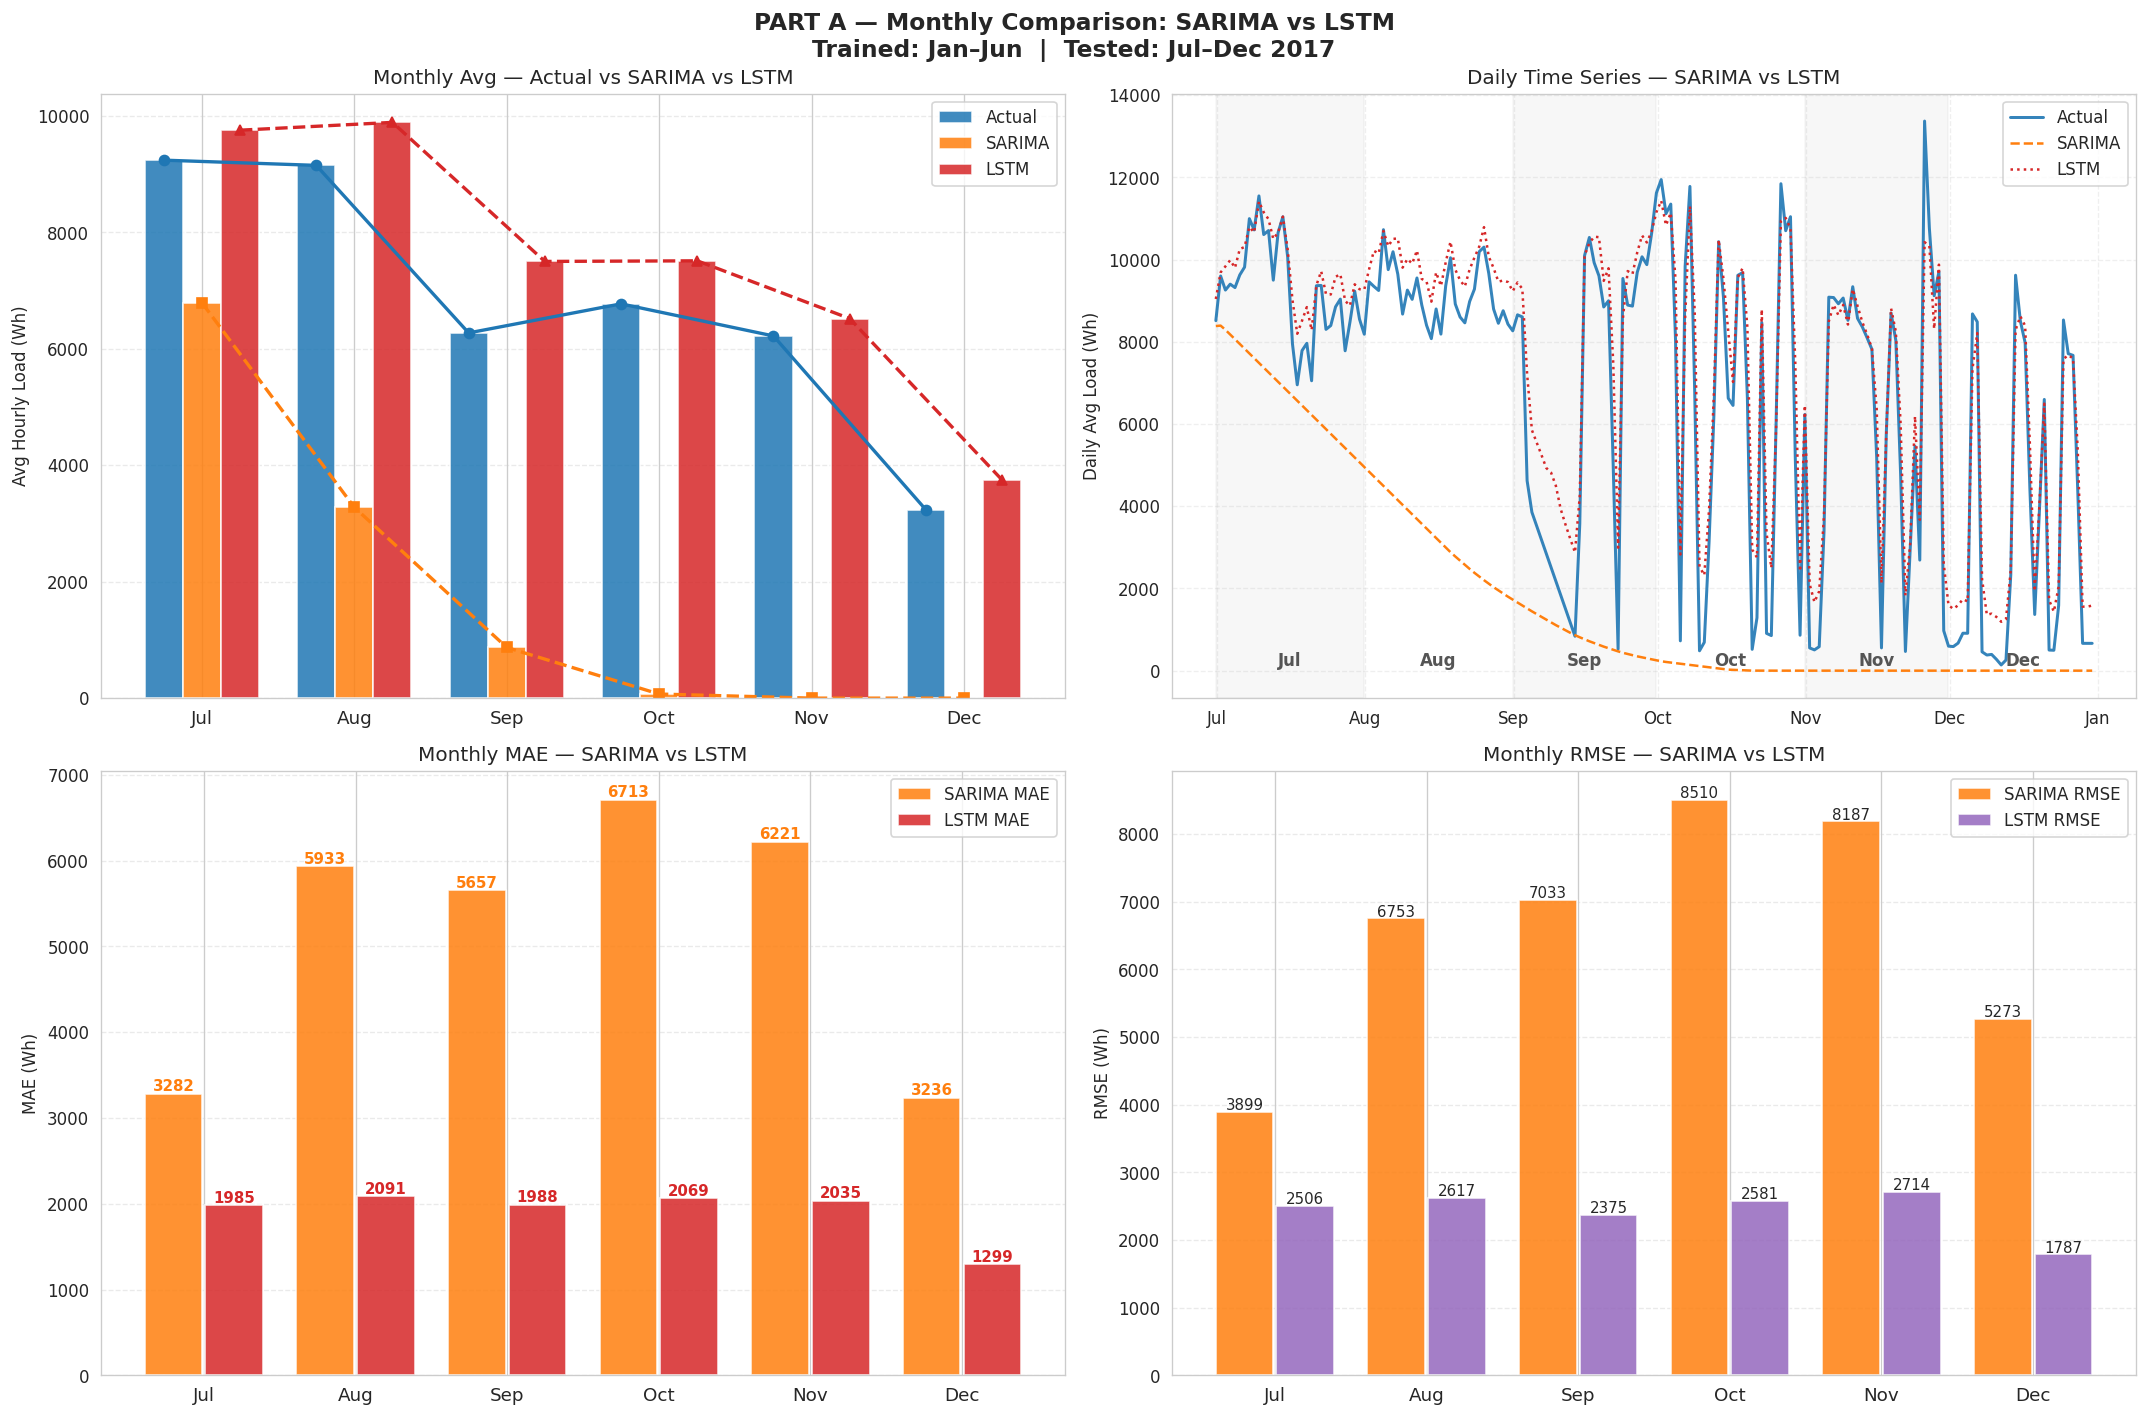


════════════════════════════════════════════════════════════════════
  MONTHLY MODEL COMPARISON
════════════════════════════════════════════════════════════════════
  Month  SARIMA Act  SARIMA Pred  LSTM Pred  SARIMA MAE  LSTM MAE
  ----------------------------------------------------------------
  Jul         9241Wh       6792Wh      9756Wh      3282Wh     1985Wh
  Aug         9151Wh       3277Wh      9890Wh      5933Wh     2091Wh
  Sep         6274Wh        870Wh      7501Wh      5657Wh     1988Wh
  Oct         6773Wh         70Wh      7512Wh      6713Wh     2069Wh
  Nov         6221Wh          0Wh      6520Wh      6221Wh     2035Wh
  Dec         3236Wh          0Wh      3748Wh      3236Wh     1299Wh
════════════════════════════════════════════════════════════════════

✓ Block 4 complete — Monthly comparison done


In [ ]:
# ════════════════════════════════════════════════════════════════
# BLOCK 4 — PART A: SARIMA vs LSTM MONTHLY COMPARISON
# ════════════════════════════════════════════════════════════════

print("█"*55)
print("  BLOCK 4 — MONTHLY COMPARISON: SARIMA vs LSTM")
print("█"*55)

months_cmp = sorted(set(df_sarima_mon['month']) & set(df_lstm_mon['month']))
labels_cmp = [month_names[m-1] for m in months_cmp]
x_cmp      = np.arange(len(months_cmp))
w_bar      = 0.25

act_c  = df_sarima_mon.groupby('month')['actual'].mean()
sar_c  = df_sarima_mon.groupby('month')['predicted'].mean()
lst_c  = df_lstm_mon.groupby('month')['predicted'].mean()

sar_mae_c  = df_sarima_mon.groupby('month').apply(
    lambda g: mean_absolute_error(g['actual'], g['predicted']))
lst_mae_c  = df_lstm_mon.groupby('month').apply(
    lambda g: mean_absolute_error(g['actual'], g['predicted']))
sar_rmse_c = df_sarima_mon.groupby('month').apply(
    lambda g: np.sqrt(mean_squared_error(g['actual'], g['predicted'])))
lst_rmse_c = df_lstm_mon.groupby('month').apply(
    lambda g: np.sqrt(mean_squared_error(g['actual'], g['predicted'])))

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle("PART A — Monthly Comparison: SARIMA vs LSTM\n"
             "Trained: Jan–Jun  |  Tested: Jul–Dec 2017",
             fontsize=14, fontweight='bold')

# ── Plot 1: Triple bar — Actual / SARIMA / LSTM ───────────────
ax = axes[0, 0]
ax.bar(x_cmp - w_bar, act_c[months_cmp].values,
       width=w_bar, label='Actual', color='#1f77b4', alpha=0.85)
ax.bar(x_cmp,         sar_c[months_cmp].values,
       width=w_bar, label='SARIMA', color='#ff7f0e', alpha=0.85)
ax.bar(x_cmp + w_bar, lst_c[months_cmp].values,
       width=w_bar, label='LSTM',   color='#d62728', alpha=0.85)
ax.plot(x_cmp - w_bar, act_c[months_cmp].values,
        color='#1f77b4', marker='o', linewidth=2)
ax.plot(x_cmp,         sar_c[months_cmp].values,
        color='#ff7f0e', marker='s', linewidth=2, linestyle='--')
ax.plot(x_cmp + w_bar, lst_c[months_cmp].values,
        color='#d62728', marker='^', linewidth=2, linestyle='--')
ax.set_xticks(x_cmp)
ax.set_xticklabels(labels_cmp, fontsize=11)
ax.set_ylabel("Avg Hourly Load (Wh)")
ax.set_title("Monthly Avg — Actual vs SARIMA vs LSTM")
ax.legend(); ax.grid(True, axis='y', alpha=0.4, linestyle='--')

# ── Plot 2: Daily time series both models ─────────────────────
ax  = axes[0, 1]
da  = df_sarima_mon['actual'].resample('D').mean()
dsa = df_sarima_mon['predicted'].resample('D').mean()
dls = df_lstm_mon['predicted'].resample('D').mean()
ax.plot(da.index,  da.values,  color='#1f77b4',
        linewidth=1.8, label='Actual', alpha=0.9)
ax.plot(dsa.index, dsa.values, color='#ff7f0e',
        linewidth=1.5, linestyle='--', label='SARIMA')
ax.plot(dls.index, dls.values, color='#d62728',
        linewidth=1.5, linestyle=':', label='LSTM')
for k, m in enumerate(months_cmp):
    m_data = df_sarima_mon[df_sarima_mon['month']==m]
    start, end = m_data.index[0], m_data.index[-1]
    if k % 2 == 0:
        ax.axvspan(start, end, alpha=0.06, color='gray')
    mid = start + (end - start) / 2
    ax.text(mid, da.min()*0.85, month_names[m-1],
            ha='center', fontsize=10, color='#555', fontweight='bold')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.set_ylabel("Daily Avg Load (Wh)")
ax.set_title("Daily Time Series — SARIMA vs LSTM")
ax.legend(); ax.grid(True, alpha=0.3, linestyle='--')

# ── Plot 3: MAE comparison per month ─────────────────────────
ax = axes[1, 0]
ax.bar(x_cmp - 0.2, sar_mae_c[months_cmp].values,
       width=0.38, label='SARIMA MAE', color='#ff7f0e', alpha=0.85)
ax.bar(x_cmp + 0.2, lst_mae_c[months_cmp].values,
       width=0.38, label='LSTM MAE',   color='#d62728', alpha=0.85)
for i,(sv,lv) in enumerate(zip(sar_mae_c[months_cmp].values,
                                lst_mae_c[months_cmp].values)):
    ax.text(i-0.2, sv+30, f'{sv:.0f}', ha='center', fontsize=9,
            color='#ff7f0e', fontweight='bold')
    ax.text(i+0.2, lv+30, f'{lv:.0f}', ha='center', fontsize=9,
            color='#d62728', fontweight='bold')
ax.set_xticks(x_cmp)
ax.set_xticklabels(labels_cmp, fontsize=11)
ax.set_ylabel("MAE (Wh)")
ax.set_title("Monthly MAE — SARIMA vs LSTM")
ax.legend(); ax.grid(True, axis='y', alpha=0.4, linestyle='--')

# ── Plot 4: RMSE comparison per month ────────────────────────
ax = axes[1, 1]
ax.bar(x_cmp - 0.2, sar_rmse_c[months_cmp].values,
       width=0.38, label='SARIMA RMSE', color='#ff7f0e', alpha=0.85)
ax.bar(x_cmp + 0.2, lst_rmse_c[months_cmp].values,
       width=0.38, label='LSTM RMSE',   color='#9467bd', alpha=0.85)
for i,(sv,lv) in enumerate(zip(sar_rmse_c[months_cmp].values,
                                lst_rmse_c[months_cmp].values)):
    ax.text(i-0.2, sv+30, f'{sv:.0f}', ha='center', fontsize=9)
    ax.text(i+0.2, lv+30, f'{lv:.0f}', ha='center', fontsize=9)
ax.set_xticks(x_cmp)
ax.set_xticklabels(labels_cmp, fontsize=11)
ax.set_ylabel("RMSE (Wh)")
ax.set_title("Monthly RMSE — SARIMA vs LSTM")
ax.legend(); ax.grid(True, axis='y', alpha=0.4, linestyle='--')

plt.tight_layout()
plt.show()

# Monthly metrics table
print(f"\n{'═'*68}")
print("  MONTHLY MODEL COMPARISON")
print(f"{'═'*68}")
print(f"  {'Month':<6} {'SARIMA Act':>10} {'SARIMA Pred':>12}"
      f" {'LSTM Pred':>10} {'SARIMA MAE':>11} {'LSTM MAE':>9}")
print(f"  {'-'*64}")
for m in months_cmp:
    print(f"  {month_names[m-1]:<6} {act_c[m]:>9.0f}Wh"
          f" {sar_c[m]:>10.0f}Wh  {lst_c[m]:>8.0f}Wh"
          f" {sar_mae_c[m]:>9.0f}Wh  {lst_mae_c[m]:>7.0f}Wh")
print(f"{'═'*68}")

print("\n✓ Block 4 complete — Monthly comparison done")

In [ ]:
dec2016 = df_hourly.loc['2016-12-01':'2016-12-31']

print(f"Total hours      : {len(dec2016)}")
print(f"Date range       : {dec2016.index[0]} → {dec2016.index[-1]}")
print(f"Missing hours    : {744 - len(dec2016)}")
print(f"\nDaily row count:")
print(dec2016.groupby(dec2016.index.date).size())
print(f"\nW statistics:")
print(dec2016['W'].describe().round(2))

Total hours      : 411
Date range       : 2016-12-14 21:00:00+05:30 → 2016-12-31 23:00:00+05:30
Missing hours    : 333

Daily row count:
2016-12-14     3
2016-12-15    24
2016-12-16    24
2016-12-17    24
2016-12-18    24
2016-12-19    24
2016-12-20    24
2016-12-21    24
2016-12-22    24
2016-12-23    24
2016-12-24    24
2016-12-25    24
2016-12-26    24
2016-12-27    24
2016-12-28    24
2016-12-29    24
2016-12-30    24
2016-12-31    24
dtype: int64

W statistics:
count      411.00
mean      4365.76
std       3312.76
min          0.00
25%       1878.67
50%       4157.51
75%       6839.21
max      16701.36
Name: W, dtype: float64


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 120

# ── Clean Dec 2016 ────────────────────────────────────────────
dec2016       = df_hourly.loc['2016-12-15':'2016-12-31'].copy()
dec2016['W']  = dec2016['W'].replace(0, np.nan)
dec2016['W']  = dec2016['W'].interpolate(method='linear')
dec2016['W']  = dec2016['W'].fillna(dec2016['W'].median())

# ── Train / Test split ────────────────────────────────────────
train = dec2016.loc['2016-12-15':'2016-12-28']['W']
test  = dec2016.loc['2016-12-29':'2016-12-31']['W']

print(f"Train : {len(train)} hours  ({train.index[0].date()} → {train.index[-1].date()})")
print(f"Test  : {len(test)}  hours  ({test.index[0].date()}  → {test.index[-1].date()})")
print(f"\nTrain W stats:\n{train.describe().round(2)}")
print(f"\nTest  W stats:\n{test.describe().round(2)}")

Train : 336 hours  (2016-12-15 → 2016-12-28)
Test  : 72  hours  (2016-12-29  → 2016-12-31)

Train W stats:
count      336.00
mean      4417.60
std       2931.64
min         45.06
25%       2366.41
50%       3817.16
75%       6363.17
max      16701.36
Name: W, dtype: float64

Test  W stats:
count       72.00
mean      6140.76
std       2638.78
min       2309.42
25%       3954.51
50%       5816.35
75%       7691.35
max      13224.76
Name: W, dtype: float64


In [ ]:
# ── ADF test ──────────────────────────────────────────────────
adf = adfuller(train.dropna())
print(f"ADF Statistic : {adf[0]:.4f}")
print(f"ADF p-value   : {adf[1]:.4f} → "
      f"{'Stationary ✓' if adf[1] < 0.05 else 'Non-stationary → will use d=1'}")

# ── Fit SARIMA(1,1,1)(1,1,1,24) ──────────────────────────────
print("\nFitting SARIMA(1,1,1)(1,1,1,24)...")
sarima = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 24),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=300)

print(f"AIC : {sarima.aic:.2f}")
print(f"BIC : {sarima.bic:.2f}")
print(sarima.summary().tables[1])

ADF Statistic : -2.4432
ADF p-value   : 0.1299 → Non-stationary → will use d=1

Fitting SARIMA(1,1,1)(1,1,1,24)...
AIC : 5014.21
BIC : 5032.47
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3494      0.088      3.954      0.000       0.176       0.523
ma.L1         -0.7072      0.077     -9.227      0.000      -0.857      -0.557
ar.S.L24       0.1193      0.066      1.804      0.071      -0.010       0.249
ma.S.L24      -1.0380      0.183     -5.684      0.000      -1.396      -0.680
sigma2      2.139e+06   4.72e+05      4.530      0.000    1.21e+06    3.06e+06


In [ ]:
# ── 2018 Data Inspection ──────────────────────────────────────
df_2018 = df_hourly.loc['2018-01-01':'2018-12-31'].copy()

print(f"Total hours      : {len(df_2018)}")
print(f"Date range       : {df_2018.index[0]} → {df_2018.index[-1]}")

print(f"\nRow count by month:")
print(df_2018.groupby(df_2018.index.month).size()
      .rename(index={1:'Jan',2:'Feb',3:'Mar',4:'Apr',
                     5:'May',6:'Jun',7:'Jul',8:'Aug',
                     9:'Sep',10:'Oct',11:'Nov',12:'Dec'}))

print(f"\nDaily row count (first and last 5 days):")
daily = df_2018.groupby(df_2018.index.date).size()
print("First 5 days:")
print(daily.head(5))
print("Last 5 days:")
print(daily.tail(5))

print(f"\nMissing hours check:")
full_idx     = pd.date_range(df_2018.index[0],
                              df_2018.index[-1],
                              freq='h', tz='Asia/Kolkata')
missing      = full_idx.difference(df_2018.index)
print(f"Missing slots    : {len(missing)}")

print(f"\nW statistics:")
print(df_2018['W'].describe().round(2))

print(f"\nZero/null values : {(df_2018['W'] == 0).sum()} zeros, "
      f"{df_2018['W'].isnull().sum()} nulls")

Total hours      : 3720
Date range       : 2018-01-01 00:00:00+05:30 → 2018-06-04 23:00:00+05:30

Row count by month:
datetime
Jan    744
Feb    672
Mar    744
Apr    720
May    744
Jun     96
dtype: int64

Daily row count (first and last 5 days):
First 5 days:
2018-01-01    24
2018-01-02    24
2018-01-03    24
2018-01-04    24
2018-01-05    24
dtype: int64
Last 5 days:
2018-05-31    24
2018-06-01    24
2018-06-02    24
2018-06-03    24
2018-06-04    24
dtype: int64

Missing hours check:
Missing slots    : 0

W statistics:
count     3720.00
mean       916.65
std       4197.58
min          0.00
25%          0.00
50%          0.00
75%          0.00
max      38856.42
Name: W, dtype: float64

Zero/null values : 3506 zeros, 0 nulls


In [ ]:
nz = df_2018[df_2018['W'] > 0]
print(nz.groupby(nz.index.date).size())

2018-05-24    24
2018-05-25    24
2018-05-26    24
2018-05-27    24
2018-05-28    24
2018-05-29    24
2018-05-30    24
2018-05-31    24
2018-06-01    14
2018-06-04     8
dtype: int64


In [ ]:
# ════════════════════════════════════════════════════════════════
# DASHBOARD GENERATOR — Run after all 6 blocks complete
# Extracts real results → writes dashboard HTML → download it
# ════════════════════════════════════════════════════════════════

import json
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ── Helper ────────────────────────────────────────────────────
def safe_smape(a, p):
    d = (np.abs(a) + np.abs(p)) / 2
    d = np.where(d < 1e-8, 1e-8, d)
    return float(np.mean(np.abs(a - p) / d) * 100)

def get_metrics(actual, predicted):
    mask  = np.array(actual) > 100
    a, p  = np.array(actual)[mask], np.array(predicted)[mask]
    return {
        'R2'   : round(float(r2_score(a, p)), 4),
        'RMSE' : round(float(np.sqrt(mean_squared_error(a, p))), 2),
        'MAE'  : round(float(mean_absolute_error(a, p)), 2),
        'sMAPE': round(safe_smape(a, p), 2)
    }

month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

# ════════════════════════════════════════════════════════════════
# EXTRACT ALL RESULTS FROM YOUR PYTHON VARIABLES
# ════════════════════════════════════════════════════════════════

print("Extracting results...")

# ── Monthly averages per model ────────────────────────────────
months_test    = sorted(df_sarima_mon['month'].unique())
labels_test    = [month_names[m-1] for m in months_test]

actual_mon_avg = [round(float(df_sarima_mon[df_sarima_mon['month']==m]['actual'].mean()),1)
                  for m in months_test]
sarima_mon_avg = [round(float(df_sarima_mon[df_sarima_mon['month']==m]['predicted'].mean()),1)
                  for m in months_test]
lstm_mon_avg   = [round(float(df_lstm_mon[df_lstm_mon['month']==m]['predicted'].mean()),1)
                  for m in months_test]

# ── Daily averages ────────────────────────────────────────────
daily_actual_s = df_sarima_mon['actual'].resample('D').mean().dropna()
daily_sarima_s = df_sarima_mon['predicted'].resample('D').mean().dropna()
daily_lstm_s   = df_lstm_mon['predicted'].resample('D').mean().dropna()

n_days         = min(len(daily_actual_s), len(daily_sarima_s), len(daily_lstm_s))
daily_labels   = [d.strftime('%d %b') for d in daily_actual_s.index[:n_days]]
daily_actual   = [round(float(v),1) for v in daily_actual_s.values[:n_days]]
daily_sarima   = [round(float(v),1) for v in daily_sarima_s.values[:n_days]]
daily_lstm     = [round(float(v),1) for v in daily_lstm_s.values[:n_days]]

# ── Hourly profile (avg across all test months) ───────────────
hourly_actual  = [round(float(df_sarima_mon.groupby(
                     df_sarima_mon.index.hour)['actual'].mean()[h]),1)
                  for h in range(24)]
hourly_sarima  = [round(float(df_sarima_mon.groupby(
                     df_sarima_mon.index.hour)['predicted'].mean()[h]),1)
                  for h in range(24)]
hourly_lstm    = [round(float(df_lstm_mon.groupby(
                     df_lstm_mon.index.hour)['predicted'].mean()[h]),1)
                  for h in range(24)]

# ── Per-month errors ──────────────────────────────────────────
def monthly_err(df, metric='mae'):
    out = []
    for m in months_test:
        g = df[df['month'] == m]
        a, p = g['actual'].values, g['predicted'].values
        if metric == 'mae':
            out.append(round(float(mean_absolute_error(a, p)), 1))
        else:
            out.append(round(float(np.sqrt(mean_squared_error(a, p))), 1))
    return out

sarima_mon_mae  = monthly_err(df_sarima_mon, 'mae')
sarima_mon_rmse = monthly_err(df_sarima_mon, 'rmse')
lstm_mon_mae    = monthly_err(df_lstm_mon,   'mae')
lstm_mon_rmse   = monthly_err(df_lstm_mon,   'rmse')

# ── Daily model monthly avgs ──────────────────────────────────
months_day     = sorted(set(df_sarima_day['month'].unique()) &
                         set(df_lstm_day['month'].unique()))
labels_day     = [month_names[m-1] for m in months_day]
actual_day_avg = [round(float(df_sarima_day[df_sarima_day['month']==m]['actual'].mean()),1)
                  for m in months_day]
sarima_day_avg = [round(float(df_sarima_day[df_sarima_day['month']==m]['predicted'].mean()),1)
                  for m in months_day]
lstm_day_avg   = [round(float(df_lstm_day[df_lstm_day['month']==m]['predicted'].mean()),1)
                  for m in months_day]

sarima_day_mae  = [round(float(mean_absolute_error(
    df_sarima_day[df_sarima_day['month']==m]['actual'],
    df_sarima_day[df_sarima_day['month']==m]['predicted'])),1)
    for m in months_day]
lstm_day_mae    = [round(float(mean_absolute_error(
    df_lstm_day[df_lstm_day['month']==m]['actual'],
    df_lstm_day[df_lstm_day['month']==m]['predicted'])),1)
    for m in months_day]
sarima_day_rmse = [round(float(np.sqrt(mean_squared_error(
    df_sarima_day[df_sarima_day['month']==m]['actual'],
    df_sarima_day[df_sarima_day['month']==m]['predicted']))),1)
    for m in months_day]
lstm_day_rmse   = [round(float(np.sqrt(mean_squared_error(
    df_lstm_day[df_lstm_day['month']==m]['actual'],
    df_lstm_day[df_lstm_day['month']==m]['predicted']))),1)
    for m in months_day]

# ── Hourly profile for daily model ───────────────────────────
hourly_sarima_d = [round(float(df_sarima_day.groupby('hour')['predicted'].mean()[h]),1)
                   for h in range(24)]
hourly_lstm_d   = [round(float(df_lstm_day.groupby('hour')['predicted'].mean()[h]),1)
                   for h in range(24)]
hourly_actual_d = [round(float(df_sarima_day.groupby('hour')['actual'].mean()[h]),1)
                   for h in range(24)]

# ── Overall metrics ───────────────────────────────────────────
m_sm = get_metrics(df_sarima_mon['actual'], df_sarima_mon['predicted'])
m_lm = get_metrics(df_lstm_mon['actual'],   df_lstm_mon['predicted'])
m_sd = get_metrics(df_sarima_day['actual'], df_sarima_day['predicted'])
m_ld = get_metrics(df_lstm_day['actual'],   df_lstm_day['predicted'])

# ── Weekly pattern (daily model) ─────────────────────────────
day_names_py  = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
weekly_actual = {}
weekly_lstm   = {}
weekly_sarima = {}
for day in day_names_py:
    sd = df_sarima_day[df_sarima_day['day_name'] == day]
    ld = df_lstm_day[df_lstm_day['day_name']   == day]
    if len(sd) > 0:
        weekly_actual[day]  = [round(float(v),1) for v in
                                sd.groupby('hour')['actual'].mean().values]
        weekly_sarima[day]  = [round(float(v),1) for v in
                                sd.groupby('hour')['predicted'].mean().values]
        weekly_lstm[day]    = [round(float(v),1) for v in
                                ld.groupby('hour')['predicted'].mean().values]

print("✓ All data extracted")
print(f"  Monthly test months : {labels_test}")
print(f"  Daily days          : {n_days}")
print(f"  LSTM Monthly R²     : {m_lm['R2']}")
print(f"  SARIMA Monthly R²   : {m_sm['R2']}")
print(f"  LSTM Daily R²       : {m_ld['R2']}")
print(f"  SARIMA Daily R²     : {m_sd['R2']}")

# ════════════════════════════════════════════════════════════════
# BUILD DATA OBJECT
# ════════════════════════════════════════════════════════════════

DATA = {
    # Monthly model
    'months_test'     : labels_test,
    'actual_mon_avg'  : actual_mon_avg,
    'sarima_mon_avg'  : sarima_mon_avg,
    'lstm_mon_avg'    : lstm_mon_avg,
    'sarima_mon_mae'  : sarima_mon_mae,
    'sarima_mon_rmse' : sarima_mon_rmse,
    'lstm_mon_mae'    : lstm_mon_mae,
    'lstm_mon_rmse'   : lstm_mon_rmse,

    # Daily avg series
    'daily_labels'    : daily_labels,
    'daily_actual'    : daily_actual,
    'daily_sarima'    : daily_sarima,
    'daily_lstm'      : daily_lstm,

    # Hourly profile — monthly model
    'hours'           : [f'{h}:00' for h in range(24)],
    'hourly_actual_m' : hourly_actual,
    'hourly_sarima_m' : hourly_sarima,
    'hourly_lstm_m'   : hourly_lstm,

    # Daily model monthly
    'months_day'      : labels_day,
    'actual_day_avg'  : actual_day_avg,
    'sarima_day_avg'  : sarima_day_avg,
    'lstm_day_avg'    : lstm_day_avg,
    'sarima_day_mae'  : sarima_day_mae,
    'sarima_day_rmse' : sarima_day_rmse,
    'lstm_day_mae'    : lstm_day_mae,
    'lstm_day_rmse'   : lstm_day_rmse,

    # Hourly profile — daily model
    'hourly_actual_d' : hourly_actual_d,
    'hourly_sarima_d' : hourly_sarima_d,
    'hourly_lstm_d'   : hourly_lstm_d,

    # Weekly pattern
    'weekly_actual'   : weekly_actual,
    'weekly_sarima'   : weekly_sarima,
    'weekly_lstm'     : weekly_lstm,

    # Final metrics
    'metrics': {
        'sarima_monthly': m_sm,
        'lstm_monthly'  : m_lm,
        'sarima_daily'  : m_sd,
        'lstm_daily'    : m_ld,
    }
}

data_json = json.dumps(DATA, indent=2)
print("\n✓ DATA object ready")


Extracting results...


NameError: name 'df_sarima_day' is not defined

In [ ]:
# ════════════════════════════════════════════════════════════════
# WRITE FULL DASHBOARD HTML
# ════════════════════════════════════════════════════════════════

html = f"""<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8"/>
<meta name="viewport" content="width=device-width, initial-scale=1.0"/>
<title>Electricity Forecasting — IIT Bombay 2017</title>
<script src="https://cdnjs.cloudflare.com/ajax/libs/Chart.js/4.4.1/chart.umd.min.js"></script>
<link href="https://fonts.googleapis.com/css2?family=Space+Mono:wght@400;700&family=DM+Sans:wght@300;400;500;600&display=swap" rel="stylesheet"/>
<style>
:root {{
  --bg:#0a0e1a; --bg2:#111827; --bg3:#1a2235;
  --border:#1f2d45; --card:#131c2e;
  --accent:#00d4ff; --accent2:#ff6b35; --accent3:#7cfc5e;
  --text:#e8f0fe; --muted:#6b7fa3;
  --lstm:#00d4ff; --sarima:#ff6b35; --actual:#7cfc5e;
  --font-mono:'Space Mono',monospace;
  --font-body:'DM Sans',sans-serif;
}}
*,*::before,*::after{{box-sizing:border-box;margin:0;padding:0}}
body{{background:var(--bg);color:var(--text);font-family:var(--font-body);font-size:14px;min-height:100vh;overflow-x:hidden}}
body::before{{content:'';position:fixed;inset:0;background-image:linear-gradient(rgba(0,212,255,0.02) 1px,transparent 1px),linear-gradient(90deg,rgba(0,212,255,0.02) 1px,transparent 1px);background-size:40px 40px;pointer-events:none;z-index:0}}
header{{position:relative;z-index:10;display:flex;align-items:center;justify-content:space-between;padding:16px 28px;border-bottom:1px solid var(--border);background:rgba(10,14,26,0.97)}}
.logo{{font-family:var(--font-mono);font-size:13px;font-weight:700;color:var(--accent);letter-spacing:2px;text-transform:uppercase}}
.logo span{{color:var(--muted);font-weight:400}}
.hm{{display:flex;align-items:center;gap:14px}}
.badge{{font-family:var(--font-mono);font-size:10px;font-weight:700;padding:3px 9px;border-radius:2px;text-transform:uppercase;letter-spacing:1px}}
.bg{{background:rgba(124,252,94,0.12);color:var(--actual);border:1px solid rgba(124,252,94,0.3)}}
.bb{{background:rgba(0,212,255,0.12);color:var(--accent);border:1px solid rgba(0,212,255,0.3)}}
.bo{{background:rgba(255,107,53,0.12);color:var(--sarima);border:1px solid rgba(255,107,53,0.3)}}
.layout{{position:relative;z-index:1;display:grid;grid-template-columns:268px 1fr;min-height:calc(100vh - 57px)}}
.sidebar{{background:var(--card);border-right:1px solid var(--border);padding:20px 16px;display:flex;flex-direction:column;gap:20px;overflow-y:auto}}
.sl{{font-family:var(--font-mono);font-size:10px;font-weight:700;color:var(--muted);letter-spacing:2px;text-transform:uppercase;padding-bottom:6px;border-bottom:1px solid var(--border)}}
.ss{{display:flex;flex-direction:column;gap:8px}}
.ctrl{{display:flex;flex-direction:column;gap:4px}}
.ctrl label{{font-size:11px;color:var(--muted);font-family:var(--font-mono)}}
.ctrl select,.ctrl input[type=range]{{width:100%;background:var(--bg3);border:1px solid var(--border);color:var(--text);border-radius:3px;font-family:var(--font-mono);font-size:11px;padding:6px 9px;appearance:none;cursor:pointer;transition:border-color .2s}}
.ctrl select:hover,.ctrl select:focus{{border-color:var(--accent);outline:none}}
.ctrl input[type=range]{{padding:0;height:4px;accent-color:var(--accent)}}
.rrow{{display:flex;justify-content:space-between;font-family:var(--font-mono);font-size:10px;color:var(--muted)}}
.rv{{color:var(--accent);font-weight:700}}
.tg{{display:flex;flex-direction:column;gap:5px}}
.ti{{display:flex;align-items:center;justify-content:space-between;padding:6px 9px;background:var(--bg3);border:1px solid var(--border);border-radius:3px;cursor:pointer;transition:all .2s}}
.ti:hover{{border-color:var(--accent)}}
.ti.al{{border-color:var(--actual);background:rgba(124,252,94,0.07)}}
.ti.alstm{{border-color:var(--lstm);background:rgba(0,212,255,0.07)}}
.ti.alsar{{border-color:var(--sarima);background:rgba(255,107,53,0.07)}}
.tn{{font-family:var(--font-mono);font-size:10px;font-weight:700;text-transform:uppercase}}
.t-a{{color:var(--actual)}}.t-l{{color:var(--lstm)}}.t-s{{color:var(--sarima)}}
.td{{width:7px;height:7px;border-radius:50%;transition:opacity .2s}}
.da{{background:var(--actual)}}.dl{{background:var(--lstm)}}.ds{{background:var(--sarima)}}
.ti:not(.al):not(.alstm):not(.alsar) .td{{opacity:0.15}}
.rbtn{{width:100%;padding:10px;background:linear-gradient(135deg,var(--accent),#0099bb);border:none;border-radius:3px;color:#0a0e1a;font-family:var(--font-mono);font-size:11px;font-weight:700;letter-spacing:2px;text-transform:uppercase;cursor:pointer;transition:all .2s}}
.rbtn:hover{{opacity:.88;transform:translateY(-1px)}}
.gbtn{{background:linear-gradient(135deg,#7cfc5e,#3da832);margin-top:2px}}
.main{{display:flex;flex-direction:column;overflow-y:auto}}
.mrow{{display:grid;grid-template-columns:repeat(4,1fr);gap:10px;padding:16px 20px 0}}
.mc{{background:var(--card);border:1px solid var(--border);border-radius:5px;padding:12px 14px;position:relative;overflow:hidden}}
.mc::before{{content:'';position:absolute;top:0;left:0;width:3px;height:100%}}
.mc-l::before{{background:var(--lstm)}}.mc-s::before{{background:var(--sarima)}}
.mc-r::before{{background:var(--actual)}}.mc-p::before{{background:#a78bfa}}
.ml{{font-family:var(--font-mono);font-size:9px;color:var(--muted);text-transform:uppercase;letter-spacing:1.5px;margin-bottom:5px}}
.mv{{font-family:var(--font-mono);font-size:20px;font-weight:700;line-height:1}}
.ms{{font-size:10px;color:var(--muted);margin-top:3px}}
.vl{{color:var(--lstm)}}.vs{{color:var(--sarima)}}.va{{color:var(--actual)}}.vp{{color:#a78bfa}}
.charts{{padding:16px 20px;display:grid;grid-template-columns:1fr 1fr;gap:14px;flex:1}}
.cc{{background:var(--card);border:1px solid var(--border);border-radius:7px;padding:14px;transition:border-color .2s}}
.cc:hover{{border-color:#2a3d5a}}
.span2{{grid-column:span 2}}
.ct{{font-family:var(--font-mono);font-size:10px;font-weight:700;color:var(--muted);letter-spacing:1.5px;text-transform:uppercase;margin-bottom:10px;display:flex;align-items:center;gap:7px}}
.ct::before{{content:'';display:inline-block;width:7px;height:7px;border-radius:50%}}
.ct-m::before{{background:var(--accent)}}.ct-d::before{{background:var(--accent2)}}
.ct-e::before{{background:#a78bfa}}.ct-c::before{{background:var(--actual)}}
.ct-w::before{{background:#f9ca24}}
canvas{{width:100%!important}}
.sbar{{position:relative;z-index:10;display:flex;align-items:center;gap:12px;padding:7px 28px;border-top:1px solid var(--border);background:rgba(10,14,26,0.97);font-family:var(--font-mono);font-size:10px;color:var(--muted)}}
.sd{{width:5px;height:5px;border-radius:50%;background:var(--actual);animation:pulse 2s infinite}}
@keyframes pulse{{0%,100%{{opacity:1}}50%{{opacity:0.2}}}}
.tab-row{{display:flex;gap:4px;padding:0 20px}}
.tab{{font-family:var(--font-mono);font-size:10px;font-weight:700;padding:6px 14px;border-radius:3px 3px 0 0;cursor:pointer;text-transform:uppercase;letter-spacing:1px;border:1px solid var(--border);border-bottom:none;background:var(--bg3);color:var(--muted);transition:all .2s}}
.tab.active{{background:var(--card);color:var(--accent);border-color:var(--accent)}}
::-webkit-scrollbar{{width:4px}}
::-webkit-scrollbar-track{{background:var(--bg)}}
::-webkit-scrollbar-thumb{{background:var(--border);border-radius:2px}}
@media(max-width:880px){{
  .layout{{grid-template-columns:1fr}}
  .sidebar{{border-right:none;border-bottom:1px solid var(--border)}}
  .charts{{grid-template-columns:1fr}}
  .cc.span2{{grid-column:span 1}}
  .mrow{{grid-template-columns:repeat(2,1fr)}}
}}
</style>
</head>
<body>

<header>
  <div class="logo">ELEC<span>/</span>FORECAST &nbsp;&middot;&nbsp; IIT Bombay Residential 2017</div>
  <div class="hm">
    <span class="badge bg">Real Data ✓</span>
    <span class="badge bb">LSTM R²={m_lm['R2']}</span>
    <span class="badge bo">SARIMA R²={m_sm['R2']}</span>
  </div>
</header>

<div class="layout">
<aside class="sidebar">

  <div class="ss">
    <div class="sl">View Mode</div>
    <div class="ctrl">
      <label>Granularity</label>
      <select id="sel-gran" onchange="switchGran()">
        <option value="monthly">Monthly (hourly step)</option>
        <option value="daily">Daily (24h prediction)</option>
      </select>
    </div>
    <div class="ctrl">
      <label>Show Models</label>
      <select id="sel-model" onchange="updateAll()">
        <option value="both">SARIMA + LSTM</option>
        <option value="lstm">LSTM only</option>
        <option value="sarima">SARIMA only</option>
      </select>
    </div>
    <div class="ctrl">
      <label>Period Filter</label>
      <select id="sel-period" onchange="updateAll()">
        <option value="all">All Test Months</option>
        <option value="0">{'labels_test[0] if len(labels_test)>0 else "M1"'}</option>
        <option value="1">{'labels_test[1] if len(labels_test)>1 else "M2"'}</option>
        <option value="2">{'labels_test[2] if len(labels_test)>2 else "M3"'}</option>
        <option value="3">{'labels_test[3] if len(labels_test)>3 else "M4"'}</option>
        <option value="4">{'labels_test[4] if len(labels_test)>4 else "M5"'}</option>
        <option value="5">{'labels_test[5] if len(labels_test)>5 else "M6"'}</option>
      </select>
    </div>
  </div>

  <div class="ss">
    <div class="sl">Layer Toggles</div>
    <div class="tg">
      <div class="ti al" id="tog-actual" onclick="toggleL('actual')">
        <span class="tn t-a">Actual</span><div class="td da"></div>
      </div>
      <div class="ti alstm" id="tog-lstm" onclick="toggleL('lstm')">
        <span class="tn t-l">LSTM</span><div class="td dl"></div>
      </div>
      <div class="ti alsar" id="tog-sarima" onclick="toggleL('sarima')">
        <span class="tn t-s">SARIMA</span><div class="td ds"></div>
      </div>
    </div>
  </div>

  <div class="ss">
    <div class="sl">LSTM Config</div>
    <div class="ctrl">
      <label>Window</label>
      <select id="sel-win">
        <option value="24" selected>24h (1 day)</option>
        <option value="48">48h (2 days)</option>
        <option value="168">168h (7 days)</option>
      </select>
    </div>
    <div class="ctrl">
      <label>Units L1</label>
      <input type="range" id="rng-units" min="32" max="128" step="32" value="64"
             oninput="document.getElementById('v-units').textContent=this.value;updateStatus()"/>
      <div class="rrow"><span>32</span><span class="rv" id="v-units">64</span><span>128</span></div>
    </div>
    <div class="ctrl">
      <label>Epochs</label>
      <input type="range" id="rng-ep" min="20" max="120" step="20" value="80"
             oninput="document.getElementById('v-ep').textContent=this.value;updateStatus()"/>
      <div class="rrow"><span>20</span><span class="rv" id="v-ep">80</span><span>120</span></div>
    </div>
    <div class="ctrl">
      <label>Dropout</label>
      <input type="range" id="rng-dp" min="10" max="50" step="10" value="20"
             oninput="document.getElementById('v-dp').textContent=(this.value/100).toFixed(1);updateStatus()"/>
      <div class="rrow"><span>0.1</span><span class="rv" id="v-dp">0.2</span><span>0.5</span></div>
    </div>
  </div>

  <div class="ss">
    <div class="sl">SARIMA Order</div>
    <div class="ctrl"><label>p (AR)</label>
      <select id="s-p"><option value="1" selected>1</option><option>2</option></select>
    </div>
    <div class="ctrl"><label>d (Diff)</label>
      <select id="s-d"><option value="1" selected>1</option><option>0</option></select>
    </div>
    <div class="ctrl"><label>q (MA)</label>
      <select id="s-q"><option value="1" selected>1</option><option>2</option></select>
    </div>
  </div>

  <button class="rbtn" onclick="updateAll()">▶ UPDATE CHARTS</button>

  <div class="ss">
    <div class="sl">Copy Colab Snippet</div>
    <div class="ctrl">
      <select id="sel-snip">
        <option value="lstm_m">LSTM Monthly</option>
        <option value="lstm_d">LSTM Daily</option>
        <option value="sarima_m">SARIMA Monthly</option>
        <option value="sarima_d">SARIMA Daily</option>
      </select>
    </div>
    <button class="rbtn gbtn" onclick="copySnip()">⬇ COPY SNIPPET</button>
  </div>

</aside>

<main class="main">
  <div class="mrow">
    <div class="mc mc-l">
      <div class="ml">LSTM R²</div>
      <div class="mv vl" id="mv-lr2">{m_lm['R2']}</div>
      <div class="ms" id="mv-lsub">Monthly · RMSE {m_lm['RMSE']:.0f} Wh</div>
    </div>
    <div class="mc mc-s">
      <div class="ml">SARIMA R²</div>
      <div class="mv vs" id="mv-sr2">{m_sm['R2']}</div>
      <div class="ms" id="mv-ssub">Monthly · RMSE {m_sm['RMSE']:.0f} Wh</div>
    </div>
    <div class="mc mc-r">
      <div class="ml">LSTM MAE</div>
      <div class="mv va" id="mv-mae">{m_lm['MAE']:.0f} Wh</div>
      <div class="ms">Monthly model</div>
    </div>
    <div class="mc mc-p">
      <div class="ml">LSTM sMAPE</div>
      <div class="mv vp" id="mv-smape">{m_lm['sMAPE']:.1f}%</div>
      <div class="ms">Monthly model</div>
    </div>
  </div>

  <div style="padding:12px 20px 0;display:flex;gap:6px" id="tab-row">
    <div class="tab active" onclick="switchTab('monthly')" id="tab-monthly">Monthly Model</div>
    <div class="tab" onclick="switchTab('daily')" id="tab-daily">Daily Model</div>
    <div class="tab" onclick="switchTab('compare')" id="tab-compare">Comparison</div>
    <div class="tab" onclick="switchTab('weekly')" id="tab-weekly">Weekday</div>
  </div>

  <!-- MONTHLY TAB -->
  <div id="view-monthly" class="charts">
    <div class="cc">
      <div class="ct ct-m">Monthly Avg — Actual vs SARIMA vs LSTM</div>
      <canvas id="c-mbar" height="230"></canvas>
    </div>
    <div class="cc">
      <div class="ct ct-d">Daily Avg Time Series</div>
      <canvas id="c-mts" height="230"></canvas>
    </div>
    <div class="cc">
      <div class="ct ct-m">Avg Hourly Profile (all test months)</div>
      <canvas id="c-mhr" height="230"></canvas>
    </div>
    <div class="cc">
      <div class="ct ct-e">Monthly MAE &amp; RMSE</div>
      <canvas id="c-merr" height="230"></canvas>
    </div>
  </div>

  <!-- DAILY TAB -->
  <div id="view-daily" class="charts" style="display:none">
    <div class="cc">
      <div class="ct ct-d">Monthly Avg — Daily Model</div>
      <canvas id="c-dbar" height="230"></canvas>
    </div>
    <div class="cc">
      <div class="ct ct-d">Avg Hourly Profile — Daily Model</div>
      <canvas id="c-dhr" height="230"></canvas>
    </div>
    <div class="cc">
      <div class="ct ct-e">Daily Model — Monthly MAE</div>
      <canvas id="c-derr" height="230"></canvas>
    </div>
    <div class="cc">
      <div class="ct ct-e">Daily Model — Monthly RMSE</div>
      <canvas id="c-drmse" height="230"></canvas>
    </div>
  </div>

  <!-- COMPARE TAB -->
  <div id="view-compare" class="charts" style="display:none">
    <div class="cc span2">
      <div class="ct ct-c">Final R² Comparison — All 4 Models</div>
      <canvas id="c-cmp-r2" height="200"></canvas>
    </div>
    <div class="cc">
      <div class="ct ct-e">RMSE Comparison</div>
      <canvas id="c-cmp-rmse" height="230"></canvas>
    </div>
    <div class="cc">
      <div class="ct ct-e">sMAPE Comparison</div>
      <canvas id="c-cmp-smape" height="230"></canvas>
    </div>
  </div>

  <!-- WEEKLY TAB -->
  <div id="view-weekly" class="charts" style="display:none">
    <div class="cc span2">
      <div class="ct ct-w">Select Day of Week</div>
      <div style="display:flex;gap:8px;margin-bottom:12px;flex-wrap:wrap" id="day-btns"></div>
      <canvas id="c-wkly" height="200"></canvas>
    </div>
    <div class="cc span2">
      <div class="ct ct-w">All Days Overlay — LSTM Predicted</div>
      <canvas id="c-wkly-all" height="180"></canvas>
    </div>
  </div>

</main>
</div>

<div class="sbar">
  <div class="sd"></div>
  <span id="st-txt">Dashboard loaded with real model data</span>
  <span style="margin-left:auto;opacity:0.5">
    Train Jan–Jun &nbsp;|&nbsp; Test Jul–Dec 2017 &nbsp;|&nbsp;
    39 apartments &nbsp;|&nbsp; WINDOW=<span id="st-w">24</span>h
  </span>
</div>

<script>
// ════════════════ REAL DATA FROM PYTHON ════════════════
const D = {data_json};

// ════════════════ CHART HELPERS ════════════════════════
const charts = {{}};
const layers  = {{actual:true, lstm:true, sarima:true}};
let   curTab  = 'monthly';
let   curDay  = 'Mon';

Chart.defaults.color = '#6b7fa3';
Chart.defaults.font.family = 'Space Mono';
Chart.defaults.font.size   = 10;

const GC = {{
  grid : 'rgba(31,45,69,0.8)',
  tick : '#6b7fa3',
  tt   : {{
    backgroundColor:'#131c2e', borderColor:'#1f2d45', borderWidth:1,
    titleColor:'#e8f0fe', bodyColor:'#6b7fa3',
    titleFont:{{family:'Space Mono',size:11}},
    bodyFont: {{family:'Space Mono',size:10}}, padding:10
  }}
}};

function axCfg(x={{}} ,y={{}}) {{
  return {{
    x: {{grid:{{color:GC.grid}}, ticks:{{color:GC.tick,...x}}}},
    y: {{grid:{{color:GC.grid}}, ticks:{{color:GC.tick,...y}}}}
  }};
}}

function mk(id, type, data, opts={{}}) {{
  if (charts[id]) charts[id].destroy();
  const ctx = document.getElementById(id);
  if (!ctx) return;
  charts[id] = new Chart(ctx, {{
    type, data,
    options: {{
      responsive:true, maintainAspectRatio:true,
      plugins: {{
        legend: {{labels:{{color:'#6b7fa3',font:{{family:'Space Mono',size:10}},boxWidth:10,padding:12}}}},
        tooltip: GC.tt
      }},
      scales: axCfg(),
      ...opts
    }}
  }});
}}

// ════════════════ MONTHLY TAB ══════════════════════════
function drawMonthlyBar() {{
  const m = document.getElementById('sel-model').value;
  const p = document.getElementById('sel-period').value;
  let   lbl = D.months_test, a=D.actual_mon_avg, s=D.sarima_mon_avg, l=D.lstm_mon_avg;
  if (p !== 'all') {{
    const i=parseInt(p);
    lbl=[lbl[i]]; a=[a[i]]; s=[s[i]]; l=[l[i]];
  }}
  const ds = [];
  if (layers.actual)
    ds.push({{label:'Actual', data:a, backgroundColor:'rgba(124,252,94,0.75)',
              borderColor:'#7cfc5e', borderWidth:1.5, borderRadius:3}});
  if (m!=='lstm' && layers.sarima)
    ds.push({{label:'SARIMA', data:s, backgroundColor:'rgba(255,107,53,0.75)',
              borderColor:'#ff6b35', borderWidth:1.5, borderRadius:3}});
  if (m!=='sarima' && layers.lstm)
    ds.push({{label:'LSTM',   data:l, backgroundColor:'rgba(0,212,255,0.75)',
              borderColor:'#00d4ff', borderWidth:1.5, borderRadius:3}});
  mk('c-mbar','bar',{{labels:lbl,datasets:ds}});
}}

function drawMonthlyTS() {{
  const m = document.getElementById('sel-model').value;
  const p = document.getElementById('sel-period').value;
  const n = D.daily_labels.length;
  const sz = Math.floor(n / D.months_test.length);
  let lbl=D.daily_labels, a=D.daily_actual, s=D.daily_sarima, l=D.daily_lstm;
  if (p !== 'all') {{
    const i=parseInt(p);
    const st=i*sz, en=Math.min(st+sz, n);
    lbl=lbl.slice(st,en); a=a.slice(st,en);
    s=s.slice(st,en);     l=l.slice(st,en);
  }}
  const ds = [];
  if (layers.actual)
    ds.push({{label:'Actual', data:a, borderColor:'#7cfc5e',
              backgroundColor:'rgba(124,252,94,0.06)',
              borderWidth:2, pointRadius:1.5, fill:true, tension:0.35}});
  if (m!=='lstm' && layers.sarima)
    ds.push({{label:'SARIMA', data:s, borderColor:'#ff6b35',
              borderWidth:1.5, borderDash:[5,3], pointRadius:0, tension:0.35}});
  if (m!=='sarima' && layers.lstm)
    ds.push({{label:'LSTM',   data:l, borderColor:'#00d4ff',
              borderWidth:1.5, borderDash:[2,2], pointRadius:0, tension:0.35}});
  mk('c-mts','line',{{labels:lbl,datasets:ds}},
     {{scales:{{x:{{grid:{{color:GC.grid}},ticks:{{color:GC.tick,maxTicksLimit:8}}}},
               y:{{grid:{{color:GC.grid}},ticks:{{color:GC.tick}}}}}}}});
}}

function drawMonthlyHourly() {{
  const m = document.getElementById('sel-model').value;
  const ds = [];
  if (layers.actual)
    ds.push({{label:'Actual', data:D.hourly_actual_m, borderColor:'#7cfc5e',
              backgroundColor:'rgba(124,252,94,0.07)',
              borderWidth:2, fill:true, tension:0.4, pointRadius:1}});
  if (m!=='lstm' && layers.sarima)
    ds.push({{label:'SARIMA', data:D.hourly_sarima_m, borderColor:'#ff6b35',
              borderWidth:1.5, borderDash:[4,3], tension:0.4, pointRadius:0}});
  if (m!=='sarima' && layers.lstm)
    ds.push({{label:'LSTM',   data:D.hourly_lstm_m,   borderColor:'#00d4ff',
              borderWidth:1.5, borderDash:[2,2], tension:0.4, pointRadius:0}});
  mk('c-mhr','line',{{labels:D.hours,datasets:ds}},
     {{scales:{{x:{{grid:{{color:GC.grid}},ticks:{{color:GC.tick,maxTicksLimit:8}}}},
               y:{{grid:{{color:GC.grid}},ticks:{{color:GC.tick}}}}}}}});
}}

function drawMonthlyErr() {{
  const m = document.getElementById('sel-model').value;
  const ds = [];
  if (m!=='lstm')
    ds.push(
      {{label:'SARIMA MAE',  data:D.sarima_mon_mae,  backgroundColor:'rgba(255,107,53,0.75)', borderRadius:3}},
      {{label:'SARIMA RMSE', data:D.sarima_mon_rmse, backgroundColor:'rgba(255,107,53,0.35)', borderRadius:3}}
    );
  if (m!=='sarima')
    ds.push(
      {{label:'LSTM MAE',    data:D.lstm_mon_mae,    backgroundColor:'rgba(0,212,255,0.75)',  borderRadius:3}},
      {{label:'LSTM RMSE',   data:D.lstm_mon_rmse,   backgroundColor:'rgba(0,212,255,0.35)', borderRadius:3}}
    );
  mk('c-merr','bar',{{labels:D.months_test,datasets:ds}});
}}

// ════════════════ DAILY TAB ════════════════════════════
function drawDailyBar() {{
  const m = document.getElementById('sel-model').value;
  const ds = [];
  if (layers.actual)
    ds.push({{label:'Actual',data:D.actual_day_avg,backgroundColor:'rgba(124,252,94,0.75)',borderColor:'#7cfc5e',borderWidth:1.5,borderRadius:3}});
  if (m!=='lstm' && layers.sarima)
    ds.push({{label:'SARIMA',data:D.sarima_day_avg,backgroundColor:'rgba(255,107,53,0.75)',borderColor:'#ff6b35',borderWidth:1.5,borderRadius:3}});
  if (m!=='sarima' && layers.lstm)
    ds.push({{label:'LSTM',  data:D.lstm_day_avg,  backgroundColor:'rgba(0,212,255,0.75)', borderColor:'#00d4ff',borderWidth:1.5,borderRadius:3}});
  mk('c-dbar','bar',{{labels:D.months_day,datasets:ds}});
}}

function drawDailyHourly() {{
  const m = document.getElementById('sel-model').value;
  const ds = [];
  if (layers.actual)
    ds.push({{label:'Actual',data:D.hourly_actual_d,borderColor:'#7cfc5e',backgroundColor:'rgba(124,252,94,0.07)',borderWidth:2,fill:true,tension:0.4,pointRadius:1}});
  if (m!=='lstm' && layers.sarima)
    ds.push({{label:'SARIMA',data:D.hourly_sarima_d,borderColor:'#ff6b35',borderWidth:1.5,borderDash:[4,3],tension:0.4,pointRadius:0}});
  if (m!=='sarima' && layers.lstm)
    ds.push({{label:'LSTM',  data:D.hourly_lstm_d,  borderColor:'#00d4ff',borderWidth:1.5,borderDash:[2,2],tension:0.4,pointRadius:0}});
  mk('c-dhr','line',{{labels:D.hours,datasets:ds}},
     {{scales:{{x:{{grid:{{color:GC.grid}},ticks:{{color:GC.tick,maxTicksLimit:8}}}},y:{{grid:{{color:GC.grid}},ticks:{{color:GC.tick}}}}}}}});
}}

function drawDailyErr() {{
  mk('c-derr','bar',{{
    labels:D.months_day,
    datasets:[
      {{label:'SARIMA MAE',data:D.sarima_day_mae,backgroundColor:'rgba(255,107,53,0.75)',borderRadius:3}},
      {{label:'LSTM MAE',  data:D.lstm_day_mae,  backgroundColor:'rgba(0,212,255,0.75)', borderRadius:3}}
    ]
  }});
  mk('c-drmse','bar',{{
    labels:D.months_day,
    datasets:[
      {{label:'SARIMA RMSE',data:D.sarima_day_rmse,backgroundColor:'rgba(255,107,53,0.4)',borderRadius:3}},
      {{label:'LSTM RMSE',  data:D.lstm_day_rmse,  backgroundColor:'rgba(0,212,255,0.4)', borderRadius:3}}
    ]
  }});
}}

// ════════════════ COMPARE TAB ══════════════════════════
function drawCompare() {{
  const models=['SARIMA Monthly','LSTM Monthly','SARIMA Daily','LSTM Daily'];
  const r2s   =[D.metrics.sarima_monthly.R2,   D.metrics.lstm_monthly.R2,
                D.metrics.sarima_daily.R2,      D.metrics.lstm_daily.R2];
  const rmses =[D.metrics.sarima_monthly.RMSE,  D.metrics.lstm_monthly.RMSE,
                D.metrics.sarima_daily.RMSE,     D.metrics.lstm_daily.RMSE];
  const smapes=[D.metrics.sarima_monthly.sMAPE, D.metrics.lstm_monthly.sMAPE,
                D.metrics.sarima_daily.sMAPE,    D.metrics.lstm_daily.sMAPE];
  const cols  =['rgba(255,107,53,0.8)','rgba(0,212,255,0.8)',
                'rgba(255,107,53,0.45)','rgba(0,212,255,0.45)'];

  if (charts['c-cmp-r2']) charts['c-cmp-r2'].destroy();
  charts['c-cmp-r2'] = new Chart(document.getElementById('c-cmp-r2'),{{
    type:'bar',
    data:{{labels:models,datasets:[
      {{label:'R²',data:r2s,backgroundColor:cols,borderRadius:4}},
      {{label:'sMAPE %',data:smapes,type:'line',yAxisID:'y2',
        borderColor:'#a78bfa',backgroundColor:'rgba(167,139,250,0.1)',
        borderWidth:2,pointBackgroundColor:'#a78bfa',tension:0.3,fill:true}}
    ]}},
    options:{{
      responsive:true,maintainAspectRatio:true,
      plugins:{{
        legend:{{labels:{{color:'#6b7fa3',font:{{family:'Space Mono',size:10}},boxWidth:10,padding:12}}}},
        tooltip:GC.tt
      }},
      scales:{{
        x:{{grid:{{color:GC.grid}},ticks:{{color:GC.tick}}}},
        y:{{position:'left',grid:{{color:GC.grid}},ticks:{{color:GC.tick}},
           title:{{display:true,text:'R²',color:GC.tick}},max:1.0}},
        y2:{{position:'right',grid:{{drawOnChartArea:false}},
             ticks:{{color:'#a78bfa'}},
             title:{{display:true,text:'sMAPE %',color:'#a78bfa'}}}}
      }}
    }}
  }});

  mk('c-cmp-rmse','bar',{{
    labels:models,
    datasets:[{{label:'RMSE (Wh)',data:rmses,backgroundColor:cols,borderRadius:4}}]
  }});
  mk('c-cmp-smape','bar',{{
    labels:models,
    datasets:[{{label:'sMAPE (%)',data:smapes,
                backgroundColor:'rgba(167,139,250,0.75)',borderRadius:4}}]
  }});
}}

// ════════════════ WEEKLY TAB ═══════════════════════════
function buildDayBtns() {{
  const row = document.getElementById('day-btns');
  row.innerHTML = '';
  const days = Object.keys(D.weekly_actual);
  days.forEach(d => {{
    const b = document.createElement('button');
    b.textContent = d;
    b.style.cssText = `font-family:Space Mono;font-size:10px;font-weight:700;
      padding:5px 14px;border-radius:3px;cursor:pointer;border:1px solid;
      background:${{d===curDay?'rgba(249,202,36,0.2)':'var(--bg3)'}};
      color:${{d===curDay?'#f9ca24':'var(--muted)'}};
      border-color:${{d===curDay?'#f9ca24':'var(--border)'}};
      transition:all .2s;text-transform:uppercase;letter-spacing:1px`;
    b.onclick = () => {{ curDay=d; buildDayBtns(); drawWeekly(); }};
    row.appendChild(b);
  }});
}}

function drawWeekly() {{
  const da = D.weekly_actual[curDay]  || [];
  const ds_arr = [];
  if (layers.actual && da.length)
    ds_arr.push({{label:'Actual', data:da, borderColor:'#7cfc5e',
                  backgroundColor:'rgba(124,252,94,0.07)',
                  borderWidth:2.5,fill:true,tension:0.4,pointRadius:2}});
  if (layers.sarima && D.weekly_sarima[curDay])
    ds_arr.push({{label:'SARIMA', data:D.weekly_sarima[curDay],
                  borderColor:'#ff6b35',borderWidth:2,
                  borderDash:[5,3],tension:0.4,pointRadius:0}});
  if (layers.lstm && D.weekly_lstm[curDay])
    ds_arr.push({{label:'LSTM',   data:D.weekly_lstm[curDay],
                  borderColor:'#00d4ff',borderWidth:2,
                  borderDash:[2,2],tension:0.4,pointRadius:0}});
  mk('c-wkly','line',{{labels:D.hours,datasets:ds_arr}},
     {{scales:{{x:{{grid:{{color:GC.grid}},ticks:{{color:GC.tick,maxTicksLimit:8}}}},
               y:{{grid:{{color:GC.grid}},ticks:{{color:GC.tick}}}}}}}});

  // All days overlay
  const wCols = ['#7cfc5e','#00d4ff','#ff6b35','#a78bfa','#f9ca24','#ff4757','#eccc68'];
  const allDs = Object.keys(D.weekly_lstm).map((d,i) => ({{
    label:d, data:D.weekly_lstm[d],
    borderColor:wCols[i%wCols.length], borderWidth:d===curDay?2.5:1,
    tension:0.4, pointRadius:0,
    borderDash: d===curDay?[]:[3,3],
    borderWidth: d===curDay?2.5:1
  }}));
  mk('c-wkly-all','line',{{labels:D.hours,datasets:allDs}},
     {{scales:{{x:{{grid:{{color:GC.grid}},ticks:{{color:GC.tick,maxTicksLimit:8}}}},
               y:{{grid:{{color:GC.grid}},ticks:{{color:GC.tick}}}}}}}});
}}

// ════════════════ METRICS CARDS ════════════════════════
function updateCards() {{
  const g = document.getElementById('sel-gran').value;
  const ml = g==='daily' ? D.metrics.lstm_daily   : D.metrics.lstm_monthly;
  const ms = g==='daily' ? D.metrics.sarima_daily  : D.metrics.sarima_monthly;
  document.getElementById('mv-lr2').textContent    = ml.R2.toFixed(4);
  document.getElementById('mv-sr2').textContent    = ms.R2.toFixed(4);
  document.getElementById('mv-mae').textContent    = ml.MAE.toFixed(0)+' Wh';
  document.getElementById('mv-smape').textContent  = ml.sMAPE.toFixed(1)+'%';
  document.getElementById('mv-lsub').textContent   = `${{g==='daily'?'Daily':'Monthly'}} · RMSE ${{ml.RMSE.toFixed(0)}} Wh`;
  document.getElementById('mv-ssub').textContent   = `${{g==='daily'?'Daily':'Monthly'}} · RMSE ${{ms.RMSE.toFixed(0)}} Wh`;
}}

// ════════════════ TAB SWITCH ═══════════════════════════
function switchTab(t) {{
  curTab = t;
  ['monthly','daily','compare','weekly'].forEach(v => {{
    document.getElementById('view-'+v).style.display = v===t?'grid':'none';
    document.getElementById('tab-'+v).classList.toggle('active', v===t);
  }});
  if (t==='weekly') {{ buildDayBtns(); drawWeekly(); return; }}
  renderTab(t);
}}

function renderTab(t) {{
  if (t==='monthly')  {{ drawMonthlyBar(); drawMonthlyTS(); drawMonthlyHourly(); drawMonthlyErr(); }}
  if (t==='daily')    {{ drawDailyBar();   drawDailyHourly(); drawDailyErr(); }}
  if (t==='compare')  {{ drawCompare(); }}
}}

function switchGran() {{
  updateCards();
  updateStatus();
  renderTab(curTab);
}}

// ════════════════ TOGGLE ═══════════════════════════════
function toggleL(l) {{
  layers[l] = !layers[l];
  const el  = document.getElementById('tog-'+l);
  const cls = l==='actual'?'al':l==='lstm'?'alstm':'alsar';
  el.classList.toggle(cls, layers[l]);
  renderTab(curTab);
}}

// ════════════════ SNIPPETS ═════════════════════════════
const SNIPS = {{
  lstm_m    : `WINDOW=24\\nFEATURES=['W','hour_sin','hour_cos','month_sin','month_cos','is_weekend']\\n# See Block 3`,
  lstm_d    : `WINDOW_D=168  PRED_HOURS=24\\n# Encoder-Decoder LSTM\\n# See Block 6`,
  sarima_m  : `SARIMAX(train_W,order=(1,1,1),seasonal_order=(1,1,1,24)).fit()`,
  sarima_d  : `SARIMAX(train_daily,order=(1,1,1),seasonal_order=(1,1,1,7)).fit()`
}};
function copySnip() {{
  const s = document.getElementById('sel-snip').value;
  navigator.clipboard.writeText(SNIPS[s]||'').then(()=>{{
    document.getElementById('st-txt').textContent='✓ Snippet copied to clipboard';
  }});
}}

// ════════════════ STATUS ═══════════════════════════════
function updateStatus() {{
  const w = document.getElementById('sel-win').value;
  document.getElementById('st-w').textContent = w;
  document.getElementById('st-txt').textContent =
    `Config: window=${{w}}h · units=${{document.getElementById('v-units').textContent}} · epochs=${{document.getElementById('v-ep').textContent}}`;
}}

function updateAll() {{ updateCards(); renderTab(curTab); updateStatus(); }}

// ════════════════ INIT ══════════════════════════════════
window.addEventListener('load', () => {{
  updateAll();
}});
</script>
</body>
</html>"""

# ── Write file ─────────────────────────────────────────────────
output_path = '/content/electricity_dashboard.html'
with open(output_path, 'w', encoding='utf-8') as f:
    f.write(html)

print(f"\n✓ Dashboard written to {output_path}")
print(f"  File size: {len(html)/1024:.1f} KB")

# ── Download in Colab ──────────────────────────────────────────
from google.colab import files
files.download(output_path)
print("✓ Download triggered — open the HTML file in your browser")